# Current Actual – Kết quả thực tế hiện tại của cửa hàng · BI10 Round 3

> **Bước 3/5 · Current Actual – shop đang đạt được gì hôm nay** · bản đồ toàn bài: `README.md`
>
> **Câu hỏi của đề được trả lời ở đây:**
> - **Current Actual** – what the shop is achieving today
> - What data and KPIs are needed to understand shop performance
> - How current performance and trajectory should be assessed (phần hiện tại & xu hướng)
> - Bức tranh demand / execution / staffing / product mix / risk theo phân khúc (mô tả; nguyên nhân của từng shop ở 05)
>
> **Đầu vào → đầu ra:** `data_clean/` + `data_external/` → `output/hien_trang_theo_phan_khuc.csv`, `output/hien_trang_theo_shop.csv`
>
> **Đọc tiếp:** `04_BAU.ipynb`

**Câu hỏi của đề:** *Kết quả thực tế hiện tại (Current Actual): những gì cửa hàng đang đạt được ở thời điểm hiện tại.*
Notebook chỉ trả lời câu này. Các phần BAU, Attainable Potential và Market Ceiling nằm ở `05_Potential_Prioritization.ipynb`.

| | Định nghĩa dùng thống nhất |
|---|---|
| **Thời điểm hiện tại** | Q3/2026 (07–09/2026), tính theo tháng |
| **Đơn vị** | Cửa hàng (shop) vật lý trong danh sách 14.231 shop mới |
| **Kết quả chính** | **HĐ ký thành công / tháng** (đã ký, không bị huỷ sau ký) và **giá trị khoản vay đã ký / tháng** (`loan_amount_eff`; chưa xác minh được giải ngân thực tế) |
| **Kết quả phụ** | khoản vay bình quân · hồ sơ / tháng · tỷ lệ ký · tỷ lệ bị từ chối · tỷ lệ huỷ · thời gian nộp → ký · HĐ / SA quy đổi · trễ kỳ đầu (FPD) và trễ kỳ 1–4 |
| **Không tính được** | lợi nhuận sau rủi ro (thiếu lãi suất, hoa hồng, chi phí), tỷ lệ thâm nhập và thị phần tại cửa hàng (thiếu doanh số bán lẻ và dữ liệu đối thủ) |

**Ba cấp phân tích, dùng thống nhất trong cả notebook** (mỗi mục đi theo nhịp: số tổng → phân khúc nào gây ra → shop cụ thể):

| Cấp | Định nghĩa | Dùng để |
|---|---|---|
| **Toàn mạng lưới** | mọi shop mới | biết tình hình chung tốt hay xấu |
| **Phân khúc lớn** | dòng hàng × mô hình: CD · Non-Aldi, NS · Aldi, TW · Non-Aldi, CD · Aldi | biết phân khúc nào kéo lên / kéo xuống: mọi biểu đồ xu hướng đều tách theo cấp này |
| **Nhóm peer** | phân khúc lớn × quy mô × loại đại lý (gộp lên cấp cha nếu < 30 shop) | so shop với shop cùng loại (trung vị / P75): chỉ dùng ở mục 7, sau đó chuyển sang `05_Potential_Prioritization.ipynb` |

Năng suất luôn đọc **cả hai**: HĐ / shop và giá trị / shop (= HĐ / shop × khoản vay bình quân). Chỉ nhìn số HĐ sẽ bỏ sót phần tăng do khoản vay lớn hơn (mục 3.7).

Chiều cắt ngang: **vòng đời shop** theo tuổi tại từng tháng: Mới mở (0–2 tháng) · Tăng tốc (3–5 tháng) · Ổn định (≥ 6 tháng).

**Nội dung:**
0. Độ phủ dữ liệu
1. KPI toàn mạng lưới: **1.0 vị trí của mạng lưới shop trong toàn công ty** · 1.1 Q3 so với Q2 cùng tập shop · 1.2 Trạng thái hoạt động thực tế
2. Mạng lưới shop: mở mới, đóng cửa, cơ cấu
3. Kết quả theo thời gian: 3.1–3.3 toàn mạng lưới · **3.4 theo phân khúc · 3.5 cầu nối tăng trưởng · 3.6 vòng đời shop · 3.7 năng suất theo giá trị**
4. Phễu & khoản vay (có ghi chú cách đọc tỷ lệ) · **4.2 phễu theo phân khúc**
5. Khách hàng · **5.2 shop là cửa ngõ thu hút khách (khách mới, vay thêm)**
6. Năng suất shop
7. Hiện trạng theo phân khúc (bộ chỉ số ngành)
8. Lead → hợp đồng · **8.1 theo phân khúc** · **8.2 sản phẩm của lead và của hợp đồng**
9. Chất lượng khoản vay · **9.2 theo phân khúc**
10. **Trả lời: Current Actual**

Phụ lục A. Địa lý & loại hình shop

Chỉ dùng dữ liệu Round 3.

In [1]:
import duckdb, pandas as pd, numpy as np, pathlib
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
RDYLBU = sns.color_palette('RdYlBu', 11).as_hex()       # bảng màu chung của mọi biểu đồ
pd.set_option('display.max_columns', 50); pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

CLEAN = pathlib.Path('data_clean')                       # chạy notebook từ thư mục BI_ROUND 3
RAW = pathlib.Path('Round3_BI10_dataset')
R2 = pathlib.Path(r'D:/Thi/BI/BI10_ROUND02_DATASET/data')
con = duckdb.connect()
con.sql("SET preserve_insertion_order=false")
rd = lambda t: f"read_csv('{(CLEAN / (t + '.csv')).as_posix()}', sample_size=200000)"
q = lambda s: con.sql(s).df()
for t in ['salesroom', 'contract_product', 'emp_2_salesroom']:
    con.sql(f"CREATE OR REPLACE TABLE {t} AS SELECT * FROM {rd(t)}")
con.sql("CREATE OR REPLACE VIEW emp AS SELECT * FROM emp_2_salesroom")
Q3 = ("DATE '2026-07-01'", "DATE '2026-09-01'")          # Current Actual = TB 3 tháng 07–09/2026

con.sql(f'''CREATE OR REPLACE TABLE shop AS
SELECT skp_salesroom, salesroom_area area, province_std, salesroom_category category, salesroom_model model,
       CASE WHEN salesroom_product IN ('CD','TW','NS') THEN salesroom_product ELSE 'Khác' END line,
       salesroom_product || ' · ' || salesroom_model seg,                                    -- phân khúc lớn
       seller_type, salesroom_status status, is_closed,
       date_trunc('month', salesroom_start)::DATE m_open, date_trunc('month', salesroom_end)::DATE m_close
FROM salesroom''')
# hợp đồng của shop mới, gắn thông tin shop
con.sql(f'''CREATE OR REPLACE TABLE ctr AS
SELECT c.*, s.salesroom_area area, s.province_std, s.salesroom_category category, s.salesroom_model model,
       s.salesroom_product shop_line, s.salesroom_product || ' · ' || s.salesroom_model seg, s.salesroom_start,
       date_trunc('month', c.date_apply)::DATE thang, date_trunc('month', c.date_apply)::DATE m_apply,
       date_trunc('month', c.date_sign)::DATE m_sign,
       CASE WHEN c.product IN ('CD','TW','BNPL','CL','CC') THEN c.product ELSE 'Khác' END prod
FROM {rd('contract')} c JOIN salesroom s USING (skp_salesroom)''')
# leads của shop mới; result -> CODE_FINISH
reason = pd.read_excel(RAW / 'cl_lead_fin_reason.xlsx')[['ID_SOURCE', 'CODE_FINISH']]
con.register('reason', reason)
con.sql(f'''CREATE OR REPLACE TABLE lds AS
SELECT l.*, coalesce(r.CODE_FINISH, 'NULL') ket_qua, s.salesroom_area area,
       l.code_product_type p, l.sample_weight w, date_trunc('month', l.date_assigned)::DATE m
FROM {rd('leads')} l JOIN salesroom s USING (skp_salesroom)
LEFT JOIN reason r ON r.ID_SOURCE = l.result''')

# shop × tháng hoạt động (tuổi 0 = tháng mở, chưa đủ tháng); stage = giai đoạn vòng đời tại tháng đó
con.sql('''CREATE OR REPLACE TABLE sm AS
WITH m AS (SELECT unnest(generate_series(DATE '2025-01-01', DATE '2026-09-01', INTERVAL 1 MONTH))::DATE m)
SELECT s.*, m.m, date_diff('month', s.m_open, m.m) age,
       CASE WHEN date_diff('month', s.m_open, m.m) < 3 THEN '1. Mới mở (0–2 tháng)'
            WHEN date_diff('month', s.m_open, m.m) < 6 THEN '2. Tăng tốc (3–5 tháng)' ELSE '3. Ổn định (≥ 6 tháng)' END stage
FROM shop s JOIN m ON m.m >= s.m_open AND (s.m_close IS NULL OR m.m <= s.m_close)''')
con.sql('''CREATE OR REPLACE TABLE sm_perf AS
SELECT sm.*, coalesce(a.n_app, 0) n_app, coalesce(g.n_sign, 0) n_sign, coalesce(g.amt, 0) amt
FROM sm
LEFT JOIN (SELECT skp_salesroom, m_apply m, count(*) n_app FROM ctr GROUP BY ALL) a USING (skp_salesroom, m)
LEFT JOIN (SELECT skp_salesroom, m_sign m, count(*) n_sign, sum(loan_amount_eff) amt FROM ctr WHERE is_signed GROUP BY ALL) g USING (skp_salesroom, m)''')

# SA chuyên trách: nhân viên phụ trách <= 3 shop trong Q3 (nhân viên > 10 shop = tài khoản lưu động / giám sát)
con.sql(f'''CREATE OR REPLACE TABLE sa AS
WITH x AS (SELECT * FROM emp WHERE dtime_valid_from < DATE '2026-10-01' AND coalesce(dtime_valid_to, TIMESTAMP '2999-01-01') >= {Q3[0]}),
     r AS (SELECT skp_employee, count(DISTINCT skp_salesroom) nsr FROM x GROUP BY 1)
SELECT skp_salesroom, count(DISTINCT skp_employee) FILTER (WHERE nsr <= 3) sa_dedicated,
       count(DISTINCT skp_employee) FILTER (WHERE nsr > 10) sa_roaming
FROM x JOIN r USING (skp_employee) GROUP BY 1''')

# bảng shop hiện tại, cùng phạm vi với mục 7: shop vật lý mở trước 04/2026 và còn hoạt động hết 09/2026 (đủ ≥ 2 quý)
con.sql(f'''CREATE OR REPLACE TABLE cur AS
SELECT s.skp_salesroom, s.area, s.province_std, s.category, s.model, s.line, s.seg, s.seller_type, s.m_open,
       date_diff('month', s.m_open, DATE '2026-09-01') age_sep,
       avg(p.n_sign) sign_m, avg(p.n_app) app_m, avg(p.amt) amt_m,
       sum(p.n_sign) / nullif(sum(p.n_app), 0) sign_rate,
       coalesce(sa.sa_dedicated, 0) sa_dedicated
FROM shop s JOIN sm_perf p USING (skp_salesroom) LEFT JOIN sa USING (skp_salesroom)
WHERE p.m BETWEEN {Q3[0]} AND {Q3[1]} AND s.m_open <= DATE '2026-03-01' AND s.category <> 'Virtual' AND (s.m_close IS NULL OR s.m_close > DATE '2026-09-01')
GROUP BY ALL HAVING count(*) = 3''')

# ---------- style: palette categorical cố định theo thực thể ----------
SURF, INK, INK2, GRID, GREY = '#fcfcfb', '#0b0b0b', '#52514e', '#e8e7e3', '#a8a7a2'
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = '#416aaf', '#ea5739', '#8ec2dc', '#fdbf71', '#f98e52', '#6399c7', '#ce2827', '#ce2827'
PCOL = {'CD': BLUE, 'TW': ORANGE, 'BNPL': AQUA, 'CL': YELLOW, 'CC': MAGENTA, 'REL': VIOLET, 'Khác': GREY}   # màu theo sản phẩm, dùng ở mọi biểu đồ
PORDER = ['CD', 'TW', 'BNPL', 'CL', 'CC', 'Khác']
LCOL = {'CD': BLUE, 'TW': ORANGE, 'NS': AQUA, 'Khác': GREY}                                              # dòng hàng của shop
SEG = ['CD · Non-Aldi', 'NS · Aldi', 'TW · Non-Aldi', 'CD · Aldi']                                       # phân khúc lớn, dùng xuyên suốt
SEGCOL = {'CD · Non-Aldi': BLUE, 'NS · Aldi': AQUA, 'TW · Non-Aldi': ORANGE, 'CD · Aldi': VIOLET}
STAGES = ['1. Mới mở (0–2 tháng)', '2. Tăng tốc (3–5 tháng)', '3. Ổn định (≥ 6 tháng)']
STCOL = dict(zip(STAGES, ['#bde2ee', '#6399c7', '#416aaf']))
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 9, 'figure.facecolor': SURF, 'axes.facecolor': SURF,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7',
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'lines.linewidth': 2, 'legend.frameon': False, 'legend.fontsize': 8})

def human(x, _=None):
    # 1234567 -> 1.2M
    if x is None or not np.isfinite(x): return '–'
    for d, s in ((1e9, 'B'), (1e6, 'M'), (1e3, 'K')):
        if abs(x) >= d:
            return f'{x / d:,.1f}'.rstrip('0').rstrip('.') + s
    return f'{x:,.0f}'

def short(s, n=34):
    s = str(s); return s if len(s) <= n else s[:n - 1] + '…'

def barh(ax, labels, values, title=None, color=BLUE, pct=False, fmt=None, maxlen=34):
    # bar ngang, phần tử đầu ở trên cùng, có nhãn giá trị
    values = np.asarray(values, dtype=float); y = np.arange(len(values))
    ax.barh(y, values, color=color, height=0.7)
    ax.set_yticks(y, [short(l, maxlen) for l in labels]); ax.invert_yaxis()
    fmt = fmt or ((lambda v: f'{v:.1f}%') if pct else human)
    if pct: ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:.0f}%'))
    elif np.nanmax(np.abs(values)) >= 1000: ax.xaxis.set_major_formatter(mtick.FuncFormatter(human))
    for yi, v in zip(y, values):
        ax.annotate(fmt(v) if np.isfinite(v) else '–', (v if np.isfinite(v) else 0, yi), xytext=(3, 0), textcoords='offset points', va='center', fontsize=8, color=INK2)
    ax.margins(x=0.18); ax.grid(axis='y', visible=False); ax.tick_params(axis='y', length=0)
    if title: ax.set_title(title)
    return ax

def stack_bar(ax, piv, colors, title=None, fmt=human, pct=False):
    # cột chồng theo tháng; piv: index = tháng, cột = nhóm (đã sắp thứ tự)
    x = np.arange(len(piv)); bottom = np.zeros(len(piv))
    for c in piv.columns:
        v = piv[c].fillna(0).values
        ax.bar(x, v, bottom=bottom, color=colors.get(c, GREY), label=c, width=0.8, edgecolor=SURF, linewidth=0.8)
        bottom += v
    ax.set_xticks(x, [pd.Timestamp(d).strftime('%m/%y') for d in piv.index], rotation=45, ha='right')
    ax.yaxis.set_major_formatter(mtick.FuncFormatter((lambda v, _: f'{v:.0f}%') if pct else (lambda v, _: fmt(v))))
    ax.grid(axis='x', visible=False)
    ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0))
    if title: ax.set_title(title)
    return ax

def month_axis(ax, idx):
    ax.set_xticks(range(len(idx)), [pd.Timestamp(d).strftime('%m/%y') for d in idx], rotation=45, ha='right')


GOOD, BAD = GREEN, RED
cu = q('SELECT * FROM cur')
print(q('SELECT (SELECT count(*) FROM shop) shop, (SELECT count(*) FROM cur) shop_q3_truong_thanh, (SELECT count(*) FROM ctr) hd, (SELECT sum(w) FROM lds) lead_w'))
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=[RDYLBU[i] for i in (10, 1, 8, 3, 0, 9, 2, 7)])   # bảng màu seaborn RdYlBu
plt.rcParams['image.cmap'] = 'RdYlBu'


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

    shop  shop_q3_truong_thanh      hd       lead_w
0  14231                  7491  621387 1,276,985.65


**Nhãn biểu đồ tiếng Anh:** cell dưới dịch mọi chữ trên biểu đồ (tiêu đề, trục, chú thích, nhãn) sang tiếng Anh ngay trước khi hiện. Bảng và câu in ra giữ tiếng Việt.

In [2]:
# --- Nhãn biểu đồ bằng tiếng Anh: mọi chữ trên biểu đồ được dịch ngay trước khi hiện; bảng và câu in ra giữ tiếng Việt ---
import re as _re
import matplotlib.pyplot as plt
_EN = {
 # ===== 03 Current Actual =====
 '% HĐ': '% contracts', '% HĐ CD/TW trễ kỳ 1–4': '% CD/TW contracts late in instalments 1–4', '% HĐ thành công': '% successful contracts',
 '% HĐ thành công theo kênh (quý nộp)': '% successful contracts by channel (application quarter)', '% HĐ trễ kỳ 1–4 theo vùng': '% contracts late in instalments 1–4 by region',
 '% giá trị': '% value', '% giá trị khoản vay đã ký': '% signed loan value', '% giá trị khoản vay đã ký theo kênh': '% signed loan value by channel',
 '% khách CD/TW lần đầu tại shop vay thêm CL/CC/CW trong 12 tháng, theo nơi vay': '% first-time CD/TW shop customers taking CL/CC/CW within 12 months, by where they borrow',
 '% shop (xếp theo năng suất giảm dần)': '% shops (ranked by productivity, descending)', '% shop của mỗi lứa (tháng mở) hiện đã đóng cửa': '% of each opening cohort now closed',
 '% shop đang hoạt động theo giai đoạn': '% active shops by lifecycle stage', '% shop đang mở có phát sinh HĐ ký trong tháng': '% open shops with ≥ 1 signed contract in the month',
 '% shop đã đóng cửa theo vùng': '% shops closed by region', '% số HĐ ký': '% signed contracts', '% số shop': '% shops',
 'Lead của shop vật lý ra HĐ ký ở đâu (theo nguồn lead)': 'Where physical-shop leads end up signed (by lead source)',
 '% HĐ ký của shop đến từ bán chéo online (Q3/2026)': '% of shop signed contracts from online cross-sell (Q3/2026)',
 '1. Mới mở (0–2 tháng)': '1. New (0–2 months)', '2. Tăng tốc (3–5 tháng)': '2. Ramp-up (3–5 months)', '3. Ổn định (≥ 6 tháng)': '3. Mature (≥ 6 months)',
 '100 hồ sơ nộp Q3/2026 đi về đâu (theo phân khúc)': 'Where 100 applications in Q3/2026 end up (by segment)',
 '25% shop bán cao nhất': 'Top 25% shops by sales', '25% shop bán thấp nhất (có HĐ)': 'Bottom 25% shops by sales (with contracts)',
 'Bị từ chối': 'Rejected', 'Chiến dịch (SOB, GMA_SCORING)': 'Campaign (SOB, GMA_SCORING)', 'Chưa từng có HĐ': 'Never had a contract', 'Cùng shop': 'Same shop',
 'Cơ cấu HĐ thành công theo sản phẩm': 'Successful contracts by product', 'Cơ cấu sản phẩm theo kênh (HĐ thành công, Q3/2026)': 'Product mix by channel (successful contracts, Q3/2026)',
 'Dòng hàng chính': 'Main product line', 'FOLLOW_UP: lead → HĐ ký': 'FOLLOW_UP: lead → signed contract', 'FPD của shop: trung vị → P90 theo phân khúc': 'Shop FPD: median → P90 by segment',
 'Giá trị / shop / tháng (triệu đ)': 'Value / shop / month (VND m)', 'Giá trị / shop / tháng theo tuổi shop (triệu đ)': 'Value / shop / month by shop age (VND m)',
 'Giá trị khoản vay / shop / tháng': 'Loan value / shop / month', 'Giá trị khoản vay đã ký (VND)': 'Signed loan value (VND)', 'Giá trị khoản vay đã ký / tháng': 'Signed loan value / month',
 'Giá trị khoản vay đã ký mỗi tháng (loan_amount_eff)': 'Signed loan value per month (loan_amount_eff)', 'Huỷ': 'Cancelled',
 'HĐ / shop / tháng': 'Contracts / shop / month', 'HĐ / tháng': 'Contracts / month', 'HĐ ký / shop / tháng': 'Signed contracts / shop / month',
 'HĐ ký / shop / tháng (shop ≥ 1 tháng tuổi)': 'Signed contracts / shop / month (shops ≥ 1 month old)',
 'HĐ ký / shop theo tuổi shop – theo lứa mở': 'Signed contracts / shop by shop age – by opening cohort',
 'HĐ ký / shop theo tuổi shop – theo phân khúc (CD · Aldi xem bảng)': 'Signed contracts / shop by shop age – by segment (CD · Aldi: see table)',
 'HĐ ký / tháng Q3/2026 (thang log)': 'Signed contracts / month Q3/2026 (log scale)', 'HĐ ký 03/2025 – 05/2026 (đủ tuổi)': 'Contracts signed 03/2025 – 05/2026 (matured)',
 'HĐ ký mỗi tháng theo giai đoạn vòng đời của shop': 'Signed contracts per month by shop lifecycle stage', 'HĐ thành công / tháng (Q3/2026)': 'Successful contracts / month (Q3/2026)',
 'HĐ thành công / tháng của từng shop, theo phân khúc chi tiết': 'Successful contracts / month per shop, by peer group', 'HĐ đã ký': 'Signed contracts',
 'HĐ đã ký / shop': 'Signed contracts / shop', 'HĐ đã ký / tháng (Q3/2026)': 'Signed contracts / month (Q3/2026)', 'HĐ đã ký mỗi tháng': 'Signed contracts per month',
 'Hồ sơ / tháng': 'Applications / month', 'Instant (trong phiên bán)': 'Instant (during the sale)', 'Khoản vay BQ': 'Avg loan size',
 'Khoản vay bình quân (triệu đ)': 'Avg loan size (VND m)', 'Khoản vay bình quân của shop (trung vị, triệu đ, không tính CC)': 'Avg loan size per shop (median, VND m, excl. CC)',
 'Khoản vay bình quân theo tuổi shop (triệu đ)': 'Avg loan size by shop age (VND m)', 'Khoản vay trung vị (VND)': 'Median loan size (VND)', 'Khác': 'Other',
 'Khách huỷ': 'Customer cancelled', 'Khách hàng có HĐ ký (Q3/2026)': 'Customers with signed contracts (Q3/2026)', 'Khách mới / shop / tháng (Q3/2026)': 'New customers / shop / month (Q3/2026)',
 'Khách theo sản phẩm đã dùng': 'Customers by products used', 'Không rõ': 'Unknown', 'Kết quả xử lý lead': 'Lead outcome',
 'Kỳ 1 (FPD)': 'Instalment 1 (FPD)', 'Kỳ 2': 'Instalment 2', 'Kỳ 3': 'Instalment 3', 'Kỳ 4': 'Instalment 4',
 'Lead / shop / tháng (bỏ RTDM), theo loại lead': 'Leads / shop / month (excl. RTDM), by lead type', 'Lead → HĐ ký (30 ngày)': 'Lead → signed contract (30 days)',
 'Lead → HĐ ký (30 ngày), theo loại lead': 'Lead → signed contract (30 days), by lead type', 'Loại đại lý': 'Partner type',
 'Mô hình (Aldi = NV shop tự làm HĐ)': 'Model (Aldi = partner staff handle applications)', 'Mỗi chấm = 1 shop (kích thước = số HĐ); đường chấm = trung vị phân khúc': 'Each dot = 1 shop (size = # contracts); dotted lines = segment median',
 'Mỗi shop Non-Aldi có bao nhiêu SA quy đổi?': 'How many SA FTE does each Non-Aldi shop have?', 'Mới mở (từ 07/2026)': 'New (opened from 07/2026)',
 'Mở 2025-H1': 'Opened 2025-H1', 'Mở 2025-H2': 'Opened 2025-H2', 'Mở 2026 (01–09)': 'Opened 2026 (01–09)', 'Mở mới': 'Opened', 'Mở ròng': 'Net openings',
 'Ngừng phát sinh': 'Stopped selling', 'Nhiều SA hơn có nhiều HĐ hơn không?': 'Do more SAs mean more contracts?', 'Nhiều sản phẩm': 'Multiple products',
 'Nhóm hàng (số HĐ)': 'Goods group (# contracts)', 'Năng suất vs tỷ lệ trễ hạn (shop ≥ 30 HĐ CD/TW đủ tuổi)': 'Productivity vs delinquency (shops with ≥ 30 matured CD/TW contracts)',
 'ORIGINATION: lead → hồ sơ / HĐ ký': 'ORIGINATION: lead → application / signed contract', 'POS ngoài danh sách shop': 'POS outside shop master',
 'Phân bổ trạng thái hồ sơ theo sản phẩm': 'Application status by product', 'Q3/2026 · không phải tỷ lệ duyệt': 'Q3/2026 · not the approval rate', 'Quy mô shop': 'Shop size',
 'SA quy đổi': 'SA FTE', 'SA quy đổi của shop': 'Shop SA FTE', 'Shop bán nhiều có rủi ro cao hơn không? (mỗi chấm = 1 shop)': 'Do high-selling shops carry more risk? (each dot = 1 shop)',
 'Shop bán tốt khác shop bán kém chủ yếu ở số hồ sơ, không ở tỷ lệ không bị từ chối/hoàn tất': 'Strong and weak shops differ mainly in applications, not in approval/completion rates',
 'Shop mới – Current Actual (Q3/2026)': 'New shops – Current Actual (Q3/2026)', 'Shop mở mới, đóng cửa và mở ròng mỗi tháng': 'Shop openings, closures and net openings per month',
 'Shop trung vị (trưởng thành)': 'Median shop (mature)', 'Shop vật lý': 'Physical shop', 'Shop vật lý khác': 'Other physical shop', 'Shop vật lý ≥ 3 tháng tuổi': 'Physical shops ≥ 3 months old',
 'Shop đang hoạt động': 'Active shops', 'Shop đang hoạt động (09/2026)': 'Active shops (09/2026)', 'Shop ảo (Virtual)': 'Virtual shop',
 'Số hồ sơ vay mỗi tháng (theo sản phẩm)': 'Loan applications per month (by product)', 'Số hợp đồng ĐÃ KÝ mỗi tháng (theo sản phẩm)': 'SIGNED contracts per month (by product)',
 'Số hợp đồng đã ký trên mỗi khách': 'Signed contracts per customer', 'Số kỳ trả góp trung vị': 'Median number of instalments', 'Số shop mở mới mỗi tháng, theo dòng hàng': 'New shops per month, by product line',
 'Số shop theo trạng thái hoạt động thực tế (cuối Q3/2026)': 'Shops by actual activity status (end of Q3/2026)', 'Số shop theo vùng': 'Shops by region', 'Số shop đang hoạt động': 'Active shops',
 'TB trượt 3 tháng': '3-month moving average', 'Thay đổi HĐ ký / tháng so với quý trước, tách theo nguồn': 'Change in signed contracts / month vs previous quarter, by source',
 'Thành HĐ': 'Signed', 'Thời gian nộp → ký của shop: dải P25–P75, chấm = trung vị, vạch = P90': 'Shop application → signing time: band P25–P75, dot = median, tick = P90',
 'Thời gian từ nộp hồ sơ đến ký (HĐ ký)': 'Time from application to signing (signed contracts)', 'Thời gian xử lý': 'Processing time', 'Top 15 tỉnh theo số shop': 'Top 15 provinces by shop count',
 'Top hãng sản xuất (số HĐ)': 'Top manufacturers (# contracts)', 'Toàn bộ': 'All', 'Trạng thái': 'Status', 'Trả trước trung vị (% giá hàng)': 'Median down payment (% of price)',
 'Trễ hạn kỳ 1–4 theo sản phẩm': 'Late in instalments 1–4 by product', 'Trễ hạn kỳ 1–4 theo vùng': 'Late in instalments 1–4 by region', 'Trễ kỳ đầu (FPD) theo tháng ký': 'First-payment default (FPD) by signing month',
 'Trễ ngay kỳ đầu (FPD) theo sản phẩm': 'First-payment default (FPD) by product', 'Trễ ≥ 1 kỳ trong kỳ 1–4 theo tháng ký': 'Late in ≥ 1 of instalments 1–4 by signing month',
 'Tăng trưởng HĐ ký so với quý trước (QoQ)': 'Signed contracts growth vs previous quarter (QoQ)', 'Tăng trưởng HĐ ký so với tháng trước (MoM)': 'Signed contracts growth vs previous month (MoM)',
 'Từ chối': 'Rejected', 'Tỷ lệ DEAL theo nguồn lead': 'DEAL rate by lead source', 'Tỷ lệ DEAL theo sản phẩm': 'DEAL rate by product', 'Tỷ lệ bị từ chối': 'Rejection rate',
 'Tỷ lệ bị từ chối (theo tháng nộp hồ sơ)': 'Rejection rate (by application month)', 'Tỷ lệ duyệt (khoảng cận dưới – cận trên)': 'Approval rate (lower – upper bound)', 'Tỷ lệ hoàn tất': 'Completion rate',
 'Tỷ lệ huỷ': 'Cancellation rate', 'Tỷ lệ huỷ (theo tháng nộp hồ sơ)': 'Cancellation rate (by application month)', 'Tỷ lệ không bị từ chối': 'Non-rejection rate', 'Tỷ lệ ký': 'Signing rate',
 'Tỷ lệ ký (HĐ ký / hồ sơ)': 'Signing rate (signed / applications)', 'Tỷ lệ ký (HĐ thành công / hồ sơ)': 'Signing rate (successful contracts / applications)',
 'Tỷ lệ ký (HĐ đã ký / hồ sơ) – toàn bộ sản phẩm': 'Signing rate (signed / applications) – all products', 'Tỷ lệ ký (theo tháng nộp hồ sơ)': 'Signing rate (by application month)',
 'Tỷ lệ ký và khoảng tỷ lệ duyệt theo tháng nộp': 'Signing rate and approval-rate range by application month', 'Tỷ lệ ra HĐ ký theo nguồn lead': 'Lead → signed contract rate by lead source',
 'Tỷ lệ trễ hạn kỳ 1–4': 'Delinquency rate, instalments 1–4', 'Tỷ lệ trễ hạn kỳ 1–4 theo tháng ký (vintage)': 'Delinquency rate, instalments 1–4, by signing month (vintage)',
 'Tỷ lệ trễ hạn theo từng kỳ, theo tháng ký': 'Delinquency rate per instalment, by signing month', 'Tỷ trọng theo loại đối tác': 'Share by partner type',
 'Tỷ trọng theo mô hình cửa hàng': 'Share by shop model', 'Tỷ trọng theo vùng': 'Share by region', 'Xoá nợ (written off)': 'Written off',
 'bội số so với trung vị phân khúc (thang log)': 'multiple of segment median (log scale)', 'hiệu ứng mạng lưới (thêm shop)': 'network effect (more shops)', 'hiệu ứng năng suất': 'productivity effect',
 'lead giao 06–08/2026, có trọng số': 'leads assigned 06–08/2026, weighted', 'loan_amount_eff; chưa xác minh giải ngân thực tế': 'loan_amount_eff; actual disbursement not verified',
 'phút': 'minutes', 'phút (trung vị của từng shop)': 'minutes (median per shop)', 'ra HĐ ký (sign)': 'signed contract (sign)', 'tháng thứ k sau khi mở': 'month k after opening',
 'trung bình mỗi shop đang hoạt động': 'average per active shop', 'trung vị': 'median', 'tạo hồ sơ (apply)': 'application created (apply)',
 'Đang bán đều / tăng': 'Selling steadily / growing', 'Đang suy giảm': 'Declining', 'Đang xử lý': 'In process', 'Đã ký – bình thường': 'Signed – normal', 'Đã đóng': 'Closed',
 'Đóng cửa (âm)': 'Closed (negative)', 'Đường tập trung doanh số (Pareto)': 'Sales concentration curve (Pareto)',
 # ===== 05 =====
 'Chốt kém': 'Weak closing', 'Shop đang hoạt động: từ BAU tới Ceiling (HĐ ký / tháng)': 'Active shops: from BAU to Ceiling (signed contracts / month)',
 'Thiếu khách': 'Too few customers', 'Thị trường chưa chạm': 'Untapped market', 'Thiếu sản phẩm': 'Missing products', 'Thiếu SA': 'No SA assigned',
 # ===== 01 EDA =====
 '% HĐ có cờ trễ ≥ 1 kỳ, theo trạng thái': '% contracts with ≥ 1 late flag, by status', '% HĐ đã ký có cờ trễ, theo kỳ': '% signed contracts with a late flag, by instalment',
 '% credit_amount = 0 – theo trạng thái': '% credit_amount = 0 – by status', '% dòng khớp': '% rows matched', '% giá trị = 0': '% values = 0',
 '% hợp đồng (shop trong phạm vi) có nhân khẩu học Round 2 – theo tháng nộp hồ sơ: 01/2025 gần 100%, các tháng sau ~6%': '% contracts (in-scope shops) with Round 2 demographics – by application month: 01/2025 ~100%, later months ~6%',
 '% hợp đồng có credit_amount = 0 – theo sản phẩm': '% contracts with credit_amount = 0 – by product', '% khóa (giá trị khác nhau) khớp': '% keys (distinct values) matched',
 '% link có giờ giao lead SAU date_apply': '% links with lead assigned AFTER date_apply', '% link có giờ giao lead SAU date_sign': '% links with lead assigned AFTER date_sign',
 '% null theo SẢN PHẨM (contract)': '% null by PRODUCT (contract)', '% null theo TRẠNG THÁI (contract)': '% null by STATUS (contract)',
 '% null thật và null trá hình (XNA / -1 / 3000-01-01 / rỗng)\n– chỉ hiện các cột có thiếu': '% true nulls and disguised nulls (XNA / -1 / 3000-01-01 / empty)\n– only columns with missing values',
 '% nằm ngoài ngưỡng IQR': '% outside IQR fences', '% nữ': '% female', '% shop khác tỉnh với đại lý': '% shops in a different province from their partner',
 '% shop khác vùng với đại lý': '% shops in a different region from their partner', '% số dòng': '% rows', '% trá hình': '% disguised',
 '% trễ kỳ 1 theo tháng ký (vintage) – các tháng gần cuối chưa đủ thời gian quan sát': '% late on instalment 1 by signing month (vintage) – latest months not yet observable',
 '% ĐH trở lên': '% university or higher', '% ở TP.HCM': '% in HCMC', '0 (đạt)': '0 (pass)', '<18 (bất thường)': '<18 (abnormal)', '>80 (bất thường)': '>80 (abnormal)',
 'Bảng leads (có trọng số sample_weight; vạch đen = % số dòng thô)': 'Table leads (weighted by sample_weight; black tick = % raw rows)',
 'Dòng thừa theo khóa chính (thang log)': 'Extra rows by primary key (log scale)', 'Dòng trùng toàn bộ (thang log)': 'Fully duplicated rows (log scale)',
 'Hợp đồng nằm ở shop trong / ngoài phạm vi': 'Contracts at in-scope / out-of-scope shops', 'Hợp đồng theo tháng nộp hồ sơ (date_apply), chia theo sản phẩm': 'Contracts by application month (date_apply), by product',
 'Khách ở cùng tỉnh với shop?': 'Do customers live in the shop\'s province?', 'Nhóm tuổi (tính đến 05/06/2025)': 'Age group (as of 05/06/2025)', 'Null trá hình': 'Disguised null',
 'Round 2 – biến nhân khẩu học dạng phân loại': 'Round 2 – categorical demographic variables', 'Round 2 – hồ sơ nhân khẩu học: % null / trá hình': 'Round 2 – demographic profile: % null / disguised',
 'Round 2 – top 15 tỉnh nơi ở của khách (địa giới cũ)': 'Round 2 – top 15 customer home provinces (old boundaries)', 'Shop khác địa bàn với đại lý sở hữu': 'Shops located away from their owning partner',
 'Shop mở mới theo tháng (SALESROOM_START) – salesroom chỉ chứa shop mở từ 01/2025': 'New shops by month (SALESROOM_START) – salesroom only contains shops opened from 01/2025',
 'Số cột': 'Columns', 'Số dòng mỗi bảng (thang log)': 'Rows per table (log scale)', 'Số dòng vi phạm từng kiểm tra logic (thang log; nhãn xanh lá = đạt)': 'Rows violating each logic check (log scale; green label = pass)',
 'Số shop / đại lý (trục y log)': 'Shops per partner (log y-axis)', 'Thu nhập trung vị (tr)': 'Median income (VND m)',
 'Top 10 shop KHÔNG có trong salesroom (số hợp đồng) – kênh trung tâm / online': 'Top 10 shops NOT in salesroom (# contracts) – central / online channels',
 'Top luồng khác tỉnh: nơi ở (cũ) → tỉnh shop': 'Top cross-province flows: home (old) → shop province', 'Tuổi TB': 'Avg age', 'Tệp khách được phủ có giống tổng thể Round 2 không?': 'Is the covered customer base similar to the Round 2 population?',
 'Tỉnh shop có % khách cùng tỉnh THẤP nhất (≥ 300 HĐ)': 'Shop provinces with the LOWEST % same-province customers (≥ 300 contracts)', 'amt_billing_1st – chỉ BNPL / CC (log)': 'amt_billing_1st – BNPL / CC only (log)',
 'amt_loan_limit theo sản phẩm (log) – vùng đỏ nhạt: < 1 triệu hoặc > 1 tỷ': 'amt_loan_limit by product (log) – shaded: < VND 1m or > VND 1bn',
 'code_lead_status trong leads (thang log) – không có mã DEAL': 'code_lead_status in leads (log scale) – no DEAL code',
 'contract · Cancelled nhưng có ngày ký thật': 'contract · Cancelled but has a real signing date', 'contract · Giá ≠ trả trước + tiền vay (lệch > 1%) – chỉ CD/TW': 'contract · Price ≠ down payment + loan (gap > 1%) – CD/TW only',
 'contract · Ký sau ngày cuối dữ liệu nộp hồ sơ (30/09/2026)': 'contract · Signed after the last application date (30/09/2026)', 'contract · Ngày ký trước ngày nộp hồ sơ': 'contract · Signed before application date',
 'contract · Rejected nhưng có ngày ký thật': 'contract · Rejected but has a real signing date', 'contract · Thiếu product': 'contract · Missing product', 'contract · Thiếu skp_client': 'contract · Missing skp_client',
 'contract · Trạng thái đã ký (Active/Finished/Paid off/Written off) nhưng date_s…': 'contract · Signed status (Active/Finished/Paid off/Written off) but no date_sign',
 'contract · Trả trước > giá món hàng': 'contract · Down payment > price', 'credit_amount > 0 theo sản phẩm (log)': 'credit_amount > 0 by product (log)',
 'có trọng số (sum sample_weight)': 'weighted (sum of sample_weight)', 'cùng tỉnh': 'same province', 'khác tỉnh': 'other province',
 'emp_2_salesroom · Cùng nhân viên – cùng shop – các giai đoạn chồng lấn nhau': 'emp_2_salesroom · Same employee – same shop – overlapping periods',
 "emp_2_salesroom · code_status = 'a' nhưng đã hết hạn (valid_to < 30/09/2026)": "emp_2_salesroom · code_status = 'a' but expired (valid_to < 30/09/2026)",
 "emp_2_salesroom · code_status = 'n' nhưng valid_to = 3000": "emp_2_salesroom · code_status = 'n' but valid_to = 3000",
 'id_uuid trùng: tổ hợp sản phẩm được chào': 'Duplicated id_uuid: product combinations offered', 'kỳ 1': 'instalment 1', 'kỳ 2': 'instalment 2', 'kỳ 3': 'instalment 3', 'kỳ 4': 'instalment 4',
 'leads · Có số hợp đồng nhưng skp_credit_case = -1': 'leads · Has a contract but skp_credit_case = -1', 'leads · date_assigned trước dtime_created': 'leads · date_assigned before dtime_created',
 'max / p99  (> 3 → nghi đuôi bất thường)': 'max / p99  (> 3 → suspicious tail)', 'payment_num (số kỳ)': 'payment_num (instalments)', 'price (giá món hàng) – chỉ CD / TW (log)': 'price (goods price) – CD / TW only (log)',
 'salesroom · Có SALESROOM_END nhưng status ≠ Closed': 'salesroom · Has SALESROOM_END but status ≠ Closed', 'salesroom · Shop mở trước khi seller được kích hoạt': 'salesroom · Shop opened before seller activation',
 'salesroom · Status = Closed nhưng không có SALESROOM_END': 'salesroom · Status = Closed but no SALESROOM_END', 'salesroom · Đóng cửa trước ngày mở': 'salesroom · Closed before opening date',
 'shop CÓ trong salesroom (phạm vi)': 'shop IN salesroom (in scope)', 'shop KHÔNG có trong salesroom': 'shop NOT in salesroom', 'shop ngoài salesroom': 'shop outside salesroom',
 'shop trong salesroom': 'shop in salesroom', 'số dòng thô': 'raw rows', 'số hợp đồng': '# contracts', 'số shop': '# shops', 'số đại lý': '# partners', 'tuổi': 'age',
 'tổng credit_amount': 'total credit_amount', 'Độ khớp khóa nối bảng con → bảng cha': 'Key match rate: child table → parent table', 'Độ phủ theo phạm vi shop': 'Coverage by shop scope',
 'Độ phủ theo sản phẩm (trong phạm vi)': 'Coverage by product (in scope)', 'Độ phủ theo vùng (trong phạm vi)': 'Coverage by region (in scope)',
 'địa giới CŨ (còn quận/huyện)': 'OLD boundaries (still has district)', "địa giới MỚI (SALESROOM_DISTRICT = '.')": "NEW boundaries (SALESROOM_DISTRICT = '.')",
}
_G = lambda s: _tr(s)   # dịch đệ quy phần chữ trong nhóm
_RULES = [
 (r'^(\d+)% shop ký < 1 HĐ/tháng$', lambda m: f'{m[1]}% of shops sign < 1 contract/month'),
 (r'^([+-]?[\d.,]+) tỷ$', lambda m: f'{m[1]} bn'),
 (r'^(.*) HĐ/tháng$', lambda m: f'{m[1]} contracts/month'),
 (r'^(\d+\+?) HĐ$', lambda m: f'{m[1]} contracts'),
 (r'^(\w+): leads / tuần$', lambda m: f'{m[1]}: leads / week'),
 (r'^(.+)\nHĐ ký / tháng$', lambda m: f'{m[1]}\nSigned contracts / month'),
 (r'^(.+)\nmạng lưới$', lambda m: f'{m[1]}\nnetwork'), (r'^(.+)\nnăng suất$', lambda m: f'{m[1]}\nproductivity'),
 (r'^(.+): (Q\d/\d{4}) → (Q\d/\d{4}) \(sọc = mạng lưới, đặc = năng suất\)$', lambda m: f'{_G(m[1])}: {m[2]} → {m[3]} (hatched = network, solid = productivity)'),
 (r'^HĐ ký / tháng$', lambda m: 'Signed contracts / month'), (r'^Giá trị khoản vay đã ký / tháng \(VND\)$', lambda m: 'Signed loan value / month (VND)'),
 (r'^/ ([\d,]+) shop đã mở · (\d+)% đã đóng$', lambda m: f'/ {m[1]} shops opened · {m[2]}% closed'),
 (r'^gấp ([\d.]+) lần (Q\d/\d{4})$', lambda m: f'{m[1]}× {m[2]}'),
 (r'^(Q\d/\d{4}): ([\d.]+) → gần như không đổi$', lambda m: f'{m[1]}: {m[2]} → almost unchanged'),
 (r'^khách duy nhất · (.+)$', lambda m: f'unique customers · {m[1]}'),
 (r'^top 20% shop = (\d+)% HĐ$', lambda m: f'top 20% shops = {m[1]}% of contracts'),
 (r'^Phân bố năng suất (Q\d/\d{4}) \(([\d,]+) shop\)$', lambda m: f'Productivity distribution {m[1]} ({m[2]} shops)'),
 (r'^([\d,.]+)×$', lambda m: m[1].replace(',', '.') + '×'),
 (r'^(.+)  \(([\d,]+) giá trị\)$', lambda m: f'{m[1]}  ({m[2]} values)'),
 (r'^(.+)  \((.+) HĐ\)$', lambda m: f'{_G(m[1])}  ({m[2]} contracts)'),
 (r'^(.+)  \((\d+) tỉnh\)$', lambda m: f'{m[1]}  ({m[2]} provinces)'),
 (r'^(\w+): ([\d,]+) khóa trùng\n% khóa có cột này khác nhau$', lambda m: f'{m[1]}: {m[2]} duplicated keys\n% of keys where this column differs'),
 (r'^Lead theo tuần \(date_assigned\): (.+) → (.+) – tuần đầu/cuối không đủ ngày$', lambda m: f'Leads per week (date_assigned): {m[1]} → {m[2]} – first/last weeks incomplete'),
 (r'^Phân bố tuổi – (\d+) khách < 18, (\d+) khách > 80 \(toàn bộ\)$', lambda m: f'Age distribution – {m[1]} customers < 18, {m[2]} > 80 (all)'),
 (r'^Thu nhập chính – (\d+) < 1 triệu, (\d+) > 200 triệu$', lambda m: f'Main income – {m[1]} < VND 1m, {m[2]} > VND 200m'),
 (r'^Số shop theo SALESROOM_PROVINCE \((\d+) tên tỉnh\) – tên tỉnh cũ chỉ đến từ shop ghi địa giới cũ$', lambda m: f'Shops by SALESROOM_PROVINCE ({m[1]} names) – old province names only come from shops with old boundaries'),
 (r'^Số vấn đề ghi nhận theo bảng × nhóm \(tổng (\d+)\)$', lambda m: f'Issues logged by table × group (total {m[1]})'),
 (r'^Bảng (\w+)$', lambda m: f'Table {m[1]}'),
 (r'^khách R2 còn lại\n\(n=(.+)\)$', lambda m: f'other R2 customers\n(n={m[1]})'), (r'^mua ở shop R3\n\(n=(.+)\)$', lambda m: f'bought at R3 shops\n(n={m[1]})'),
]
_RULES += [(r'^(.+)  \((.+) · ký (\d+%)\)$', lambda m: f'{_tr(m[1])}  ({m[2]} · {m[3]} signed)'),
           (r'^(\d+%) ngoài shop$', lambda m: f'{m[1]} outside shop')]
_RULES = [(_re.compile(p, _re.S), f) for p, f in _RULES]


def _tr(s):
    if not s:
        return s
    if s in _EN:
        return _EN[s]
    for p, f in _RULES:
        m = p.match(s)
        if m:
            return f(m)
    return s


def _translate_fig(fig):
    fig.canvas.draw()
    txt = list(fig.texts) + ([fig._suptitle] if getattr(fig, '_suptitle', None) else [])
    for lg in fig.legends:
        txt += list(lg.get_texts())
    for ax in fig.axes:
        txt += [ax.title, ax._left_title, ax._right_title, ax.xaxis.label, ax.yaxis.label] + list(ax.texts)
        lg = ax.get_legend()
        if lg:
            txt += list(lg.get_texts()) + [lg.get_title()]
        for axis, get, setter, lim, setlim in [('x', ax.get_xticklabels, ax.set_xticks, ax.get_xlim, ax.set_xlim),
                                                ('y', ax.get_yticklabels, ax.set_yticks, ax.get_ylim, ax.set_ylim)]:
            labs = get()
            new = [_tr(t.get_text()) for t in labs]
            if any(n != t.get_text() for n, t in zip(new, labs)):
                t0, l0 = labs[0], lim()
                setter(getattr(ax, f'get_{axis}ticks')(), new, rotation=t0.get_rotation(), ha=t0.get_ha(), fontsize=t0.get_fontsize())
                setlim(l0)
    for t in txt:
        s = t.get_text()
        n_ = _tr(s)
        if n_ != s:
            t.set_text(n_)


if not getattr(plt.show, '_en', False):
    _show_vi = plt.show
    def _show_en(*a, **k):
        for f in map(plt.figure, plt.get_fignums()):
            _translate_fig(f)
        return _show_vi(*a, **k)
    _show_en._en = True
    plt.show = _show_en

## 0. Kiểm tra độ phủ dữ liệu (điều kiện để tin các kết luận phía sau)
Mỗi dòng là một kiểm tra. **Ảnh hưởng** cho biết kiểm tra đó tác động tới chỉ số nào.

In [3]:
cov = []
def add(chk, val, impact): cov.append(dict(kiem_tra=chk, ket_qua=val, anh_huong=impact))
r_ = q('''SELECT count(*) n, count(DISTINCT skp_credit_case) n_case, count(*) FILTER (WHERE date_apply IS NULL) no_apply,
                 count(*) FILTER (WHERE is_signed AND date_sign IS NULL) signed_no_date,
                 count(*) FILTER (WHERE product IS NULL OR product = 'UNKNOWN') no_prod,
                 count(*) FILTER (WHERE is_signed AND name_status <> 'Cancelled' AND product <> 'CC' AND loan_amount_eff IS NULL) ok_no_amt,
                 count(*) FILTER (WHERE is_signed AND name_status <> 'Cancelled') ok
          FROM ctr''').iloc[0]
add('Hồ sơ của shop mới / mã hồ sơ trùng', f'{r_.n:,} / {r_.n - r_.n_case:,} trùng', 'Đếm hồ sơ, HĐ')
add('Hồ sơ thiếu ngày nộp', f'{r_.no_apply:,}', 'Phễu theo tháng')
add('HĐ đã ký nhưng thiếu ngày ký', f'{r_.signed_no_date:,} ({r_.signed_no_date / r_.ok:.2%})', 'Thời gian xử lý, HĐ theo tháng ký')
add('Hồ sơ thiếu sản phẩm', f'{r_.no_prod:,} ({r_.no_prod / r_.n:.2%})', 'Phân tích theo sản phẩm')
add('HĐ thành công (không CC) thiếu số tiền vay', f'{r_.ok_no_amt:,}', 'Giá trị khoản vay đã ký')
dp = q('''SELECT m_sign, count(*) n, avg((flag_dpd_1pd IS NOT NULL)::INT) has_dpd, avg(flag_any_dpd) dpd
          FROM ctr WHERE is_signed AND name_status <> 'Cancelled' AND m_sign >= DATE '2025-01-01' GROUP BY 1 ORDER BY 1''')
add('Cờ trễ hạn có giá trị (HĐ ký 01/2025–09/2026)', f'{(dp.n * dp.has_dpd).sum() / dp.n.sum():.1%}', 'Rủi ro')
young = dp[dp.m_sign >= pd.Timestamp('2026-06-01')]
add('Tỷ lệ trễ kỳ 1–4 của HĐ ký từ 06/2026 (chưa đủ tuổi)', f'{(young.n * young.dpd).sum() / young.n.sum():.1%} so với '
    f'{(dp.n * dp.dpd)[dp.m_sign < pd.Timestamp("2026-06-01")].sum() / dp.n[dp.m_sign < pd.Timestamp("2026-06-01")].sum():.1%} của HĐ đủ tuổi',
    'Chỉ đánh giá rủi ro trên HĐ ký ≤ 05/2026')
lk = q('''SELECT sum(w) wsum, sum(w) FILTER (WHERE skp_credit_case IS NOT NULL) w_sys, sum(w) FILTER (WHERE converted_sign) w_sign
          FROM lds WHERE m < DATE '2026-09-01' ''').iloc[0]
add('Lead (có trọng số) có mã hồ sơ do hệ thống ghi', f'{lk.w_sys / lk.wsum:.1%}', 'Nối lead → HĐ (phần còn lại phải nối theo quy tắc khách + sản phẩm + thời gian)')
add('Lead (có trọng số) nối được tới HĐ ký trong 30 ngày', f'{lk.w_sign / lk.wsum:.2%}', 'Chuyển đổi lead')
s_ = q('''SELECT count(*) n, count(*) FILTER (WHERE seller_type IS NULL) no_seller, count(*) FILTER (WHERE province_std IS NULL) no_prov FROM salesroom''').iloc[0]
add('Shop thiếu loại đại lý / thiếu tỉnh', f'{s_.no_seller} / {s_.no_prov}', 'Chia phân khúc')
e_ = q('''SELECT count(DISTINCT s.skp_salesroom) n, count(DISTINCT e.skp_salesroom) has_sa
          FROM salesroom s LEFT JOIN emp e USING (skp_salesroom) WHERE s.salesroom_model = 'Non-Aldi' ''').iloc[0]
add('Shop Non-Aldi có ít nhất 1 lần gán SA', f'{e_.has_sa / e_.n:.1%}', 'Năng suất nhân sự (chỉ là phân công, không có giờ công)')
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame(cov))

,kiem_tra,ket_qua,anh_huong
0,Hồ sơ của shop mới / mã hồ sơ trùng,"621,387 / 0 trùng","Đếm hồ sơ, HĐ"
1,Hồ sơ thiếu ngày nộp,0,Phễu theo tháng
2,HĐ đã ký nhưng thiếu ngày ký,0 (0.00%),"Thời gian xử lý, HĐ theo tháng ký"
3,Hồ sơ thiếu sản phẩm,"8,413 (1.35%)",Phân tích theo sản phẩm
4,HĐ thành công (không CC) thiếu số tiền vay,"2,862",Giá trị khoản vay đã ký
5,Cờ trễ hạn có giá trị (HĐ ký 01/2025–09/2026),100.0%,Rủi ro
6,Tỷ lệ trễ kỳ 1–4 của HĐ ký từ 06/2026 (chưa đủ tuổi),16.8% so với 29.0% của HĐ đủ tuổi,Chỉ đánh giá rủi ro trên HĐ ký ≤ 05/2026
7,Lead (có trọng số) có mã hồ sơ do hệ thống ghi,1.9%,Nối lead → HĐ (phần còn lại phải nối theo quy tắc khách + sản phẩm + thời gian)
8,Lead (có trọng số) nối được tới HĐ ký trong 30 ngày,6.22%,Chuyển đổi lead
9,Shop thiếu loại đại lý / thiếu tỉnh,15 / 0,Chia phân khúc


## 1. KPI hiện tại (Q3/2026)

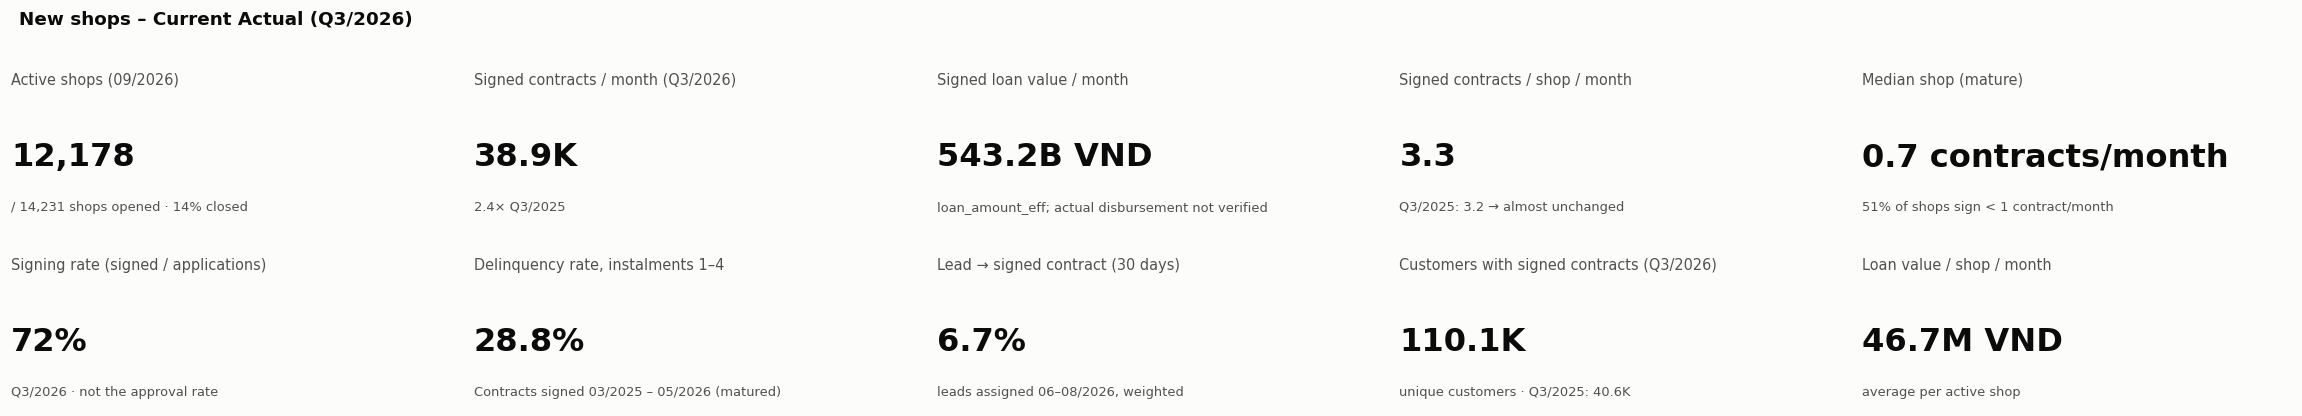

In [4]:
k = q(f'''SELECT
  (SELECT count(*) FROM shop WHERE m_close IS NULL OR m_close > DATE '2026-09-01') shop_open,
  (SELECT count(*) FROM shop) shop_all,
  sum(n_sign) / 3 sign_m, sum(amt) / 3 amt_m, sum(n_sign) / sum(n_app) sign_rate,
  sum(n_sign) / count(*) per_shop
FROM sm_perf WHERE m BETWEEN {Q3[0]} AND {Q3[1]}''').iloc[0]
k0 = q('''SELECT sum(n_sign) / count(*) per_shop, sum(n_sign) / 3 sign_m FROM sm_perf WHERE m BETWEEN DATE '2025-07-01' AND DATE '2025-09-01' ''').iloc[0]
c = q('SELECT median(sign_m) med, 100 * avg((sign_m < 1)::INT) lt1 FROM cur').iloc[0]
d = q('''SELECT 100 * avg(flag_any_dpd) dpd FROM ctr WHERE is_signed AND m_sign BETWEEN DATE '2025-03-01' AND DATE '2026-05-01' ''').iloc[0]
cu_ = q('''SELECT count(DISTINCT skp_client) FILTER (WHERE m_sign BETWEEN DATE '2026-07-01' AND DATE '2026-09-01') kh_q3,
                 count(DISTINCT skp_client) FILTER (WHERE m_sign BETWEEN DATE '2025-07-01' AND DATE '2025-09-01') kh_q3_25
          FROM ctr WHERE is_signed AND name_status <> 'Cancelled' AND skp_client > 0''').iloc[0]
lc = q('''SELECT 100 * sum(w) FILTER (WHERE converted_sign) / sum(w) conv FROM lds WHERE m BETWEEN DATE '2026-06-01' AND DATE '2026-08-01' ''').iloc[0]
tiles = [
    ('Shop đang hoạt động (09/2026)', f'{k.shop_open:,.0f}', f'/ {k.shop_all:,.0f} shop đã mở · {1 - k.shop_open / k.shop_all:.0%} đã đóng'),
    ('HĐ đã ký / tháng (Q3/2026)', human(k.sign_m), f'gấp {k.sign_m / k0.sign_m:.1f} lần Q3/2025'),
    ('Giá trị khoản vay đã ký / tháng', human(k.amt_m) + ' VND', 'loan_amount_eff; chưa xác minh giải ngân thực tế'),
    ('HĐ ký / shop / tháng', f'{k.per_shop:.1f}', f'Q3/2025: {k0.per_shop:.1f} → gần như không đổi'),
    ('Shop trung vị (trưởng thành)', f'{c.med:.1f} HĐ/tháng', f'{c.lt1:.0f}% shop ký < 1 HĐ/tháng'),
    ('Tỷ lệ ký (HĐ ký / hồ sơ)', f'{k.sign_rate:.0%}', 'Q3/2026 · không phải tỷ lệ duyệt'),
    ('Tỷ lệ trễ hạn kỳ 1–4', f'{d.dpd:.1f}%', 'HĐ ký 03/2025 – 05/2026 (đủ tuổi)'),
    ('Lead → HĐ ký (30 ngày)', f'{lc.conv:.1f}%', 'lead giao 06–08/2026, có trọng số'),
    ('Khách hàng có HĐ ký (Q3/2026)', human(cu_.kh_q3), f'khách duy nhất · Q3/2025: {human(cu_.kh_q3_25)}'),
    ('Giá trị khoản vay / shop / tháng', human(k.amt_m * 3 / (k.sign_m * 3 / k.per_shop)) + ' VND', 'trung bình mỗi shop đang hoạt động'),
]
fig, axes = plt.subplots(2, 5, figsize=(21, 3.8))
for ax, (t, v, s) in zip(axes.ravel(), tiles):
    ax.axis('off')
    ax.text(0, .80, t, fontsize=9.5, color=INK2, transform=ax.transAxes)
    ax.text(0, .32, v, fontsize=21, fontweight='bold', color=INK, transform=ax.transAxes)
    ax.text(0, .06, s, fontsize=8.5, color=INK2, transform=ax.transAxes)
fig.suptitle('Shop mới – Current Actual (Q3/2026)', x=0.01, ha='left', fontweight='bold', fontsize=12)
plt.tight_layout(); plt.show()

### 1.0 Mạng lưới shop chiếm bao nhiêu trong toàn công ty?
Bảng `salesroom` chỉ mô tả **shop vật lý mới** (Big / Medium / Small) và một ít shop ảo. Hợp đồng còn lại thuộc **5 online hub** (mỗi hub ≥ 50 nghìn HĐ thành công) và khoảng **15 nghìn POS ngoài danh sách shop** (không có thông tin shop).
Phần này đặt mạng lưới shop vào bức tranh toàn công ty; các mục sau chỉ phân tích shop vật lý.

> Giá trị = `loan_amount_eff` của HĐ thành công: CC luôn = 0 (thẻ chỉ có hạn mức), BNPL lấy từ hoá đơn kỳ đầu. Kênh nhiều CC/BNPL sẽ có tỷ trọng giá trị thấp hơn tỷ trọng HĐ.

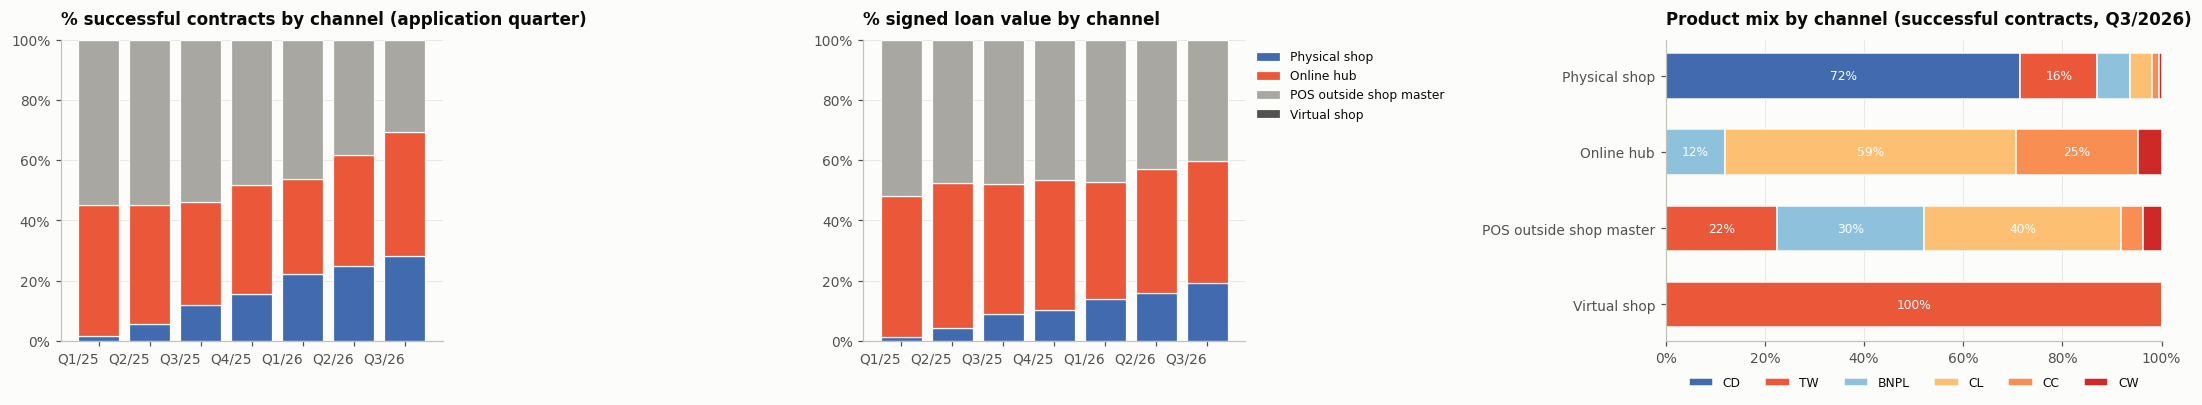

,HĐ/tháng Q3/26,% HĐ,Giá trị (tỷ/tháng),% giá trị,HĐ YoY,Giá trị YoY
kenh,,,,,,
Shop vật lý,"38,559",28.2%,537,19.1%,+144%,+197%
Online hub,"56,057",41.0%,"1,142",40.7%,+26%,+30%
POS ngoài danh sách shop,"42,059",30.8%,"1,127",40.2%,-40%,+15%
Shop ảo (Virtual),21,0.0%,0,0.0%,-76%,-69%


Q3/2026: shop vật lý chiếm 28% HĐ thành công và 19% giá trị khoản vay của toàn công ty; tỷ trọng HĐ của shop vật lý tăng từ 2% (Q1/2025) lên 28%.


In [5]:
chn = q(f'''WITH c AS (SELECT skp_salesroom, date_trunc('quarter', date_apply)::DATE qtr, coalesce(product, 'UNKNOWN') product, loan_amount_eff
                       FROM {rd('contract')} WHERE is_signed AND name_status <> 'Cancelled'),
                 k AS (SELECT skp_salesroom, count(*) n_all FROM c GROUP BY 1)
            SELECT CASE WHEN s.salesroom_category IN ('Big','Medium','Small') THEN 'Shop vật lý'
                        WHEN s.skp_salesroom IS NOT NULL THEN 'Shop ảo (Virtual)'
                        WHEN k.n_all >= 50000 THEN 'Online hub' ELSE 'POS ngoài danh sách shop' END kenh,
                   qtr, product, count(*) hd, sum(loan_amount_eff) gia_tri
            FROM c JOIN k USING (skp_salesroom) LEFT JOIN salesroom s USING (skp_salesroom) GROUP BY ALL''')
KCOL = {'Shop vật lý': BLUE, 'Online hub': ORANGE, 'POS ngoài danh sách shop': GREY, 'Shop ảo (Virtual)': INK2}
KORD = list(KCOL)
qt = chn.groupby(['qtr', 'kenh'])[['hd', 'gia_tri']].sum().unstack('kenh').sort_index()
sh_hd, sh_v = qt['hd'].reindex(columns=KORD).fillna(0), qt['gia_tri'].reindex(columns=KORD).fillna(0)
fig, ax = plt.subplots(1, 3, figsize=(20, 3.8), gridspec_kw={'width_ratios': [1, 1, 1.3]})
stack_bar(ax[0], sh_hd.div(sh_hd.sum(axis=1), axis=0) * 100, KCOL, '% HĐ thành công theo kênh (quý nộp)', pct=True)
stack_bar(ax[1], sh_v.div(sh_v.sum(axis=1), axis=0) * 100, KCOL, '% giá trị khoản vay đã ký theo kênh', pct=True)
ax[0].get_legend().remove()
for a in ax[:2]: a.set_xticks(range(len(qt)), [f'Q{(pd.Timestamp(i).month - 1) // 3 + 1}/{pd.Timestamp(i).year % 100}' for i in qt.index], rotation=0)
mx_ = chn[chn.qtr == pd.Timestamp('2026-07-01')].pivot_table(index='kenh', columns='product', values='hd', aggfunc='sum').reindex(KORD).fillna(0)
mx_ = mx_.div(mx_.sum(axis=1), axis=0); left = np.zeros(len(mx_)); y = np.arange(len(mx_))
for p_ in [p for p in ['CD', 'TW', 'BNPL', 'CL', 'CC', 'CW', 'UNKNOWN'] if p in mx_.columns]:
    ax[2].barh(y, mx_[p_], left=left, color={**PCOL, 'CW': RED}.get(p_, GREY), label=p_, height=.6, edgecolor=SURF)
    for yi, l_, v_ in zip(y, left, mx_[p_]):
        if v_ >= .08: ax[2].text(l_ + v_ / 2, yi, f'{v_:.0%}', ha='center', va='center', fontsize=8, color='white')
    left += mx_[p_].values
ax[2].set_yticks(y, mx_.index); ax[2].invert_yaxis(); ax[2].set_xlim(0, 1); ax[2].xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[2].grid(axis='y', visible=False); ax[2].legend(ncol=7, loc='upper center', bbox_to_anchor=(.5, -.08)); ax[2].set_title('Cơ cấu sản phẩm theo kênh (HĐ thành công, Q3/2026)')
plt.tight_layout(); plt.show()
t26 = chn[chn.qtr == pd.Timestamp('2026-07-01')].groupby('kenh')[['hd', 'gia_tri']].sum().reindex(KORD)
t25 = chn[chn.qtr == pd.Timestamp('2025-07-01')].groupby('kenh')[['hd', 'gia_tri']].sum().reindex(KORD)
tb_ch = pd.DataFrame({'HĐ/tháng Q3/26': t26.hd / 3, '% HĐ': t26.hd / t26.hd.sum(), 'Giá trị (tỷ/tháng)': t26.gia_tri / 3 / 1e9,
                      '% giá trị': t26.gia_tri / t26.gia_tri.sum(), 'HĐ YoY': t26.hd / t25.hd - 1, 'Giá trị YoY': t26.gia_tri / t25.gia_tri - 1})
display(tb_ch.style.format({'HĐ/tháng Q3/26': '{:,.0f}', '% HĐ': '{:.1%}', 'Giá trị (tỷ/tháng)': '{:,.0f}', '% giá trị': '{:.1%}',
                            'HĐ YoY': '{:+.0%}', 'Giá trị YoY': '{:+.0%}'}, na_rep='–'))
print(f"Q3/2026: shop vật lý chiếm {tb_ch.loc['Shop vật lý', '% HĐ']:.0%} HĐ thành công và {tb_ch.loc['Shop vật lý', '% giá trị']:.0%} giá trị khoản vay "
      f"của toàn công ty; tỷ trọng HĐ của shop vật lý tăng từ {sh_hd.iloc[0]['Shop vật lý'] / sh_hd.iloc[0].sum():.0%} (Q1/2025) lên "
      f"{sh_hd.iloc[-1]['Shop vật lý'] / sh_hd.iloc[-1].sum():.0%}.")

### 1.1 Q3 so với Q2/2026 trên cùng tập shop
Chỉ so các shop **đã mở trước 04/2026 và còn hoạt động hết 09/2026**, tức hoạt động đủ cả hai quý. Nhờ vậy chênh lệch không bị lẫn với hiệu ứng mở shop mới.
Số liệu tính theo quý nộp hồ sơ, theo tháng.

In [6]:
qq = q('''WITH sc AS (SELECT skp_salesroom FROM salesroom WHERE salesroom_start < DATE '2026-04-01'
                      AND (salesroom_end IS NULL OR salesroom_end >= DATE '2026-10-01')),
              x AS (SELECT CASE WHEN date_apply >= DATE '2026-07-01' THEN 'Q3/2026' ELSE 'Q2/2026' END quy, *
                    FROM ctr WHERE skp_salesroom IN (SELECT skp_salesroom FROM sc)
                      AND date_apply >= DATE '2026-04-01' AND date_apply < DATE '2026-10-01')
          SELECT quy,
                 (SELECT count(*) FROM sc) shop_trong_tap,
                 count(DISTINCT skp_salesroom) FILTER (WHERE is_signed AND name_status <> 'Cancelled') shop_co_HD,
                 count(*) / 3 ho_so_thang,
                 count(*) FILTER (WHERE is_signed AND name_status <> 'Cancelled') / 3 HD_thang,
                 sum(loan_amount_eff) FILTER (WHERE is_signed AND name_status <> 'Cancelled') / 3 / 1e9 gia_tri_ty_thang,
                 sum(loan_amount_eff) FILTER (WHERE is_signed AND name_status <> 'Cancelled' AND product <> 'CC')
                   / count(*) FILTER (WHERE is_signed AND name_status <> 'Cancelled' AND product <> 'CC') / 1e6 khoan_vay_BQ_tr,
                 avg((is_signed AND name_status <> 'Cancelled')::INT) ty_le_ky,
                 avg((name_status = 'Rejected')::INT) ty_le_tu_choi
          FROM x GROUP BY 1 ORDER BY 1''').set_index('quy').T
qq.loc['HD_moi_shop_co_HD'] = qq.loc['HD_thang'] / qq.loc['shop_co_HD']
qq.loc['HD_moi_shop_trong_tap'] = qq.loc['HD_thang'] / qq.loc['shop_trong_tap']
qq['Thay đổi'] = qq['Q3/2026'] / qq['Q2/2026'] - 1
display(qq.round(3))
print(f"Cùng tập {qq.loc['shop_trong_tap', 'Q3/2026']:,.0f} shop: HĐ ký/tháng {qq.loc['HD_thang', 'Thay đổi']:+.1%}, "
      f"giá trị khoản vay đã ký {qq.loc['gia_tri_ty_thang', 'Thay đổi']:+.1%}, khoản vay BQ {qq.loc['khoan_vay_BQ_tr', 'Thay đổi']:+.1%}, "
      f"số shop có HĐ {qq.loc['shop_co_HD', 'Thay đổi']:+.1%}.")

quy,Q2/2026,Q3/2026,Thay đổi
shop_trong_tap,"7,573.00","7,573.00",0.00
shop_co_HD,"5,041.00","4,972.00",-0.01
ho_so_thang,"35,385.67","35,235.67",-0.00
HD_thang,"24,992.33","25,697.00",0.03
gia_tri_ty_thang,338.89,362.16,0.07
khoan_vay_BQ_tr,14.15,14.27,0.01
ty_le_ky,0.71,0.73,0.03
ty_le_tu_choi,0.22,0.20,-0.12
HD_moi_shop_co_HD,4.96,5.17,0.04
HD_moi_shop_trong_tap,3.30,3.39,0.03


Cùng tập 7,573 shop: HĐ ký/tháng +2.8%, giá trị khoản vay đã ký +6.9%, khoản vay BQ +0.8%, số shop có HĐ -1.4%.


### 1.2 Trạng thái hoạt động thực tế của shop (cuối Q3/2026)
Tách các shop "không có HĐ" thành các trường hợp **cần hành động khác nhau**:

| Trạng thái | Định nghĩa |
|---|---|
| Đã đóng | có ngày đóng ≤ 30/09/2026 |
| Mới mở | mở từ 07/2026, chưa đủ một quý để đánh giá |
| Chưa từng có HĐ | đang mở, chưa có HĐ ký nào kể từ khi mở |
| Ngừng phát sinh | từng có HĐ nhưng 0 HĐ trong Q3/2026 |
| Đang suy giảm | có HĐ trong Q3 nhưng giảm > 30% so với Q2 (Q2 ≥ 1 HĐ/tháng) |
| Đang bán đều / tăng | còn lại |

,shop,HD_thang_Q3,HD_thang_Q2,% shop,% HĐ Q3
trang_thai,,,,,
1. Đã đóng,2053,517.67,"1,809.00",0.14,0.01
2. Mới mở (từ 07/2026),2184,"3,929.00",0.00,0.15,0.10
3. Chưa từng có HĐ,1709,0.00,0.00,0.12,0.00
4. Ngừng phát sinh,1624,0.00,643.00,0.11,0.00
5. Đang suy giảm,1236,"3,245.67","6,802.00",0.09,0.08
6. Đang bán đều / tăng,5425,"30,887.00","21,506.00",0.38,0.80


model,Aldi,Non-Aldi
trang_thai,,
1. Đã đóng,0.21,0.11
2. Mới mở (từ 07/2026),0.15,0.15
3. Chưa từng có HĐ,0.16,0.10
4. Ngừng phát sinh,0.09,0.13
5. Đang suy giảm,0.06,0.10
6. Đang bán đều / tăng,0.33,0.41


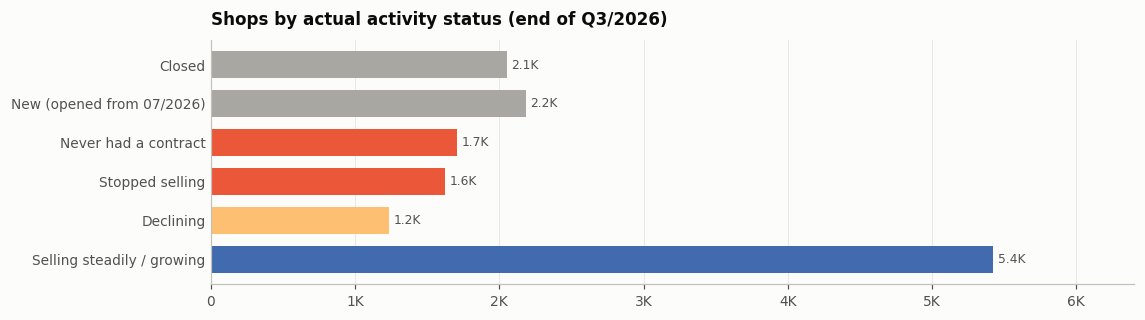

In [7]:
stt = q('''WITH ok AS (SELECT skp_salesroom, date_apply FROM ctr WHERE is_signed AND name_status <> 'Cancelled'),
                a AS (SELECT s.skp_salesroom, s.salesroom_start st, s.salesroom_end en, s.salesroom_model model,
                             count(o.date_apply) n_all,
                             count(o.date_apply) FILTER (WHERE o.date_apply >= DATE '2026-07-01' AND o.date_apply < DATE '2026-10-01') / 3 q3,
                             count(o.date_apply) FILTER (WHERE o.date_apply >= DATE '2026-04-01' AND o.date_apply < DATE '2026-07-01') / 3 q2
                      FROM salesroom s LEFT JOIN ok o USING (skp_salesroom) GROUP BY ALL)
           SELECT *, CASE
                WHEN en IS NOT NULL AND en <= TIMESTAMP '2026-09-30 23:59:59' THEN '1. Đã đóng'
                WHEN st >= DATE '2026-07-01' THEN '2. Mới mở (từ 07/2026)'
                WHEN n_all = 0 THEN '3. Chưa từng có HĐ'
                WHEN q3 = 0 THEN '4. Ngừng phát sinh'
                WHEN q2 >= 1 AND q3 < 0.7 * q2 THEN '5. Đang suy giảm'
                ELSE '6. Đang bán đều / tăng' END trang_thai
           FROM a''')
tb = stt.groupby('trang_thai').agg(shop=('skp_salesroom', 'size'), HD_thang_Q3=('q3', 'sum'), HD_thang_Q2=('q2', 'sum'))
tb['% shop'] = tb.shop / tb.shop.sum(); tb['% HĐ Q3'] = tb.HD_thang_Q3 / tb.HD_thang_Q3.sum()
display(tb.round(3))
display(pd.crosstab(stt.trang_thai, stt.model, normalize='columns').round(3))
fig, ax = plt.subplots(figsize=(10, 3))
barh(ax, tb.index.str[3:], tb.shop, 'Số shop theo trạng thái hoạt động thực tế (cuối Q3/2026)', color=[GREY, GREY, ORANGE, ORANGE, YELLOW, BLUE])
plt.tight_layout(); plt.show()

## 2. Mạng lưới shop: mở mới, đóng cửa, cơ cấu
Địa lý (vùng, tỉnh) và loại hình shop chỉ là thông tin nền, đã chuyển xuống **Phụ lục A**.

### 2.1 Tốc độ mở shop theo tháng

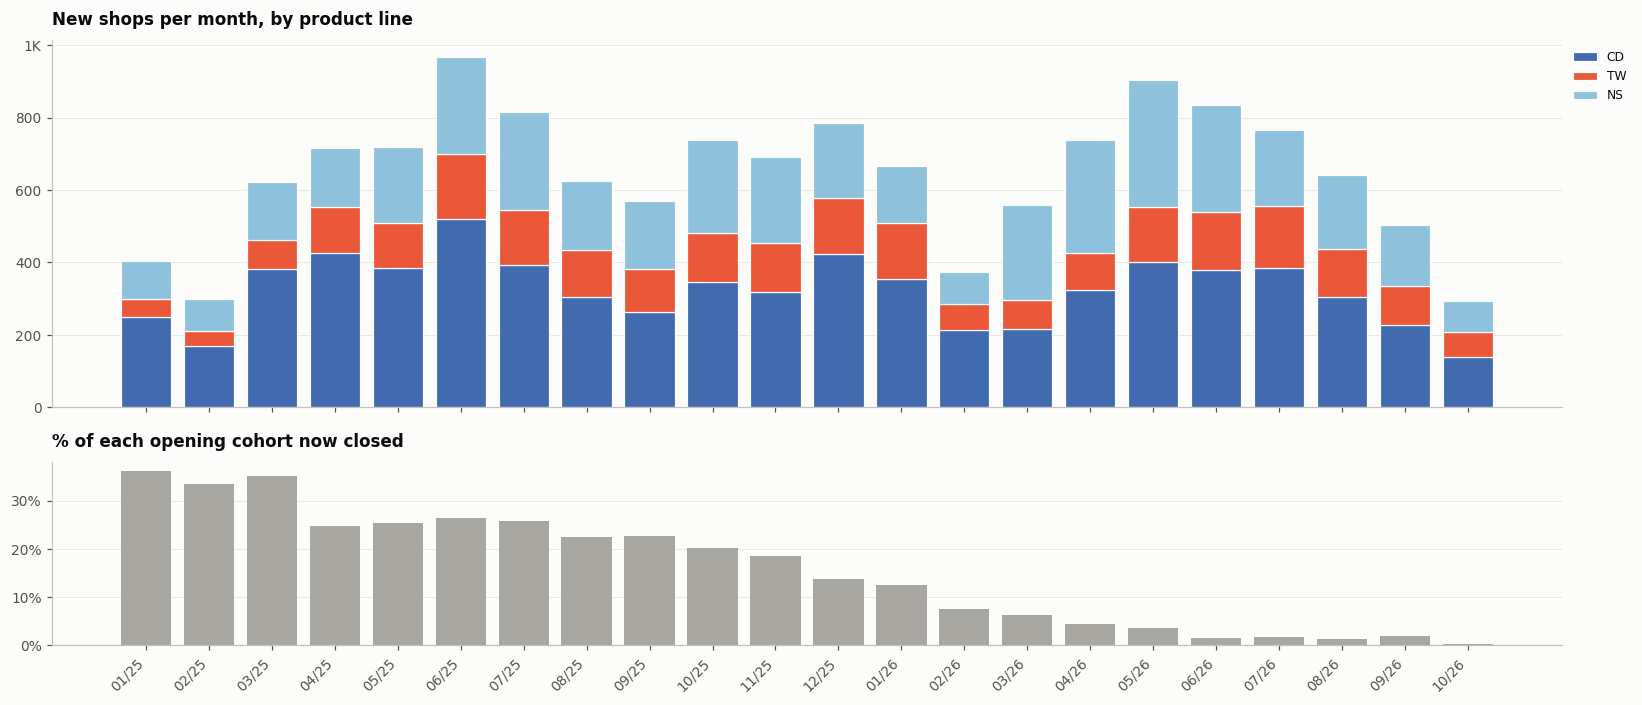

In [8]:
op = q('''SELECT date_trunc('month', salesroom_start)::DATE thang,
                 CASE WHEN salesroom_product IN ('CD','TW','NS') THEN salesroom_product ELSE 'Khác' END line, count(*) n
          FROM salesroom GROUP BY ALL''')
piv = op.pivot(index='thang', columns='line', values='n').sort_index()
piv = piv[[c for c in ['CD', 'TW', 'NS', 'Khác'] if c in piv]]
cl = q('''SELECT date_trunc('month', salesroom_start)::DATE thang, 100 * avg(is_closed::INT) closed FROM salesroom GROUP BY 1 ORDER BY 1''')
fig, ax = plt.subplots(2, 1, figsize=(15, 6.5), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
stack_bar(ax[0], piv, LCOL, 'Số shop mở mới mỗi tháng, theo dòng hàng')
ax[1].bar(range(len(cl)), cl.closed, color=GREY, width=.8)
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax[1].grid(axis='x', visible=False)
ax[1].set_title('% shop của mỗi lứa (tháng mở) hiện đã đóng cửa')
month_axis(ax[1], cl.thang)
plt.tight_layout(); plt.show()

### 2.2 Mạng lưới theo tháng: mở mới, đóng cửa, mở ròng và % shop có phát sinh HĐ
- **Shop đang mở** cuối tháng = đã mở và chưa đóng.
- **% shop có phát sinh HĐ** = trong số shop đang mở, bao nhiêu shop có ≥ 1 HĐ ký trong tháng.

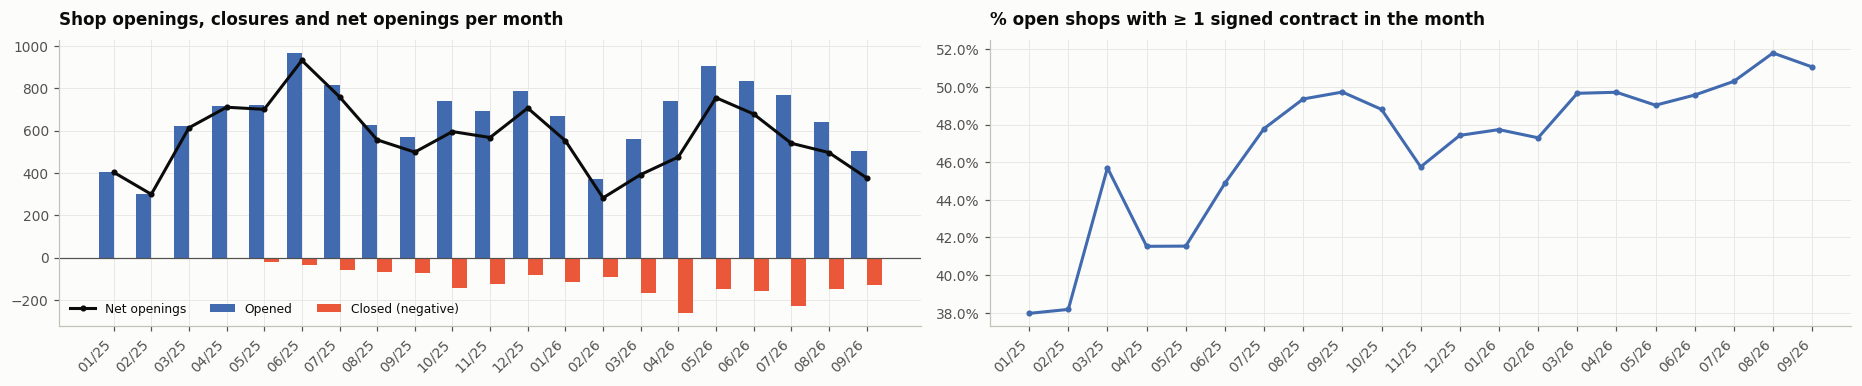

,mo,dong,mo_rong,dang_mo,shop_co_hd,pct_co_hd
m,,,,,,
2026-04-01,738,263,475,9038,4494,0.50
2026-05-01,905,150,755,9793,4802,0.49
2026-06-01,835,157,678,10471,5191,0.50
2026-07-01,766,226,540,11011,5539,0.50
2026-08-01,642,146,496,11507,5962,0.52
2026-09-01,504,127,377,11884,6069,0.51


In [9]:
nw = q('''WITH m AS (SELECT unnest(generate_series(DATE '2025-01-01', DATE '2026-09-01', INTERVAL 1 MONTH))::DATE m),
              op AS (SELECT date_trunc('month', salesroom_start)::DATE m, count(*) mo FROM salesroom GROUP BY 1),
              cl AS (SELECT date_trunc('month', salesroom_end)::DATE m, count(*) dong FROM salesroom WHERE salesroom_end IS NOT NULL GROUP BY 1),
              ac AS (SELECT m.m, count(*) dang_mo FROM m JOIN salesroom s ON date_trunc('month', s.salesroom_start) <= m.m
                         AND (s.salesroom_end IS NULL OR date_trunc('month', s.salesroom_end) > m.m) GROUP BY 1),
              hd AS (SELECT m_sign m, count(DISTINCT skp_salesroom) shop_co_hd FROM ctr WHERE is_signed AND name_status <> 'Cancelled' GROUP BY 1)
          SELECT m.m, coalesce(mo, 0) mo, coalesce(dong, 0) dong, coalesce(mo, 0) - coalesce(dong, 0) mo_rong, dang_mo, coalesce(shop_co_hd, 0) shop_co_hd
          FROM m LEFT JOIN op USING (m) LEFT JOIN cl USING (m) LEFT JOIN ac USING (m) LEFT JOIN hd USING (m) ORDER BY 1''')
nw['pct_co_hd'] = nw.shop_co_hd / nw.dang_mo
fig, ax = plt.subplots(1, 2, figsize=(17, 3.6))
x = np.arange(len(nw)); lab = [pd.Timestamp(m).strftime('%m/%y') for m in nw.m]
ax[0].bar(x - .2, nw.mo, .4, color=BLUE, label='Mở mới'); ax[0].bar(x + .2, -nw.dong, .4, color=ORANGE, label='Đóng cửa (âm)')
ax[0].plot(x, nw.mo_rong, color=INK, marker='o', ms=3, label='Mở ròng'); ax[0].axhline(0, color=INK2, lw=.8)
ax[0].set_xticks(x, lab, rotation=45, ha='right'); ax[0].legend(ncol=3); ax[0].set_title('Shop mở mới, đóng cửa và mở ròng mỗi tháng')
ax[1].plot(x, nw.pct_co_hd, color=BLUE, marker='o', ms=3); ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[1].set_xticks(x, lab, rotation=45, ha='right'); ax[1].set_title('% shop đang mở có phát sinh HĐ ký trong tháng')
plt.tight_layout(); plt.show()
display(nw.tail(6).set_index('m').round(3))

### 2.3 Cơ cấu: tỷ trọng shop, HĐ ký và giá trị khoản vay (Q3/2026)
Shop = shop vật lý đang mở cuối 09/2026. HĐ và giá trị là HĐ thành công của hồ sơ nộp trong Q3/2026, tính theo tháng.
Riêng theo sản phẩm thì không có cột "% shop", vì một shop bán nhiều sản phẩm.

% shop  % hd  % gia_tri        hd  gia_tri_ty  khoan_vay_BQ_tr
chieu            nhom                                                                         
Loại đối tác     Stone Shop       0.84  0.69       0.69 26,637.00      369.39            13.87
                 Key Account      0.02  0.11       0.09  4,097.67       46.06            11.24
                 NS KA            0.10  0.09       0.10  3,644.00       54.36            14.92
                 Local Partner    0.02  0.06       0.05  2,344.33       27.64            11.79
                 TW Key Dealer    0.02  0.05       0.07  1,856.33       39.75            21.41
                 Không rõ         0.00   NaN        NaN       NaN         NaN              NaN
Mô hình cửa hàng Non-Aldi         0.70  0.68       0.70 26,322.33      378.79            14.39
                 Aldi             0.30  0.32       0.29 12,257.00      158.41            12.92
Sản phẩm         CD                NaN  0.71       0.58 27,584.67      314.14            11.39
                 TW                NaN  0.15       0.24  5,998.00      129.12            21.53
                 BNPL              NaN  0.07       0.03  2,574.33       17.27             6.71
                 CL                NaN  0.04       0.14  1,688.33       72.39            42.88
                 CC                NaN  0.01        NaN    537.67         NaN              NaN
                 CW                NaN  0.01       0.01    196.33        4.27            21.76
Vùng             Sai Gon          0.14  0.19       0.21  7,211.00      111.90            15.52
                 North            0.16  0.15       0.15  5,692.00       82.26            14.45
                 Central - NHL    0.11  0.10       0.09  3,941.00       49.09            12.46
                 Eastern South    0.07  0.10       0.10  3,829.67       53.87            14.07
                 North East       0.15  0.10       0.09  3,693.33       49.10            13.29
                 Western          0.09  0.09       0.09  3,600.67       47.14            13.09
                 Mekong           0.06  0.09       0.08  3,271.67       44.83            13.70
                 Eastern North    0.07  0.07       0.07  2,906.33       36.46            12.54
                 South East       0.07  0.06       0.08  2,479.00       41.06            16.57
                 North West       0.07  0.05       0.04  1,954.67       21.49            10.99

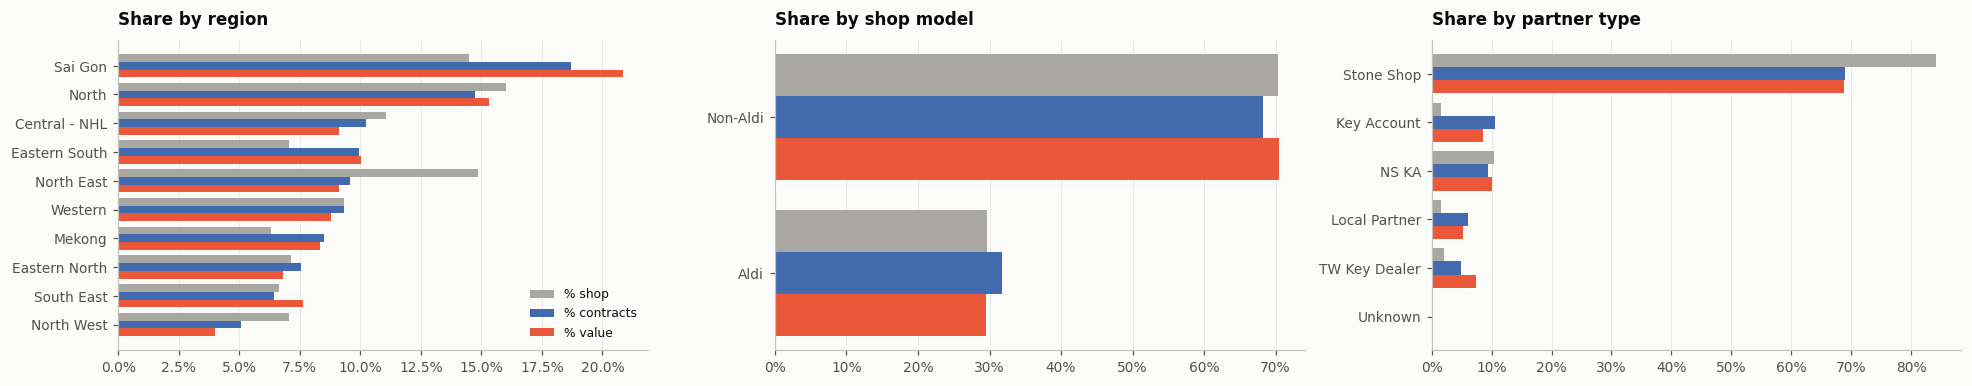

In [10]:
base_ = '''FROM ctr c JOIN salesroom s USING (skp_salesroom)
           WHERE c.is_signed AND c.name_status <> 'Cancelled' AND c.date_apply >= DATE '2026-07-01' AND c.date_apply < DATE '2026-10-01' '''
open_ = '''FROM salesroom WHERE salesroom_category <> 'Virtual' AND (salesroom_end IS NULL OR salesroom_end >= DATE '2026-10-01') '''
def mix(dim_ctr, dim_shop, name):
    a = q(f"SELECT {dim_ctr} nhom, count(*) / 3 hd, sum(c.loan_amount_eff) / 3 gia_tri {base_} GROUP BY 1")
    if dim_shop:
        b = q(f"SELECT {dim_shop} nhom, count(*) shop {open_} GROUP BY 1"); a = a.merge(b, on='nhom', how='outer')
    a.insert(0, 'chieu', name)
    return a
tb_mix = pd.concat([mix("coalesce(c.product, 'UNKNOWN')", None, 'Sản phẩm'),
                    mix('s.salesroom_area', 'salesroom_area', 'Vùng'),
                    mix('s.salesroom_model', 'salesroom_model', 'Mô hình cửa hàng'),
                    mix("coalesce(s.seller_type, 'Không rõ')", "coalesce(seller_type, 'Không rõ')", 'Loại đối tác')])
for col_ in ['shop', 'hd', 'gia_tri']:
    tb_mix['% ' + col_] = tb_mix[col_] / tb_mix.groupby('chieu')[col_].transform('sum')
tb_mix['khoan_vay_BQ_tr'] = tb_mix.gia_tri / tb_mix.hd / 1e6
tb_mix['gia_tri_ty'] = tb_mix.gia_tri / 1e9
show_ = tb_mix[['chieu', 'nhom', '% shop', '% hd', '% gia_tri', 'hd', 'gia_tri_ty', 'khoan_vay_BQ_tr']].sort_values(['chieu', 'hd'], ascending=[True, False])
with pd.option_context('display.max_rows', 60):
    display(show_.set_index(['chieu', 'nhom']).round(3))
fig, axes = plt.subplots(1, 3, figsize=(18, 3.6))
for a_, dim_ in zip(axes, ['Vùng', 'Mô hình cửa hàng', 'Loại đối tác']):
    t_ = tb_mix[tb_mix.chieu == dim_].sort_values('% hd', ascending=False)
    y_ = np.arange(len(t_)); w_ = .27
    for k_, (col_, c_, l_) in enumerate([('% shop', GREY, '% shop'), ('% hd', BLUE, '% HĐ'), ('% gia_tri', ORANGE, '% giá trị')]):
        a_.barh(y_ + (k_ - 1) * w_, t_[col_].fillna(0), w_, color=c_, label=l_)
    a_.set_yticks(y_, t_.nhom); a_.invert_yaxis(); a_.xaxis.set_major_formatter(mtick.PercentFormatter(1)); a_.grid(axis='y', visible=False)
    a_.set_title(f'Tỷ trọng theo {dim_.lower()}')
axes[0].legend(loc='lower right')
plt.tight_layout(); plt.show()

## 3. Kết quả theo thời gian: quy mô và tốc độ tăng
3.1–3.3 nhìn toàn mạng lưới; 3.4–3.6 tách cùng các chỉ số đó theo **phân khúc lớn** và **vòng đời shop** để biết tăng trưởng đến từ đâu.
### 3.1 Số hồ sơ, HĐ ký & tỷ lệ ký theo tháng

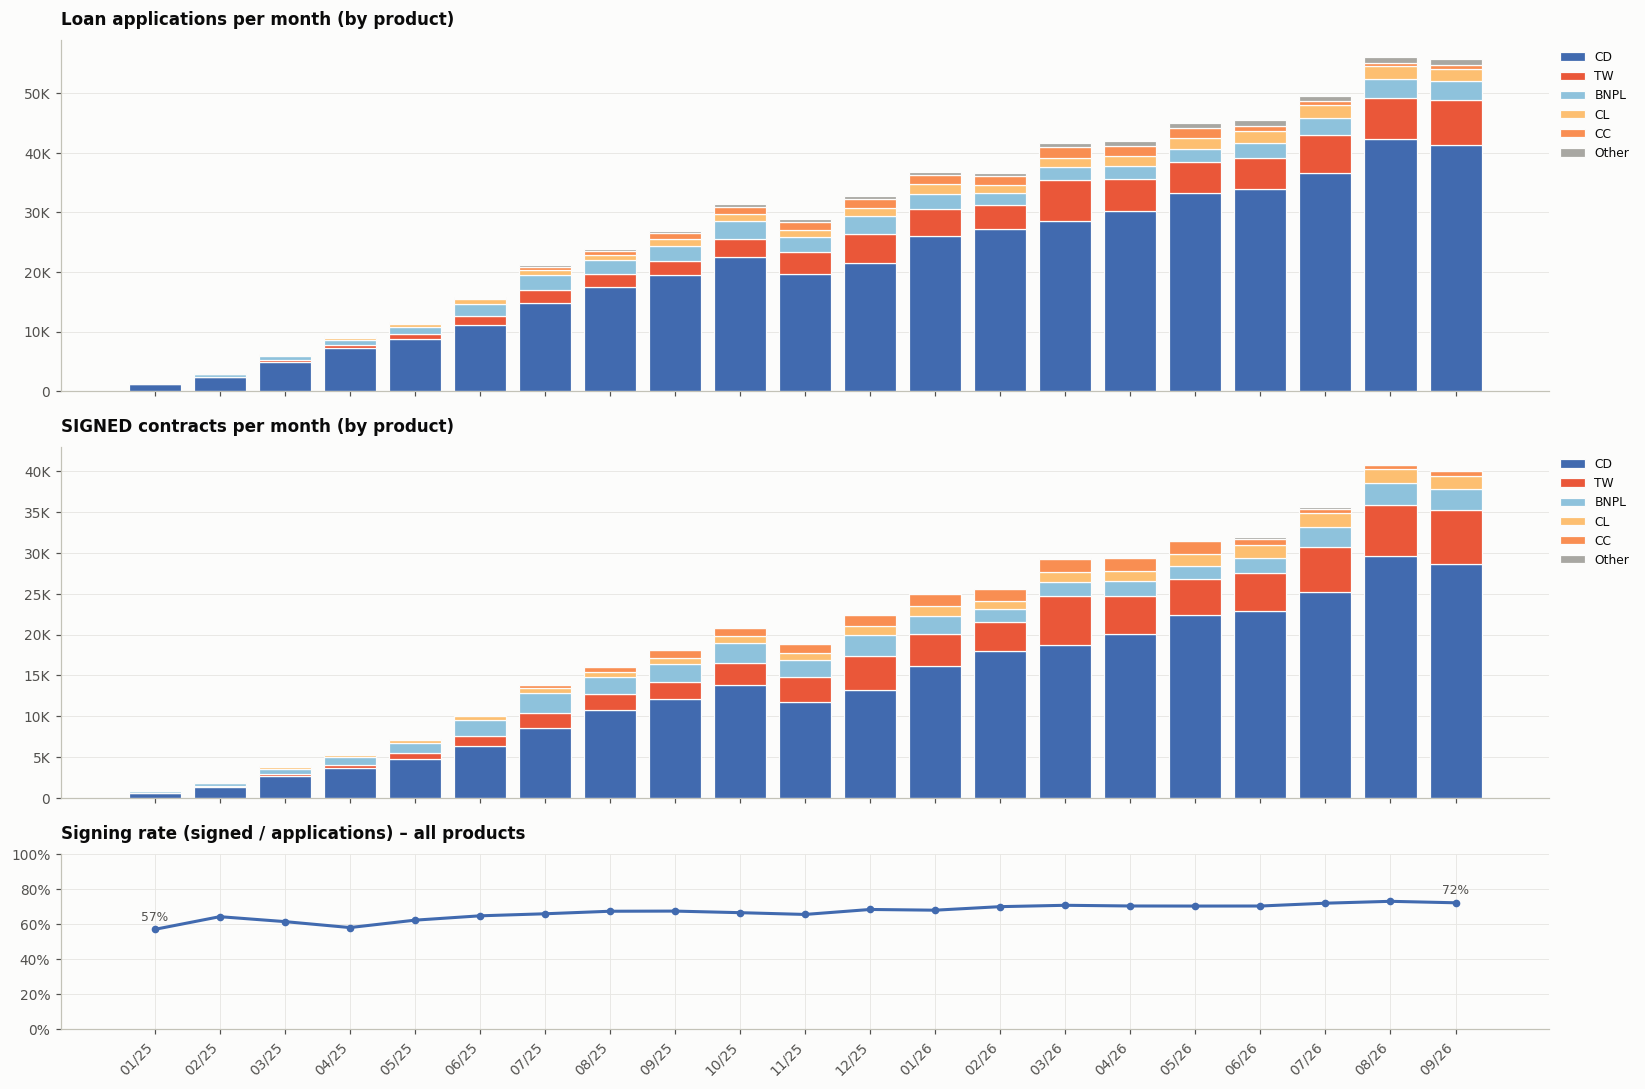

In [11]:
m = q('''SELECT thang, prod, count(*) n_app, count(*) FILTER (WHERE is_signed) n_sign,
                sum(loan_amount_eff) FILTER (WHERE is_signed) amt FROM ctr GROUP BY ALL''')
app = m.pivot(index='thang', columns='prod', values='n_app').sort_index()[[p for p in PORDER if p in m['prod'].values]]
sig = m.pivot(index='thang', columns='prod', values='n_sign').sort_index()[app.columns]
rate = (sig.sum(axis=1) / app.sum(axis=1) * 100)
fig, ax = plt.subplots(3, 1, figsize=(15, 10), sharex=True, gridspec_kw={'height_ratios': [2, 2, 1]})
stack_bar(ax[0], app, PCOL, 'Số hồ sơ vay mỗi tháng (theo sản phẩm)')
stack_bar(ax[1], sig, PCOL, 'Số hợp đồng ĐÃ KÝ mỗi tháng (theo sản phẩm)')
ax[2].plot(range(len(rate)), rate.values, color=BLUE, marker='o', markersize=4)
ax[2].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax[2].set_ylim(0, 100)
ax[2].set_title('Tỷ lệ ký (HĐ đã ký / hồ sơ) – toàn bộ sản phẩm')
for i in [0, len(rate) - 1]:
    ax[2].annotate(f'{rate.iloc[i]:.0f}%', (i, rate.iloc[i]), xytext=(0, 6), textcoords='offset points', ha='center', fontsize=8, color=INK2)
month_axis(ax[2], rate.index)
plt.tight_layout(); plt.show()

#### Giá trị khoản vay đã ký theo tháng (VND, không gồm CC)

> Dùng **giá trị khoản vay đã ký** (`loan_amount_eff`), không gọi là "giải ngân": dữ liệu không xác nhận tiền đã được giải ngân thực tế.

> **Không vẽ CC** vì `credit_amount` của mọi hợp đồng thẻ tín dụng (CC) đều **= 0**: thẻ chỉ có hạn mức, không có số tiền vay trên hợp đồng. Nếu đưa vào, CC sẽ hiện là 0 dù thực tế có rất nhiều hợp đồng. Số lượng hợp đồng CC xem ở mục 4.1.

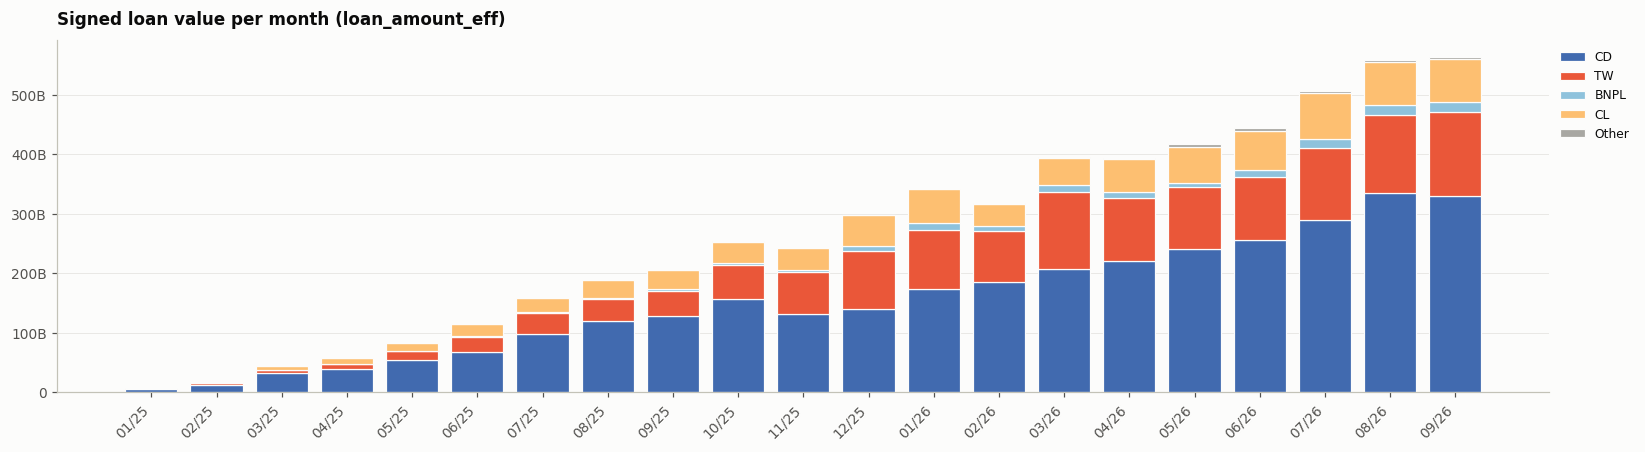

In [12]:
amt = m[m['prod'] != 'CC'].pivot(index='thang', columns='prod', values='amt').sort_index()
amt = amt[[p for p in PORDER if p in amt.columns]]
fig, ax = plt.subplots(figsize=(15, 4.2))
stack_bar(ax, amt, PCOL, 'Giá trị khoản vay đã ký mỗi tháng (loan_amount_eff)')
plt.tight_layout(); plt.show()

### 3.2 Tốc độ tăng trưởng: MoM, YoY và QoQ
Tính trên **HĐ đã ký theo tháng ký**. Các tháng đầu 2025 có nền rất nhỏ nên MoM chỉ vẽ từ **07/2025**.

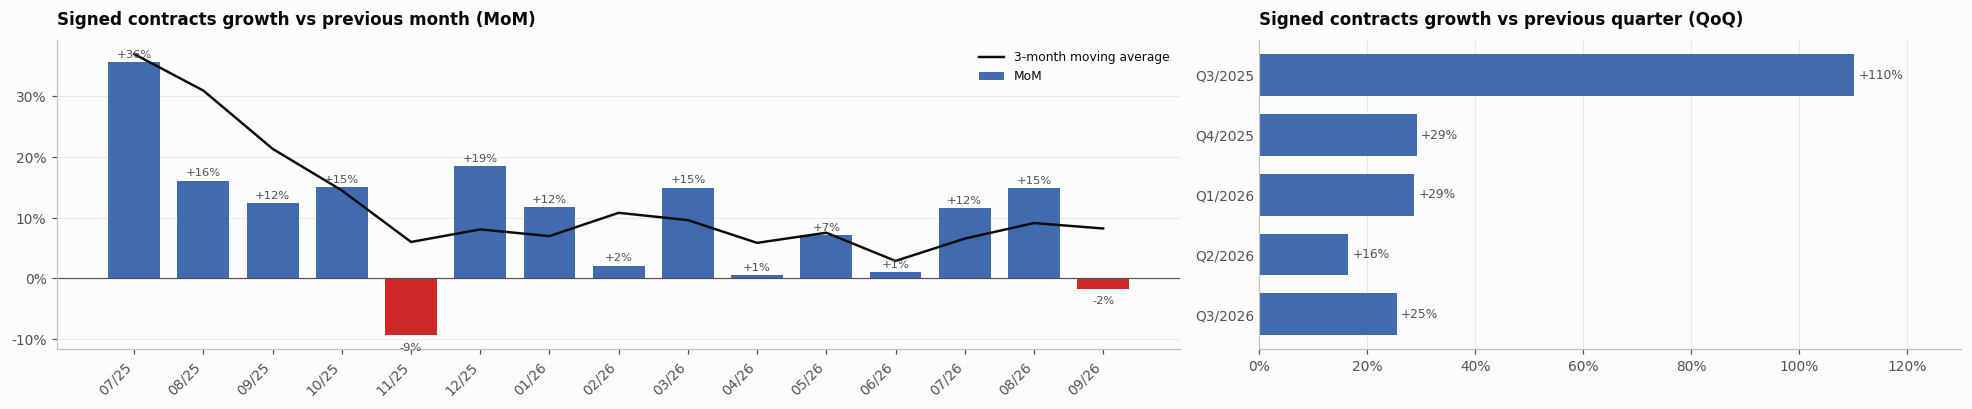

Tăng trưởng QoQ (%) theo sản phẩm – HĐ ký:


prod,CD,TW,BNPL,CL,CC,Khác,Tổng
Q2/2025,213.50,642.50,254.40,314.70,137.50,NaN,241.60
Q3/2025,112.40,155.30,59.60,86.60,325.30,inf,110.20
Q4/2025,22.60,77.50,2.20,40.30,72.10,78.10,29.10
Q1/2026,36.70,31.70,-18.00,20.90,29.70,84.20,28.70
Q2/2026,23.30,3.20,-5.40,26.40,-13.20,370.50,16.40
Q3/2026,28.00,32.60,44.10,18.50,-58.80,19.00,25.40


YoY 09/2026: +122% (nền 2025 rất nhỏ nên YoY không dùng để so sánh) · MoM trung bình 07/2025–09/2026: +10.0% · độ lệch chuẩn 10.7 điểm % · số tháng giảm: 2 / 15 · MoM TB 2026: +6.9%


In [13]:
gm = q('''SELECT m_sign m, count(*) n_sign, sum(loan_amount_eff) amt FROM ctr
          WHERE is_signed AND m_sign <= DATE '2026-09-01' GROUP BY 1 ORDER BY 1''')
gm['mom'] = gm.n_sign.pct_change() * 100
gm['mom_amt'] = gm.amt.pct_change() * 100
gm['yoy'] = gm.n_sign.pct_change(12) * 100
gm['mom_3m'] = gm.mom.rolling(3).mean()
v = gm[gm.m >= pd.Timestamp('2025-07-01')].reset_index(drop=True)
x = np.arange(len(v)); lab = [pd.Timestamp(m).strftime('%m/%y') for m in v.m]
fig, ax = plt.subplots(1, 2, figsize=(18, 3.8), gridspec_kw={'width_ratios': [1.6, 1]})
ax[0].bar(x, v.mom, color=[BLUE if y >= 0 else RED for y in v.mom], width=.75, label='MoM')
ax[0].plot(x, v.mom_3m, color=INK, lw=1.6, label='TB trượt 3 tháng')
ax[0].axhline(0, color=INK2, lw=.8)
for xi, y in zip(x, v.mom):
    ax[0].annotate(f'{y:+.0f}%', (xi, y), xytext=(0, 3 if y >= 0 else -10), textcoords='offset points', ha='center', fontsize=7.5, color=INK2)
ax[0].set_xticks(x, lab, rotation=45, ha='right'); ax[0].grid(axis='x', visible=False)
ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v_, _: f'{v_:.0f}%')); ax[0].legend(loc='upper right')
ax[0].set_title('Tăng trưởng HĐ ký so với tháng trước (MoM)')
qq = q('''SELECT date_trunc('quarter', m_sign)::DATE qtr, prod, count(*) n FROM ctr
          WHERE is_signed AND m_sign <= DATE '2026-09-01' GROUP BY ALL''').pivot(index='qtr', columns='prod', values='n').fillna(0)
qq['Tổng'] = qq.sum(axis=1)
qoq = (qq.pct_change() * 100).round(1)
qoq.index = [f'Q{(pd.Timestamp(i).month - 1) // 3 + 1}/{pd.Timestamp(i).year}' for i in qoq.index]
t_ = qoq['Tổng'].iloc[2:]
barh(ax[1], t_.index, t_.values, 'Tăng trưởng HĐ ký so với quý trước (QoQ)', pct=True, fmt=lambda v_: f'{v_:+.0f}%')
plt.tight_layout(); plt.show()

print('Tăng trưởng QoQ (%) theo sản phẩm – HĐ ký:')
display(qoq.iloc[1:][[c for c in PORDER + ['Tổng'] if c in qoq.columns]])
st6 = v[v.m >= pd.Timestamp('2026-01-01')]
print(f"YoY 09/2026: {gm.yoy.iloc[-1]:+.0f}% (nền 2025 rất nhỏ nên YoY không dùng để so sánh) · MoM trung bình 07/2025–09/2026: {v.mom.mean():+.1f}% · độ lệch chuẩn {v.mom.std():.1f} điểm % · "
      f"số tháng giảm: {(v.mom < 0).sum()} / {len(v)} · MoM TB 2026: {st6.mom.mean():+.1f}%")

#### Bảng tăng trưởng cho cả số HĐ và giá trị khoản vay đã ký
- MoM = so với tháng trước · QoQ = so với quý trước · YoY = so với cùng kỳ năm trước.
- Tính trên HĐ thành công theo tháng ký, toàn bộ shop mới.
- Tăng trưởng gồm cả hiệu ứng **mở thêm shop**; tách hiệu ứng này xem mục 3.3 và mục 1.1.

In [14]:
gv = q('''SELECT m_sign m, count(*) hd, sum(loan_amount_eff) gia_tri FROM ctr
          WHERE is_signed AND name_status <> 'Cancelled' AND m_sign <= DATE '2026-09-01' GROUP BY 1 ORDER BY 1''').set_index('m')
mom = gv.pct_change().tail(6); mom.index = [pd.Timestamp(i).strftime('%m/%Y') for i in mom.index]
gq = gv.groupby(pd.PeriodIndex(gv.index, freq='Q')).sum()
qoq_ = gq.pct_change().tail(4); yoy_ = gq.pct_change(4).tail(3)
qoq_.index = [str(i) for i in qoq_.index]; yoy_.index = [str(i) for i in yoy_.index]
gr = pd.concat({'MoM (6 tháng gần nhất)': mom, 'QoQ (4 quý gần nhất)': qoq_, 'YoY (quý so với cùng quý năm trước)': yoy_})
gr.columns = ['Số HĐ', 'Giá trị khoản vay']
display(gr.style.format('{:+.1%}'))

### 3.3 Tăng trưởng đến từ đâu? Hiệu ứng mạng lưới vs hiệu ứng năng suất
Tổng HĐ ký = **số shop hoạt động × HĐ ký mỗi shop**. Chênh lệch giữa 2 quý được tách thành:
- **Hiệu ứng mạng lưới** = (số shop tăng thêm) × năng suất quý trước
- **Hiệu ứng năng suất** = số shop quý này × (thay đổi năng suất)

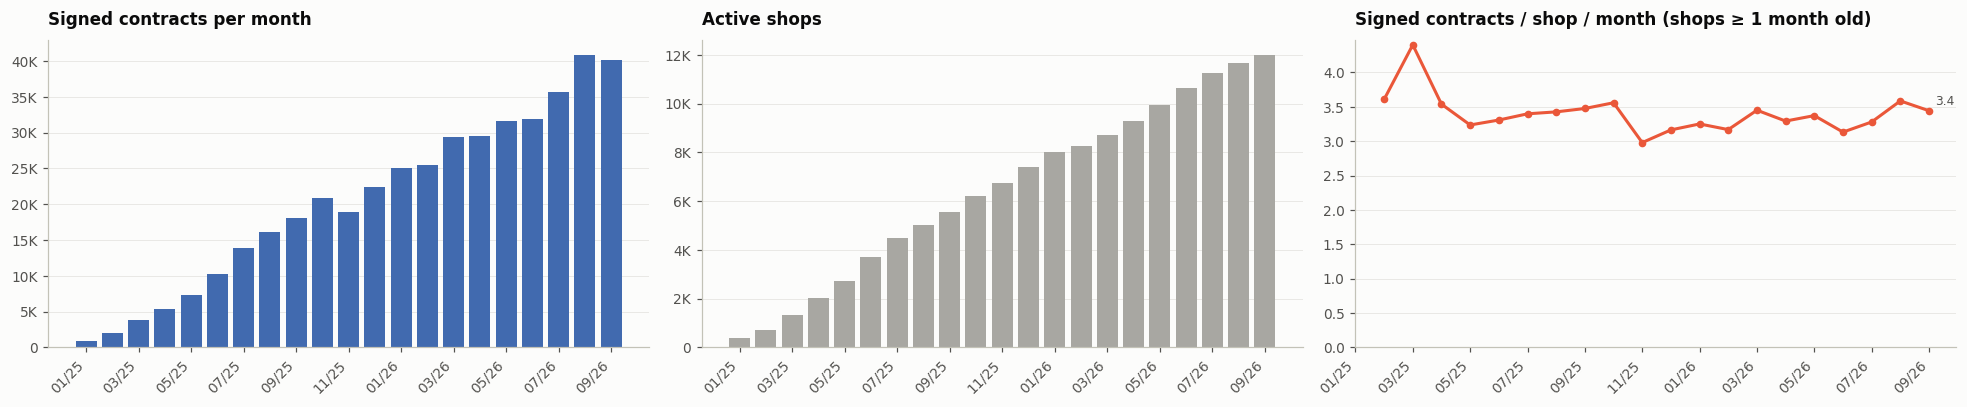

,m,n_shop,n_sign,per_shop,per_shop_mature
6,2025-07-01,4471,"13,875.00",3.10,3.40
12,2026-01-01,8004,"25,005.00",3.12,3.25
18,2026-07-01,11237,"35,610.00",3.17,3.28
20,2026-09-01,12011,"40,205.00",3.35,3.44


In [15]:
g = q('''SELECT m, count(*) n_shop, sum(n_sign) n_sign, sum(n_sign) / count(*) per_shop,
                sum(n_sign) FILTER (WHERE age >= 1) / count(*) FILTER (WHERE age >= 1) per_shop_mature
         FROM sm_perf GROUP BY 1 ORDER BY 1''')
x = np.arange(len(g)); lab = [pd.Timestamp(m).strftime('%m/%y') for m in g.m]
fig, ax = plt.subplots(1, 3, figsize=(18, 3.8))
ax[0].bar(x, g.n_sign, color=BLUE, width=.8); ax[0].set_title('HĐ đã ký mỗi tháng')
ax[1].bar(x, g.n_shop, color=GREY, width=.8); ax[1].set_title('Số shop đang hoạt động')
ax[2].plot(x, g.per_shop_mature, color=ORANGE, marker='o', ms=4); ax[2].set_title('HĐ ký / shop / tháng (shop ≥ 1 tháng tuổi)')
ax[2].set_ylim(0, None)
for a in ax:
    a.set_xticks(x[::2], lab[::2], rotation=45, ha='right'); a.grid(axis='x', visible=False)
for a in ax[:2]: a.yaxis.set_major_formatter(mtick.FuncFormatter(human))
ax[2].annotate(f'{g.per_shop_mature.iloc[-1]:.1f}', (x[-1], g.per_shop_mature.iloc[-1]), xytext=(4, 4), textcoords='offset points', fontsize=8, color=INK2)
plt.tight_layout(); plt.show()
display(g.iloc[[6, 12, 18, len(g) - 1]])

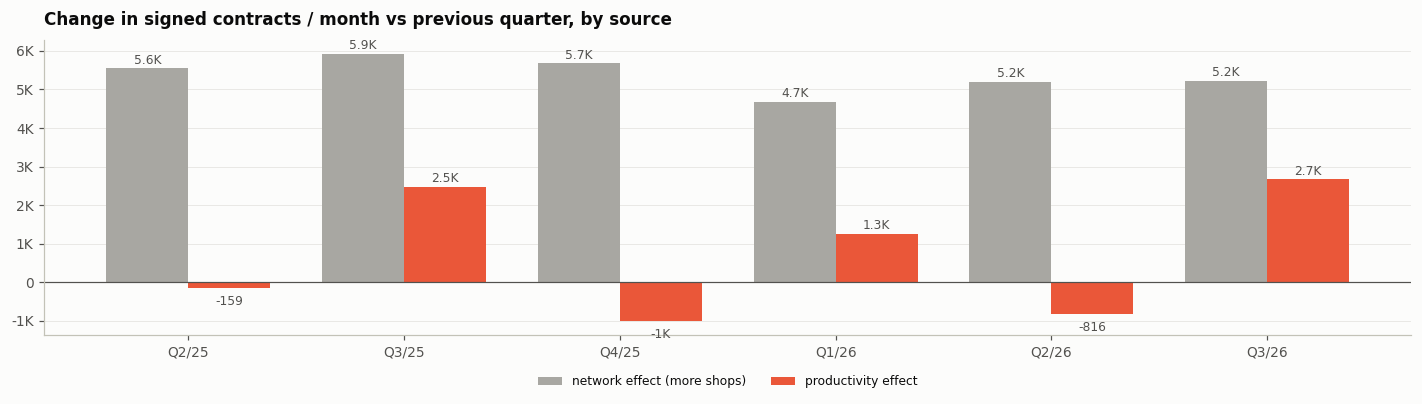

,qlab,n_shop,prod_,delta,net_eff,prod_eff
0,Q2/25,"2,822.33",2.70,"5,393.67","5,553.16",-159.49
1,Q3/25,"5,017.00",3.19,"8,402.00","5,930.29","2,471.71"
2,Q4/25,"6,793.00",3.05,"4,662.33","5,673.97","-1,011.64"
3,Q1/26,"8,331.67",3.20,"5,941.00","4,686.59","1,254.41"
4,Q2/26,"9,957.33",3.11,"4,380.67","5,196.34",-815.68
5,Q3/26,"11,633.67",3.34,"7,890.33","5,220.98","2,669.36"


Tổng tăng từ Q2/25 đến Q3/26: mạng lưới 32,261 · năng suất 4,409 HĐ/tháng → 88% đến từ mở thêm shop


In [16]:
qs = q('''SELECT date_trunc('quarter', m)::DATE qtr, count(*) / 3.0 n_shop, sum(n_sign) / 3.0 sign
          FROM sm_perf GROUP BY 1 ORDER BY 1''')
qs['prod_'] = qs.sign / qs.n_shop
qs['net_eff'] = qs.n_shop.diff() * qs.prod_.shift()
qs['prod_eff'] = qs.n_shop * qs.prod_.diff()
qs['delta'] = qs.sign.diff()
qs['qlab'] = [f'Q{(pd.Timestamp(i).month - 1) // 3 + 1}/{pd.Timestamp(i).year % 100}' for i in qs.qtr]
d = qs.dropna().reset_index(drop=True)
fig, ax = plt.subplots(figsize=(13, 3.8))
x = np.arange(len(d)); h = .38
ax.bar(x - h / 2, d.net_eff, h, color=GREY, label='hiệu ứng mạng lưới (thêm shop)')
ax.bar(x + h / 2, d.prod_eff, h, color=ORANGE, label='hiệu ứng năng suất')
for xi, a, b in zip(x, d.net_eff, d.prod_eff):
    ax.annotate(human(a), (xi - h / 2, a), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8, color=INK2)
    ax.annotate(human(b), (xi + h / 2, b), xytext=(0, 3 if b >= 0 else -11), textcoords='offset points', ha='center', fontsize=8, color=INK2)
ax.axhline(0, color=INK2, lw=.8); ax.set_xticks(x, d.qlab); ax.grid(axis='x', visible=False)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(human)); ax.legend(loc='upper center', bbox_to_anchor=(.5, -.1), ncol=2)
ax.set_title('Thay đổi HĐ ký / tháng so với quý trước, tách theo nguồn')
plt.tight_layout(); plt.show()
display(d[['qlab', 'n_shop', 'prod_', 'delta', 'net_eff', 'prod_eff']].round(2))
print(f"Tổng tăng từ {d.qlab.iloc[0]} đến {d.qlab.iloc[-1]}: mạng lưới {d.net_eff.sum():,.0f} · năng suất {d.prod_eff.sum():,.0f} HĐ/tháng "
      f"→ {100 * d.net_eff.sum() / (d.net_eff.sum() + d.prod_eff.sum()):.0f}% đến từ mở thêm shop")

### 3.4 Theo phân khúc lớn: phân khúc nào đang kéo tăng trưởng?
Mỗi cột là một phân khúc lớn (dòng hàng × mô hình). Số liệu: HĐ đã ký theo tháng ký và số shop đang hoạt động (bảng `sm_perf`, cùng cách tính với mục 3.3).

> **Mùa vụ:** tháng trước Tết cao, tuần Tết giảm khoảng 70% (Tết 29/01/2025 và 17/02/2026, nên đỉnh rơi vào T1/2025 nhưng T2/2026). Q1 nên so **YoY**, không so QoQ.

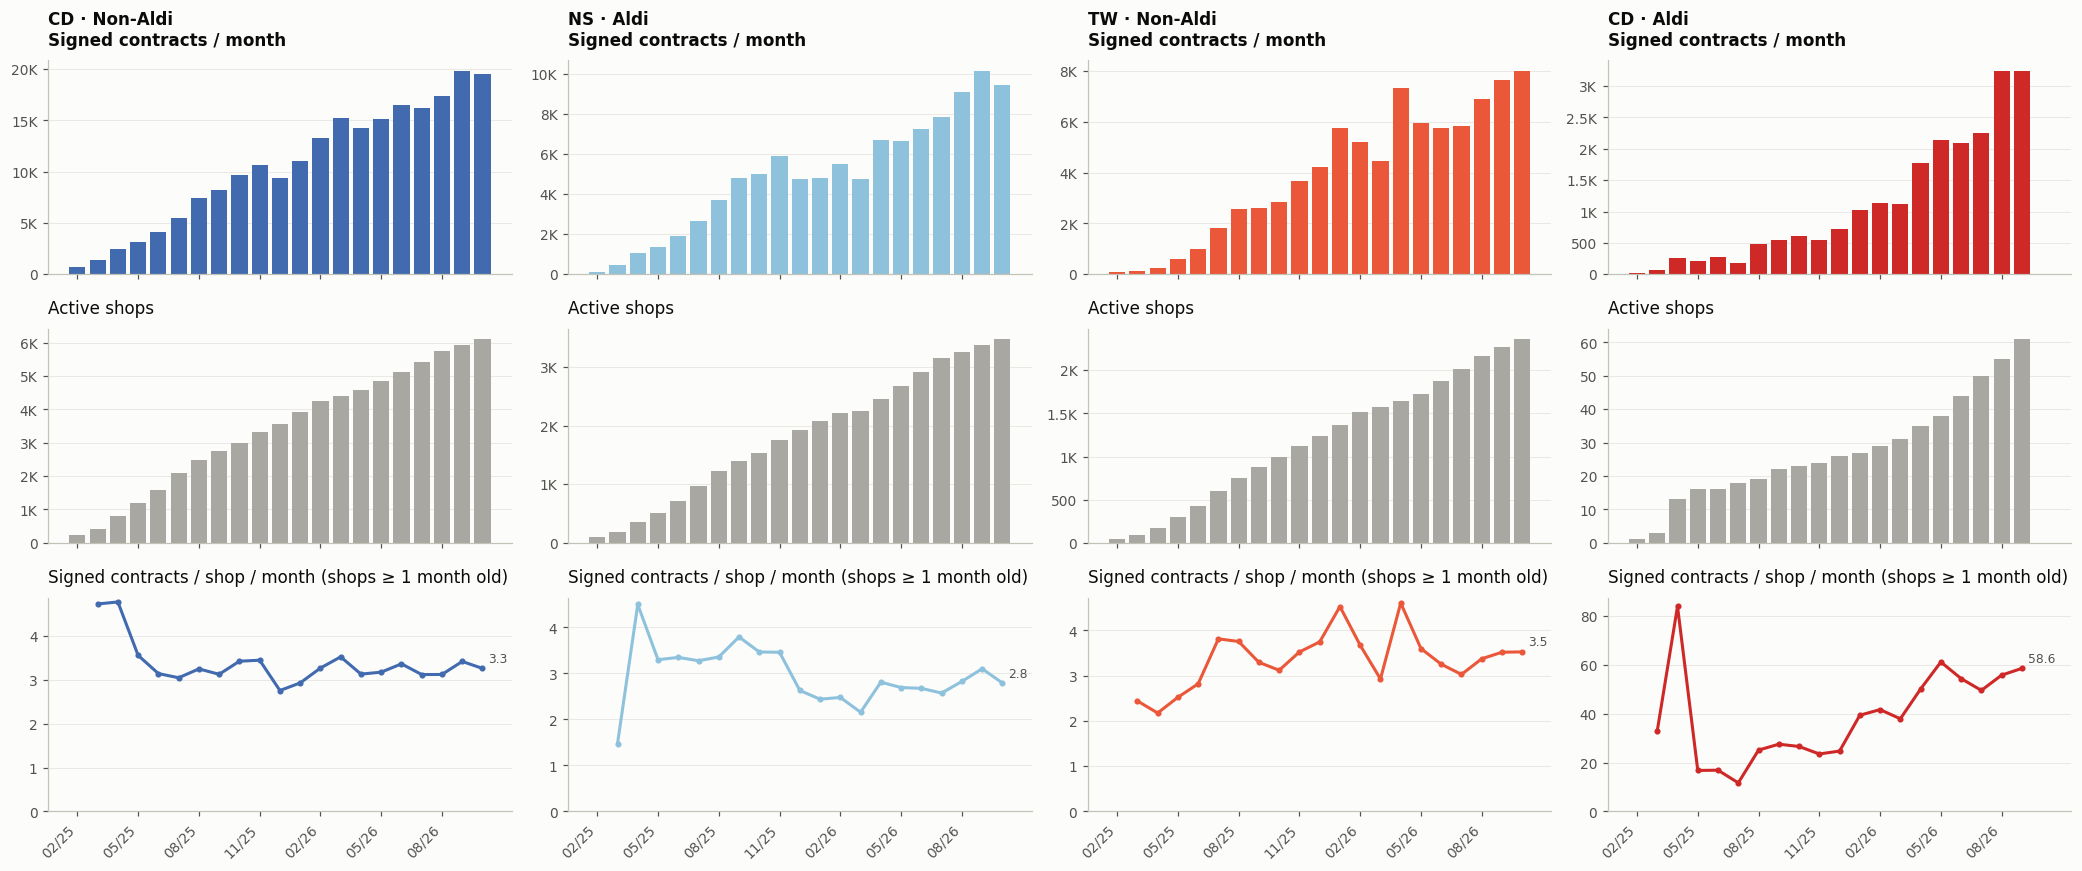

,HĐ/tháng Q3/26,% HĐ,HĐ QoQ,HĐ YoY,Shop TB Q3/26,Shop QoQ,Shop YoY,HĐ/shop/tháng Q3/26,HĐ/shop QoQ,HĐ/shop YoY,Giá trị/shop/tháng Q3/26 (tr),Giá trị/shop YoY,Khoản vay BQ Q3/26 (tr),Khoản vay BQ YoY,Δ HĐ/tháng vs Q2
CD · Non-Aldi,"18,921",49%,+18.8%,+124.0%,"5,935",+15.8%,+116.4%,3.19,+2.5%,+3.5%,37.0,+47.8%,11.6,+42.9%,"+2,990"
NS · Aldi,"9,548",25%,+32.0%,+111.8%,"3,375",+15.4%,+143.8%,2.83,+14.4%,-13.1%,39.7,-17.0%,14.0,-4.5%,"+2,317"
TW · Non-Aldi,"7,520",19%,+28.7%,+182.1%,"2,268",+21.3%,+160.5%,3.32,+6.1%,+8.3%,71.2,+35.1%,21.5,+24.8%,"+1,676"
CD · Aldi,"2,914",7%,+45.2%,+617.1%,55,+41.9%,+181.4%,52.66,+2.3%,+154.9%,509.5,+177.0%,9.7,+8.7%,+907
Toàn mạng lưới,"38,903",100%,+25.4%,+142.7%,"11,634",+16.8%,+131.9%,3.34,+7.4%,+4.7%,46.7,+27.1%,14.0,+21.4%,"+7,890"


Q3 so với Q2/2026: toàn mạng lưới +7,890 HĐ/tháng; CD · Aldi +907 · TW · Non-Aldi +1,676 · NS · Aldi +2,317 · CD · Non-Aldi +2,990


In [17]:
ps = q(f'''SELECT m, seg, count(*) n_shop, sum(n_sign) n_sign, sum(amt) amt,
                 sum(n_sign) FILTER (WHERE age >= 1) / nullif(count(*) FILTER (WHERE age >= 1), 0) per_shop
          FROM sm_perf WHERE seg IN {tuple(SEG)} GROUP BY ALL ORDER BY 1''')
fig, ax = plt.subplots(3, len(SEG), figsize=(19, 8), sharex=True)
for j, sg in enumerate(SEG):
    d = ps[ps.seg == sg].sort_values('m'); x = np.arange(len(d))
    ax[0, j].bar(x, d.n_sign, color=SEGCOL[sg], width=.8)
    ax[0, j].set_title(f'{sg}\nHĐ ký / tháng', loc='left')
    ax[1, j].bar(x, d.n_shop, color=GREY, width=.8); ax[1, j].set_title('Shop đang hoạt động', loc='left', fontweight='normal')
    ax[2, j].plot(x, d.per_shop, color=SEGCOL[sg], marker='o', ms=3); ax[2, j].set_ylim(0, None)
    ax[2, j].set_title('HĐ ký / shop / tháng (shop ≥ 1 tháng tuổi)', loc='left', fontweight='normal')
    ax[2, j].annotate(f'{d.per_shop.iloc[-1]:.1f}', (x[-1], d.per_shop.iloc[-1]), xytext=(4, 4), textcoords='offset points', fontsize=8, color=INK2)
    for a in ax[:2, j]: a.yaxis.set_major_formatter(mtick.FuncFormatter(human))
    for a in ax[:, j]: a.grid(axis='x', visible=False)
    ax[2, j].set_xticks(x[::3], [pd.Timestamp(m_).strftime('%m/%y') for m_ in d.m][::3], rotation=45, ha='right')
plt.tight_layout(); plt.show()

P3, P2, P3p = pd.Period('2026Q3'), pd.Period('2026Q2'), pd.Period('2025Q3')
def qsum(d):
    g = d.groupby(pd.PeriodIndex(d.m, freq='Q'))[['n_sign', 'n_shop', 'amt']].sum()
    hd = g.n_sign / 3; sh = g.n_shop / 3; pr = g.n_sign / g.n_shop; vs = g.amt / g.n_shop / 1e6; tk = g.amt / g.n_sign / 1e6
    v = lambda s_, p: s_.get(p, np.nan)
    return pd.Series({'HĐ/tháng Q3/26': v(hd, P3), 'HĐ QoQ': v(hd, P3) / v(hd, P2) - 1, 'HĐ YoY': v(hd, P3) / v(hd, P3p) - 1,
                      'Shop TB Q3/26': v(sh, P3), 'Shop QoQ': v(sh, P3) / v(sh, P2) - 1, 'Shop YoY': v(sh, P3) / v(sh, P3p) - 1,
                      'HĐ/shop/tháng Q3/26': v(pr, P3), 'HĐ/shop QoQ': v(pr, P3) / v(pr, P2) - 1, 'HĐ/shop YoY': v(pr, P3) / v(pr, P3p) - 1,
                      'Giá trị/shop/tháng Q3/26 (tr)': v(vs, P3), 'Giá trị/shop YoY': v(vs, P3) / v(vs, P3p) - 1,
                      'Khoản vay BQ Q3/26 (tr)': v(tk, P3), 'Khoản vay BQ YoY': v(tk, P3) / v(tk, P3p) - 1,
                      'Δ HĐ/tháng vs Q2': v(hd, P3) - v(hd, P2)})
tb_seg = pd.DataFrame({sg: qsum(ps[ps.seg == sg]) for sg in SEG}).T
tb_seg.loc['Toàn mạng lưới'] = qsum(ps)
tb_seg.insert(1, '% HĐ', tb_seg['HĐ/tháng Q3/26'] / tb_seg.loc['Toàn mạng lưới', 'HĐ/tháng Q3/26'])
pct_cols = [c for c in tb_seg.columns if 'QoQ' in c or 'YoY' in c]
display(tb_seg.style.format({**{c: '{:+.1%}' for c in pct_cols}, '% HĐ': '{:.0%}', 'HĐ/tháng Q3/26': '{:,.0f}', 'Shop TB Q3/26': '{:,.0f}',
                             'HĐ/shop/tháng Q3/26': '{:.2f}', 'Giá trị/shop/tháng Q3/26 (tr)': '{:.1f}', 'Khoản vay BQ Q3/26 (tr)': '{:.1f}', 'Δ HĐ/tháng vs Q2': '{:+,.0f}'}, na_rep='–'))
dd = tb_seg.drop('Toàn mạng lưới')['Δ HĐ/tháng vs Q2']
print(f"Q3 so với Q2/2026: toàn mạng lưới {tb_seg.loc['Toàn mạng lưới', 'Δ HĐ/tháng vs Q2']:+,.0f} HĐ/tháng; "
      + ' · '.join(f'{i} {v_:+,.0f}' for i, v_ in dd.sort_values().items()))

### 3.5 Cầu nối tăng trưởng theo phân khúc: thêm shop hay bán tốt hơn?
Trong từng phân khúc, thay đổi HĐ ký / tháng giữa hai quý được tách thành:
- **mạng lưới** = (số shop thay đổi) × năng suất quý trước
- **năng suất** = số shop quý này × (thay đổi HĐ / shop)

Làm cho **cả số HĐ và giá trị khoản vay**: năng suất theo giá trị gồm cả phần do khoản vay bình quân tăng (mục 3.7). Cộng mọi thanh lại sẽ ra đúng chênh lệch của toàn mạng lưới. Biểu đồ trái so **Q3/2026 với Q3/2025** (cùng mùa, loại được mùa vụ); biểu đồ phải so **Q3 với Q2/2026** (diễn biến gần nhất).

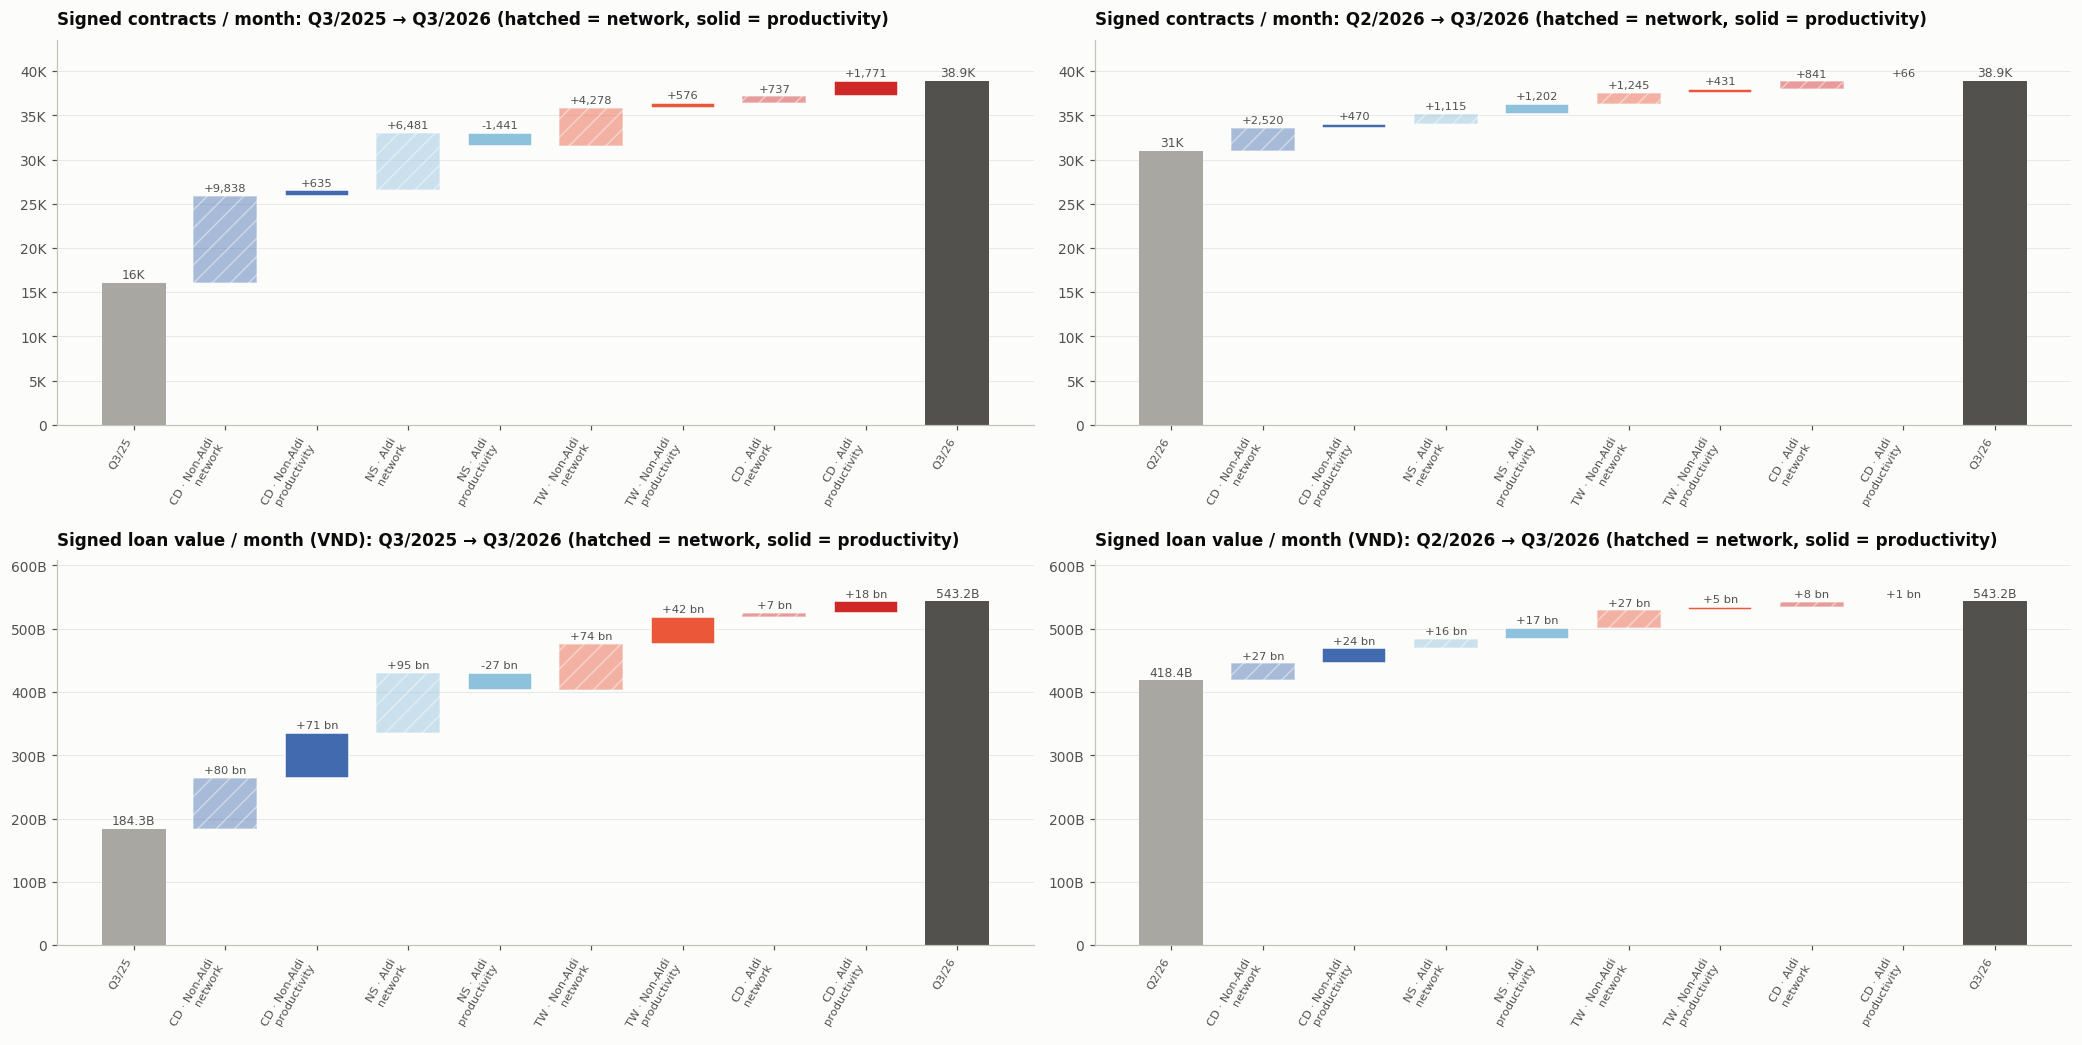

nguon                                                            mạng lưới  năng suất      tổng
chi_so                                ky          seg                                          
Giá trị khoản vay đã ký / tháng (VND) Q2/26→Q3/26 CD · Aldi           8.00       0.90      9.00
                                                  CD · Non-Aldi      26.80      23.70     50.40
                                                  NS · Aldi          15.60      17.10     32.70
                                                  TW · Non-Aldi      27.40       5.30     32.70
                                      Q3/25→Q3/26 CD · Aldi           6.60      18.00     24.60
                                                  CD · Non-Aldi      79.90      71.10    151.00
                                                  NS · Aldi          95.20     -27.50     67.70
                                                  TW · Non-Aldi      73.60      42.00    115.50
HĐ ký / tháng                         Q2/26→Q3/26 CD · Aldi         840.50      66.50    907.00
                                                  CD · Non-Aldi   2,520.20     470.10  2,990.30
                                                  NS · Aldi       1,115.10   1,201.90  2,317.00
                                                  TW · Non-Aldi   1,245.10     430.90  1,676.00
                                      Q3/25→Q3/26 CD · Aldi         736.90   1,770.80  2,507.70
                                                  CD · Non-Aldi   9,837.90     634.80 10,472.70
                                                  NS · Aldi       6,480.90  -1,441.30  5,039.70
                                                  TW · Non-Aldi   4,278.10     576.20  4,854.30

Giá trị khoản vay đã ký  Q2/26→Q3/26: tổng +125 tỷ đ/tháng = mạng lưới +78 (62%) + năng suất +47 (38%)
Giá trị khoản vay đã ký  Q3/25→Q3/26: tổng +359 tỷ đ/tháng = mạng lưới +255 (71%) + năng suất +104 (29%)
HĐ ký / tháng            Q2/26→Q3/26: tổng +7,890 HĐ/tháng = mạng lưới +5,721 (73%) + năng suất +2,169 (27%)
HĐ ký / tháng            Q3/25→Q3/26: tổng +22,874 HĐ/tháng = mạng lưới +21,334 (93%) + năng suất +1,540 (7%)


In [18]:
def bridge(p0, p1, col):
    rows = []
    for sg in SEG:
        d = ps[ps.seg == sg]
        g = d.groupby(pd.PeriodIndex(d.m, freq='Q'))[[col, 'n_shop']].sum() / 3
        s0, s1, h0, h1 = g.n_shop.get(p0, 0), g.n_shop.get(p1, 0), g[col].get(p0, 0), g[col].get(p1, 0)
        if s0 == 0:                                        # phân khúc chưa có shop ở quý gốc: toàn bộ là mạng lưới
            net, prod = h1, 0.0
        else:
            net, prod = (s1 - s0) * h0 / s0, s1 * (h1 / s1 - h0 / s0) if s1 else 0.0
        rows += [dict(seg=sg, nguon='mạng lưới', v=net), dict(seg=sg, nguon='năng suất', v=prod)]
    tot = ps.groupby(pd.PeriodIndex(ps.m, freq='Q'))[col].sum() / 3
    return tot.get(p0, 0), pd.DataFrame(rows), tot.get(p1, 0)

def waterfall(ax, p0, p1, col='n_sign', unit='HĐ ký / tháng', fmt=lambda v: f'{v:+,.0f}'):
    start, br, end = bridge(p0, p1, col)
    lab = [f'{p0.strftime("Q%q/%y")}'] + [f"{r.seg}\n{r.nguon}" for r in br.itertuples()] + [f'{p1.strftime("Q%q/%y")}']
    x = np.arange(len(lab)); run = start
    ax.bar(0, start, color=GREY, width=.7); ax.annotate(human(start), (0, start), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8, color=INK2)
    for i, r in enumerate(br.itertuples(), 1):
        ax.bar(i, r.v, bottom=run, color=SEGCOL[r.seg], width=.7, alpha=.45 if r.nguon == 'mạng lưới' else 1,
               hatch='//' if r.nguon == 'mạng lưới' else None, edgecolor=SURF)
        ax.annotate(fmt(r.v), (i, run + max(r.v, 0)), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=7.5, color=INK2)
        run += r.v
    ax.bar(len(lab) - 1, end, color=INK2, width=.7); ax.annotate(human(end), (len(lab) - 1, end), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8, color=INK2)
    ax.set_xticks(x, lab, rotation=60, ha='right', fontsize=7.5); ax.grid(axis='x', visible=False)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(human)); ax.set_ylim(0, max(start, end, run) * 1.12)
    ax.set_title(f'{unit}: {p0.strftime("Q%q/%Y")} → {p1.strftime("Q%q/%Y")} (sọc = mạng lưới, đặc = năng suất)')
    return br.assign(ky=f'{p0.strftime("Q%q/%y")}→{p1.strftime("Q%q/%y")}', chi_so=unit)

ty = lambda v: f'{v / 1e9:+,.0f} tỷ'
fig, ax = plt.subplots(2, 2, figsize=(19, 9.6))
brs = pd.concat([waterfall(ax[0, 0], P3p, P3), waterfall(ax[0, 1], P2, P3),
                 waterfall(ax[1, 0], P3p, P3, 'amt', 'Giá trị khoản vay đã ký / tháng (VND)', ty),
                 waterfall(ax[1, 1], P2, P3, 'amt', 'Giá trị khoản vay đã ký / tháng (VND)', ty)])
plt.tight_layout(); plt.show()
bt = brs.pivot_table(index=['chi_so', 'ky', 'seg'], columns='nguon', values='v', aggfunc='sum')
bt['tổng'] = bt.sum(axis=1)
bt.loc[bt.index.get_level_values('chi_so') != 'HĐ ký / tháng'] /= 1e9          # giá trị: tỷ đ / tháng
display(bt.round(1))
for (cs, k_), g_ in bt.groupby(level=['chi_so', 'ky']):
    t_ = g_.sum(); u_ = 'HĐ/tháng' if cs == 'HĐ ký / tháng' else 'tỷ đ/tháng'
    print(f"{cs[:24]:<24} {k_}: tổng {t_['tổng']:+,.0f} {u_} = mạng lưới {t_['mạng lưới']:+,.0f} ({t_['mạng lưới'] / t_['tổng']:.0%}) "
          f"+ năng suất {t_['năng suất']:+,.0f} ({t_['năng suất'] / t_['tổng']:.0%})")

### 3.6 Vòng đời shop: HĐ đến từ shop mới hay shop đã ổn định?
Giai đoạn tính theo **tuổi của shop tại tháng đó** (tháng mở = tháng 0): Mới mở 0–2 tháng · Tăng tốc 3–5 tháng · Ổn định ≥ 6 tháng.
Đường cong theo tuổi dùng tháng thứ k sau khi mở thay cho tháng lịch, để so được các shop mở ở thời điểm khác nhau. Chỉ tính shop còn mở ở tháng đó; shop đóng sớm bị loại nên đường cong hơi lạc quan. Tháng 0 là tháng chưa đủ (mở giữa tháng). Hàng dưới cùng: **giá trị / shop** và **khoản vay bình quân** theo tuổi.

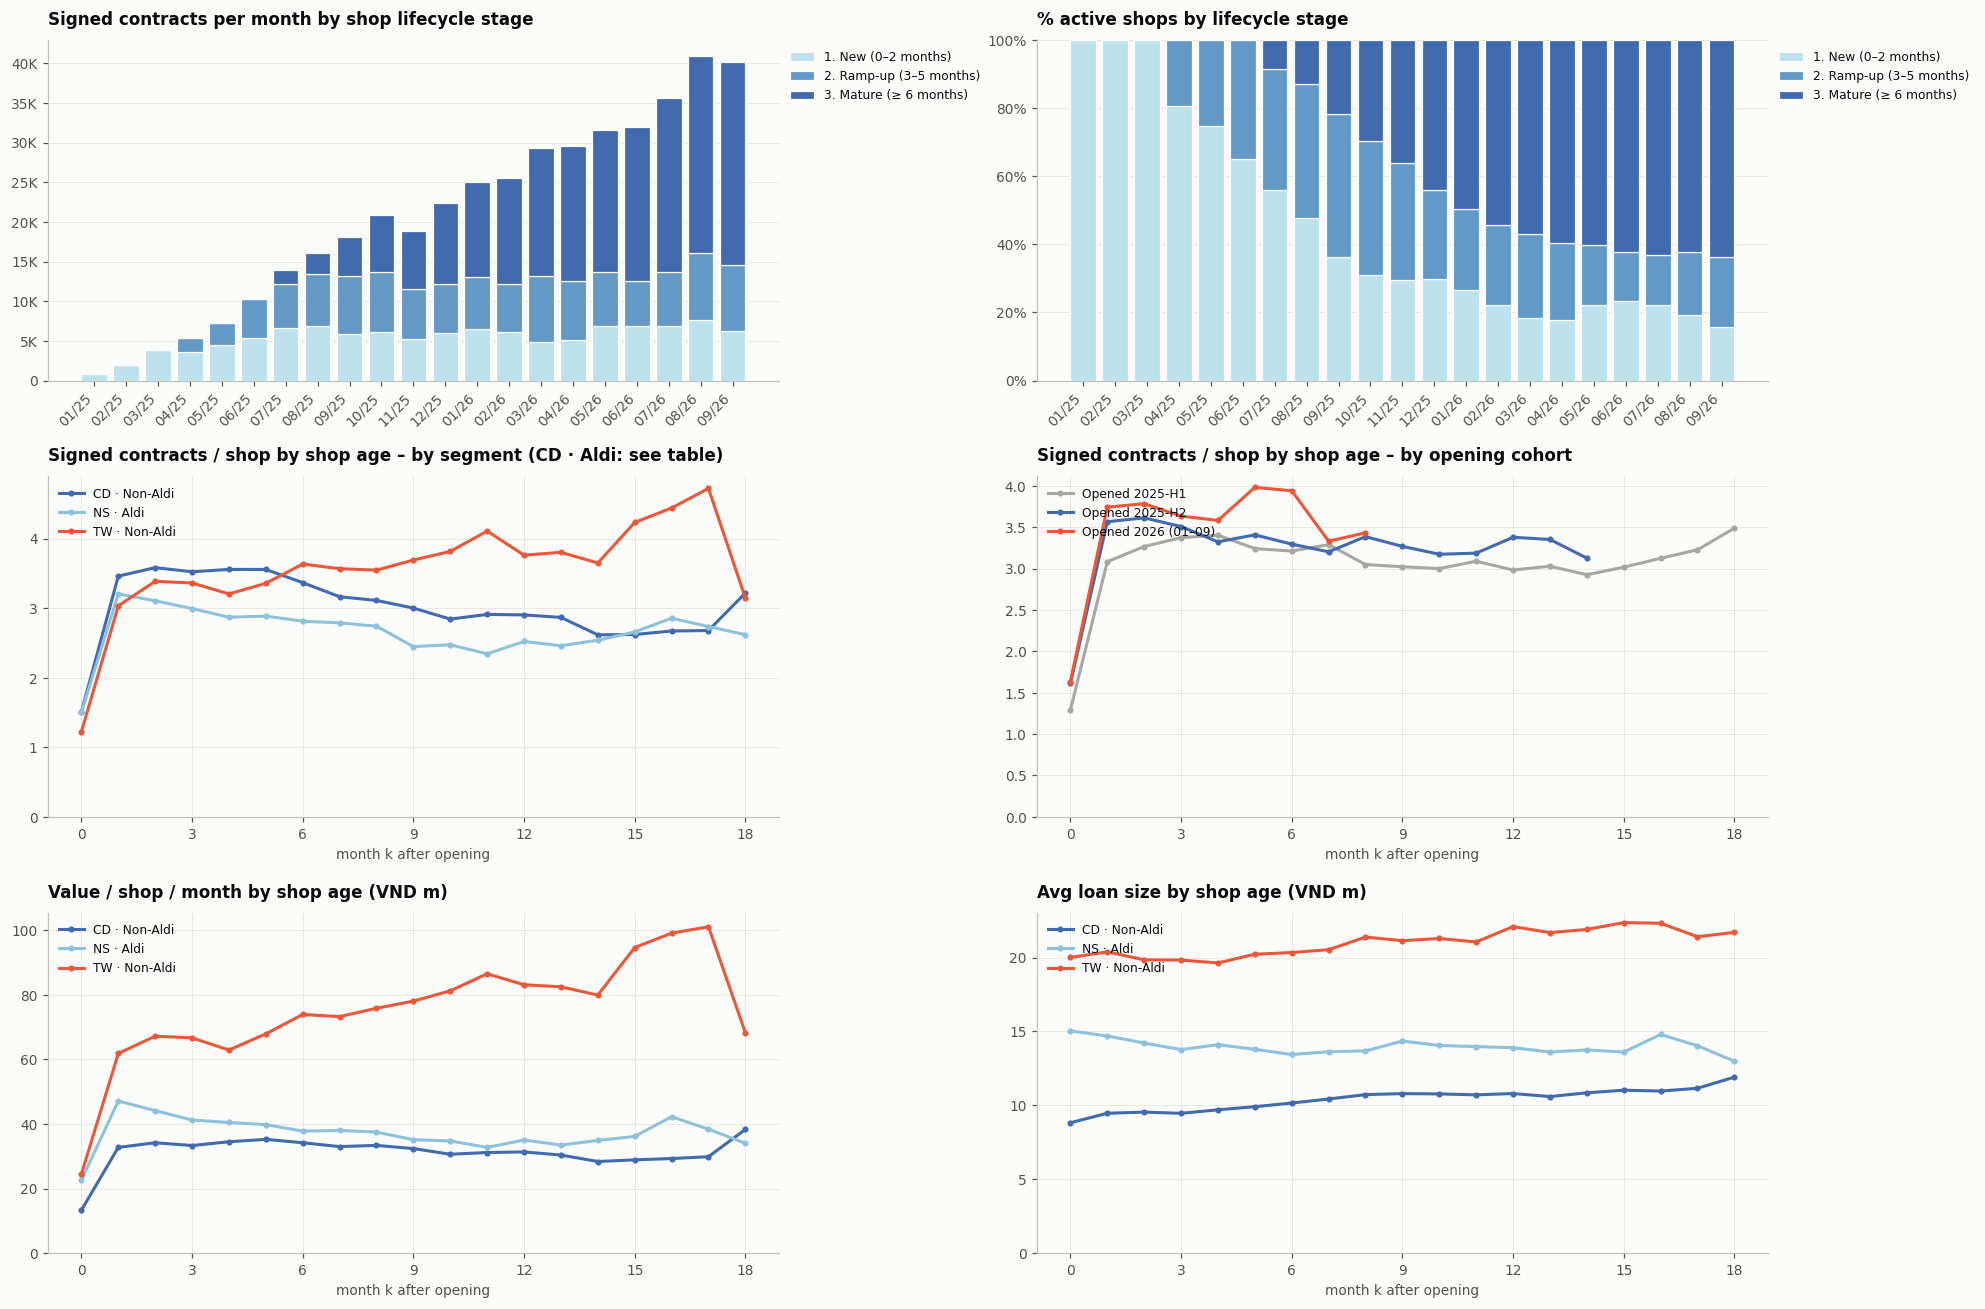

,% shop Q3/26,% HĐ ký Q3/26,HĐ / shop / tháng
stage,,,
1. Mới mở (0–2 tháng),19%,18%,3.12
2. Tăng tốc (3–5 tháng),18%,20%,3.78
3. Ổn định (≥ 6 tháng),63%,62%,3.29


HĐ / shop / tháng                                   Giá trị / shop / tháng (tr)                                  
seg              CD · Non-Aldi NS · Aldi TW · Non-Aldi CD · Aldi               CD · Non-Aldi NS · Aldi TW · Non-Aldi CD · Aldi
tuổi (tháng)                                                                                                                  
1                         3.50      3.20          3.00     50.80                       32.80     47.10         61.80    474.20
2                         3.60      3.10          3.40     47.50                       34.20     44.20         67.20    441.70
3                         3.50      3.00          3.40     50.30                       33.30     41.20         66.70    483.10
6                         3.40      2.80          3.60     36.20                       34.20     37.80         73.90    366.90
9                         3.00      2.40          3.70       NaN                       32.40     35.10         78.00       NaN
12                        2.90      2.50          3.80       NaN                       31.40     35.00         83.10       NaN
15                        2.60      2.70          4.20       NaN                       28.90     36.20         94.60       NaN
18                        3.20      2.60          3.10       NaN                       38.30     34.00         68.30       NaN

In [19]:
lc = q('SELECT m, stage, count(*) n_shop, sum(n_sign) n_sign FROM sm_perf GROUP BY ALL')
p_hd = lc.pivot(index='m', columns='stage', values='n_sign').sort_index().reindex(columns=STAGES)
p_sh = lc.pivot(index='m', columns='stage', values='n_shop').sort_index().reindex(columns=STAGES)
ac = q(f'''SELECT seg, age, count(*) n, avg(n_sign) mean_, avg(amt) / 1e6 mean_v, sum(amt) / nullif(sum(n_sign), 0) / 1e6 ticket FROM sm_perf
           WHERE seg IN {tuple(SEG)} AND age <= 18 GROUP BY ALL HAVING count(*) >= 30 ORDER BY age''')
co = q('''SELECT CASE WHEN m_open < DATE '2025-07-01' THEN 'Mở 2025-H1' WHEN m_open < DATE '2026-01-01' THEN 'Mở 2025-H2'
                      ELSE 'Mở 2026 (01–09)' END cohort, age, count(*) n, avg(n_sign) mean_
          FROM sm_perf WHERE age <= 18 GROUP BY ALL HAVING count(*) >= 30 ORDER BY age''')
fig, ax = plt.subplots(3, 2, figsize=(18, 12))
stack_bar(ax[0, 0], p_hd, STCOL, 'HĐ ký mỗi tháng theo giai đoạn vòng đời của shop')
stack_bar(ax[0, 1], p_sh.div(p_sh.sum(axis=1), axis=0) * 100, STCOL, '% shop đang hoạt động theo giai đoạn', pct=True)
for sg in [x for x in SEG if x != 'CD · Aldi']:                 # CD · Aldi ~50 HĐ/shop, xem bảng dưới
    d = ac[ac.seg == sg]; ax[1, 0].plot(d.age, d.mean_, color=SEGCOL[sg], marker='o', ms=3, label=sg)
for sg in [x for x in SEG if x != 'CD · Aldi']:
    d = ac[ac.seg == sg]
    ax[2, 0].plot(d.age, d.mean_v, color=SEGCOL[sg], marker='o', ms=3, label=sg)
    ax[2, 1].plot(d.age, d.ticket, color=SEGCOL[sg], marker='o', ms=3, label=sg)
for c_, (k_, d) in zip([GREY, BLUE, ORANGE], co.groupby('cohort')):
    ax[1, 1].plot(d.age, d.mean_, color=c_, marker='o', ms=3, label=k_)
for a, t in [(ax[1, 0], 'HĐ ký / shop theo tuổi shop – theo phân khúc (CD · Aldi xem bảng)'), (ax[1, 1], 'HĐ ký / shop theo tuổi shop – theo lứa mở'),
             (ax[2, 0], 'Giá trị / shop / tháng theo tuổi shop (triệu đ)'), (ax[2, 1], 'Khoản vay bình quân theo tuổi shop (triệu đ)')]:
    a.set_xlabel('tháng thứ k sau khi mở'); a.set_ylim(0, None); a.legend(loc='upper left'); a.set_title(t); a.set_xticks(range(0, 19, 3))
plt.tight_layout(); plt.show()
cur_st = p_hd.loc[pd.Timestamp('2026-07-01'):].sum(); cur_sh = p_sh.loc[pd.Timestamp('2026-07-01'):].sum()
display(pd.DataFrame({'% shop Q3/26': cur_sh / cur_sh.sum(), '% HĐ ký Q3/26': cur_st / cur_st.sum(),
                      'HĐ / shop / tháng': cur_st / cur_sh}).style.format({'% shop Q3/26': '{:.0%}', '% HĐ ký Q3/26': '{:.0%}', 'HĐ / shop / tháng': '{:.2f}'}))
curve = ac.pivot(index='age', columns='seg', values='mean_').reindex(columns=SEG)
curve_v = ac.pivot(index='age', columns='seg', values='mean_v').reindex(columns=SEG)
display(pd.concat({'HĐ / shop / tháng': curve, 'Giá trị / shop / tháng (tr)': curve_v}, axis=1).reindex([1, 2, 3, 6, 9, 12, 15, 18]).round(1).rename_axis('tuổi (tháng)'))

### 3.7 Năng suất theo giá trị: shop không bán nhiều HĐ hơn, nhưng mỗi HĐ lớn hơn
Xét shop vật lý **từ 3 tháng tuổi trở lên** tại từng tháng (bỏ giai đoạn mới mở), HĐ thành công theo tháng ký.

**Giá trị / shop = HĐ / shop × khoản vay bình quân**, nên thay đổi giá trị / shop tách được thành phần do **số HĐ** và phần do **khoản vay bình quân**. Khoản vay bình quân lại tách tiếp:
- **cơ cấu sản phẩm** = (tỷ trọng sản phẩm mới − cũ) × khoản vay BQ cũ của sản phẩm đó: bán nhiều TW / CL hơn thì khoản vay BQ tăng
- **trong từng sản phẩm** = tỷ trọng mới × (khoản vay BQ mới − cũ): cùng sản phẩm nhưng khoản vay lớn hơn

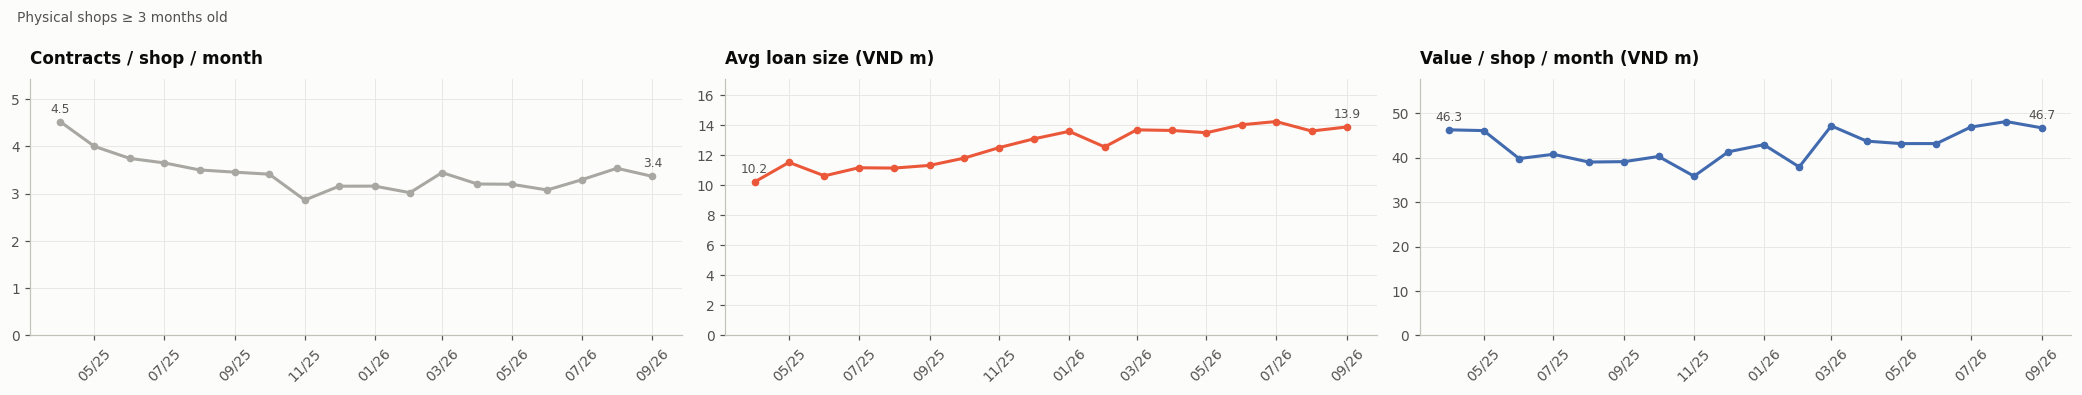

,Tỷ trọng Q3/25,Tỷ trọng Q3/26,Khoản vay BQ Q3/25 (tr),Khoản vay BQ Q3/26 (tr)
prod,,,,
CD,65.1%,70.9%,10.6,11.2
TW,11.4%,15.8%,20.5,21.4
BNPL,14.7%,6.9%,1.0,6.9
CL,4.4%,4.5%,41.9,42.8
CC,4.4%,1.3%,0.0,0.0
Khác,0.1%,0.5%,23.7,21.7


Q3/2025 → Q3/2026 (shop ≥ 3 tháng tuổi): HĐ/shop -3%, khoản vay BQ +24%, giá trị/shop +20% → giá trị/shop tăng hoàn toàn nhờ khoản vay BQ (log: +0.21), số HĐ/shop không đóng góp (log: -0.03).
Khoản vay BQ tăng +2.7 tr: cơ cấu sản phẩm +1.6 tr · trong từng sản phẩm +1.0 tr.


In [20]:
lf_s = q('''SELECT m, seg, count(*) n_shop FROM sm WHERE age >= 3 AND category IN ('Big','Medium','Small') GROUP BY ALL''')
lf_k = q('''SELECT k.m_sign m, s.seg, k.prod, count(*) n, sum(k.loan_amount_eff) v
            FROM ctr k JOIN sm s ON s.skp_salesroom = k.skp_salesroom AND s.m = k.m_sign
            WHERE k.is_signed AND k.name_status <> 'Cancelled' AND s.age >= 3 AND s.category IN ('Big','Medium','Small') GROUP BY ALL''')
mt = lf_k.groupby('m')[['n', 'v']].sum().join(lf_s.groupby('m').n_shop.sum()).sort_index().loc[pd.Timestamp('2025-04-01'):]
mt['hd_shop'], mt['ticket'], mt['v_shop'] = mt.n / mt.n_shop, mt.v / mt.n / 1e6, mt.v / mt.n_shop / 1e6
fig, ax = plt.subplots(1, 3, figsize=(19, 3.6))
for a, col, t, c_ in [(ax[0], 'hd_shop', 'HĐ / shop / tháng', GREY), (ax[1], 'ticket', 'Khoản vay bình quân (triệu đ)', ORANGE),
                      (ax[2], 'v_shop', 'Giá trị / shop / tháng (triệu đ)', BLUE)]:
    a.plot(mt.index, mt[col], color=c_, marker='o', ms=4); a.set_ylim(0, mt[col].max() * 1.2); a.set_title(t)
    a.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%m/%y')); a.tick_params(axis='x', rotation=45)
    for i_ in [0, len(mt) - 1]:
        a.annotate(f'{mt[col].iloc[i_]:.1f}', (mt.index[i_], mt[col].iloc[i_]), xytext=(0, 6), textcoords='offset points', ha='center', fontsize=8, color=INK2)
fig.suptitle('Shop vật lý ≥ 3 tháng tuổi', x=.01, ha='left', fontsize=9, color=INK2)
plt.tight_layout(); plt.show()

def lfq(kk, ss, p):
    kq, sq = kk[pd.PeriodIndex(kk.m, freq='Q') == p], ss[pd.PeriodIndex(ss.m, freq='Q') == p]
    n, v, s_ = kq.n.sum(), kq.v.sum(), sq.n_shop.sum()
    return pd.Series({'Shop TB': s_ / 3, 'HĐ / shop / tháng': n / s_, 'Khoản vay BQ (tr)': v / n / 1e6, 'Giá trị / shop / tháng (tr)': v / s_ / 1e6})
rows_ = {}
for g_ in ['Toàn bộ'] + SEG:
    kk, ss = (lf_k, lf_s) if g_ == 'Toàn bộ' else (lf_k[lf_k.seg == g_], lf_s[lf_s.seg == g_])
    a0, a1 = lfq(kk, ss, P3p), lfq(kk, ss, P3)
    rows_[g_] = pd.concat({'Q3/2025': a0, 'Q3/2026': a1, 'Thay đổi': a1 / a0 - 1})
lf_tab = pd.DataFrame(rows_).T
display(lf_tab.style.format('{:.2f}').format('{:+.0%}', subset=[c for c in lf_tab.columns if c[0] == 'Thay đổi'])
              .format('{:,.0f}', subset=[c for c in lf_tab.columns if c[1] == 'Shop TB' and c[0] != 'Thay đổi']))

# khoản vay BQ tăng do cơ cấu sản phẩm hay do từng sản phẩm?
kq_ = lf_k.assign(q=pd.PeriodIndex(lf_k.m, freq='Q'))
kq_ = kq_[kq_.q.isin([P3p, P3])].groupby(['q', 'prod'])[['n', 'v']].sum().unstack('q').fillna(0)
s0, s1 = kq_['n'][P3p] / kq_['n'][P3p].sum(), kq_['n'][P3] / kq_['n'][P3].sum()
t1 = kq_['v'][P3] / kq_['n'][P3].replace(0, np.nan); t0 = (kq_['v'][P3p] / kq_['n'][P3p].replace(0, np.nan)).fillna(t1)
mix_eff, rate_eff = ((s1 - s0) * t0).sum() / 1e6, (s1 * (t1 - t0)).fillna(0).sum() / 1e6
display(pd.DataFrame({'Tỷ trọng Q3/25': s0, 'Tỷ trọng Q3/26': s1, 'Khoản vay BQ Q3/25 (tr)': t0 / 1e6, 'Khoản vay BQ Q3/26 (tr)': t1 / 1e6})
        .sort_values('Tỷ trọng Q3/26', ascending=False).style.format({'Tỷ trọng Q3/25': '{:.1%}', 'Tỷ trọng Q3/26': '{:.1%}',
                                                                      'Khoản vay BQ Q3/25 (tr)': '{:.1f}', 'Khoản vay BQ Q3/26 (tr)': '{:.1f}'}))
tt = lf_tab.loc['Toàn bộ']
d_hd, d_tk = np.log(1 + tt[('Thay đổi', 'HĐ / shop / tháng')]), np.log(1 + tt[('Thay đổi', 'Khoản vay BQ (tr)')])
print(f"Q3/2025 → Q3/2026 (shop ≥ 3 tháng tuổi): HĐ/shop {tt[('Thay đổi', 'HĐ / shop / tháng')]:+.0%}, khoản vay BQ {tt[('Thay đổi', 'Khoản vay BQ (tr)')]:+.0%}, "
      f"giá trị/shop {tt[('Thay đổi', 'Giá trị / shop / tháng (tr)')]:+.0%} → giá trị/shop tăng hoàn toàn nhờ khoản vay BQ (log: {d_tk:+.2f}), số HĐ/shop không đóng góp (log: {d_hd:+.2f}).")
print(f"Khoản vay BQ tăng {mix_eff + rate_eff:+.1f} tr: cơ cấu sản phẩm {mix_eff:+.1f} tr · trong từng sản phẩm {rate_eff:+.1f} tr.")

## 4. Tỷ lệ vay & khoản vay

### Cách đọc các tỷ lệ của phễu (đọc trước khi xem mục 4)

Một hồ sơ đi qua **hai quyết định của hai bên khác nhau**:

```
Nộp hồ sơ ──► Công ty DUYỆT hay TỪ CHỐI (chính sách tín dụng) ──► nếu được duyệt: khách KÝ hay HUỶ
```

Khách cũng có thể **huỷ trước khi công ty kịp duyệt**. Dữ liệu Round 3 chỉ có trạng thái cuối (**ký / từ chối / huỷ**) và **không có thời điểm duyệt**.
Vì vậy với hồ sơ "huỷ", ta không biết nó đã được duyệt hay chưa.

**Ví dụ với 100 hồ sơ:** 74 ký · 18 bị từ chối · 8 huỷ.

| Chỉ số | Cách tính | Kết quả | Có chắc chắn? |
|---|---|---|---|
| **Tỷ lệ ký** (chuyển đổi tổng thể) | ký ÷ hồ sơ | 74 / 100 = **74%** | Có |
| **Tỷ lệ bị từ chối** | từ chối ÷ hồ sơ | 18 / 100 = **18%** | Có |
| **Tỷ lệ huỷ** | huỷ ÷ hồ sơ | 8 / 100 = **8%** | Có |
| **Tỷ lệ duyệt – cận trên** | ký ÷ (ký + từ chối): coi mọi hồ sơ huỷ là chưa được xét duyệt | 74 / 92 = **80%** | Không: là giới hạn |
| **Tỷ lệ duyệt – cận dưới** | ký ÷ (ký + từ chối + huỷ): coi mọi hồ sơ huỷ là không được duyệt | 74 / 100 = **74%** | Không: là giới hạn |

→ Tỷ lệ duyệt thật nằm trong khoảng **74%–80%**. Khoảng này hẹp vì tỷ lệ huỷ chỉ khoảng 5–8%.

**Quy ước trong notebook:**
- "Tỷ lệ ký" **không** được gọi là "tỷ lệ duyệt".
- Khi cần tỷ lệ duyệt, báo cáo **khoảng cận dưới – cận trên**.
- "HĐ ký" ở đây là HĐ đã ký **và không bị huỷ sau ký**.

### 4.0 Phễu theo cùng nhóm hồ sơ
Mỗi tháng là một **nhóm hồ sơ nộp trong tháng đó**, theo dõi tới kết cục cuối cùng: ký, bị từ chối, huỷ, hoặc chưa hoàn tất.
Phần dưới kiểm tra thêm hồ sơ nộp cuối kỳ (tuần cuối 09/2026) đã kịp có kết cục chưa, để tỷ lệ Q3 không bị thấp giả.

,thang,ho_so,ky,tu_choi,huy,chua_hoan_tat,phut_TV,phut_P90,ty_le_ky,tu_choi_%,huy_%,duyet_can_duoi,duyet_can_tren
0,2026-01-01,36843,24824,9064,2955,0,12.00,33.00,0.67,0.25,0.08,0.67,0.73
1,2026-02-01,36545,25406,8424,2715,0,12.00,29.00,0.69,0.23,0.07,0.69,0.75
2,2026-03-01,41567,29171,8926,3470,0,12.00,32.00,0.70,0.21,0.08,0.70,0.77
3,2026-04-01,41958,29256,9616,3086,0,11.00,31.00,0.70,0.23,0.07,0.70,0.75
4,2026-05-01,45032,31356,10364,3312,0,11.00,31.00,0.70,0.23,0.07,0.70,0.75
5,2026-06-01,45427,31668,10397,3362,0,11.00,30.00,0.70,0.23,0.07,0.70,0.75
6,2026-07-01,49577,35282,10477,3818,0,11.00,30.00,0.71,0.21,0.08,0.71,0.77
7,2026-08-01,56118,40574,11189,4355,0,12.00,31.00,0.72,0.20,0.08,0.72,0.78
8,2026-09-01,55743,39882,11454,4407,0,12.00,33.00,0.71,0.20,0.08,0.71,0.78


,tuan,ho_so,ty_le_ky,chua_hoan_tat
0,2026-07-27,4022,0.75,0.00
1,2026-08-03,11470,0.73,0.00
2,2026-08-10,14354,0.72,0.00
3,2026-08-17,12124,0.71,0.00
4,2026-08-24,12064,0.72,0.00
5,2026-08-31,14146,0.72,0.00
6,2026-09-07,13609,0.71,0.00
7,2026-09-14,13183,0.72,0.00
8,2026-09-21,11858,0.72,0.00
9,2026-09-28,5031,0.69,0.00


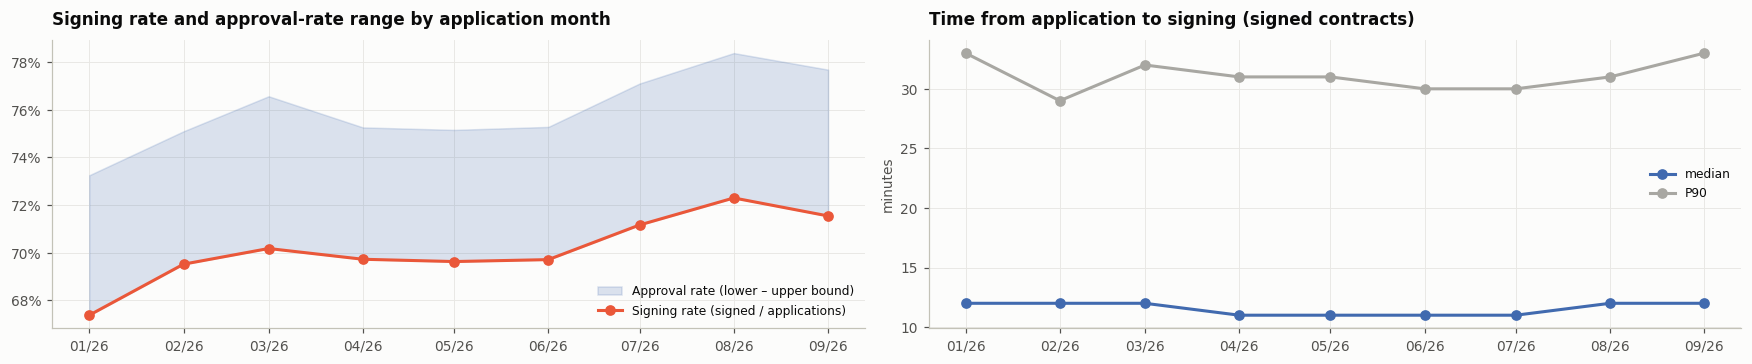

Q3/2026: tỷ lệ ký 71.7% · tỷ lệ duyệt trong khoảng 71.7%–77.8% · hồ sơ chưa hoàn tất 0 (0.00%)


In [21]:
# Phễu theo cùng nhóm hồ sơ (nộp trong tháng): kết cục, hồ sơ chưa hoàn tất, thời gian nộp → ký
fc = q('''SELECT thang,
             count(*) ho_so,
             count(*) FILTER (WHERE is_signed AND name_status <> 'Cancelled') ky,
             count(*) FILTER (WHERE name_status = 'Rejected') tu_choi,
             count(*) FILTER (WHERE name_status = 'Cancelled') huy,
             count(*) FILTER (WHERE name_status IN ('In Process', 'In Preprocess', 'Approved')) chua_hoan_tat,
             quantile_cont(date_diff('minute', date_apply, date_sign), .5) FILTER (WHERE is_signed AND name_status <> 'Cancelled') phut_TV,
             quantile_cont(date_diff('minute', date_apply, date_sign), .9) FILTER (WHERE is_signed AND name_status <> 'Cancelled') phut_P90
          FROM ctr WHERE thang >= DATE '2026-01-01' GROUP BY 1 ORDER BY 1''')
fc['ty_le_ky'] = fc.ky / fc.ho_so
fc['tu_choi_%'] = fc.tu_choi / fc.ho_so
fc['huy_%'] = fc.huy / fc.ho_so
fc['duyet_can_duoi'] = fc.ky / (fc.ky + fc.tu_choi + fc.huy)
fc['duyet_can_tren'] = fc.ky / (fc.ky + fc.tu_choi)
display(fc.round(3))
# hồ sơ nộp cuối kỳ đã kịp có kết cục chưa? (theo tuần nộp, 09/2026)
wk = q('''SELECT date_trunc('week', date_apply)::DATE tuan, count(*) ho_so,
                 avg((is_signed AND name_status <> 'Cancelled')::INT) ty_le_ky,
                 avg((name_status IN ('In Process', 'In Preprocess', 'Approved'))::INT) chua_hoan_tat
          FROM ctr WHERE date_apply >= DATE '2026-08-01' GROUP BY 1 ORDER BY 1''')
display(wk.round(4))
fig, ax = plt.subplots(1, 2, figsize=(16, 3.4))
x = pd.to_datetime(fc.thang)
ax[0].fill_between(x, fc.duyet_can_duoi * 100, fc.duyet_can_tren * 100, color=BLUE, alpha=.18, label='Tỷ lệ duyệt (khoảng cận dưới – cận trên)')
ax[0].plot(x, fc.ty_le_ky * 100, color=ORANGE, marker='o', label='Tỷ lệ ký (HĐ ký / hồ sơ)')
ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:.0f}%')); ax[0].legend(loc='lower right')
ax[0].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%m/%y')); ax[0].set_title('Tỷ lệ ký và khoảng tỷ lệ duyệt theo tháng nộp')
ax[1].plot(x, fc.phut_TV, color=BLUE, marker='o', label='trung vị'); ax[1].plot(x, fc.phut_P90, color=GREY, marker='o', label='P90')
ax[1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%m/%y')); ax[1].legend(); ax[1].set_ylabel('phút')
ax[1].set_title('Thời gian từ nộp hồ sơ đến ký (HĐ ký)')
plt.tight_layout(); plt.show()
print(f"Q3/2026: tỷ lệ ký {fc.ky.tail(3).sum() / fc.ho_so.tail(3).sum():.1%} · tỷ lệ duyệt trong khoảng "
      f"{fc.ky.tail(3).sum() / (fc.ky + fc.tu_choi + fc.huy).tail(3).sum():.1%}–{fc.ky.tail(3).sum() / (fc.ky + fc.tu_choi).tail(3).sum():.1%} · "
      f"hồ sơ chưa hoàn tất {fc.chua_hoan_tat.tail(3).sum():,} ({fc.chua_hoan_tat.tail(3).sum() / fc.ho_so.tail(3).sum():.2%})")

#### Biểu đồ phễu bán hàng: khách rơi ở khâu nào?
- **Phễu hồ sơ:** nhóm hồ sơ nộp tại shop trong **Q3/2026**, theo dõi đến kết cục: hồ sơ → không bị từ chối → ký HĐ (không huỷ) → **không trễ kỳ đầu**.
  Tầng cuối là **ước tính** (vẽ sọc): HĐ ký × (1 − tỷ lệ trễ kỳ đầu của HĐ đã đủ tuổi quan sát, ký 10/2025–05/2026, theo phân khúc), vì HĐ ký Q3/2026 chưa đến kỳ trả đầu tiên.
- **Phễu lead:** lead **ORIGINATION** (bỏ RTDM, có trọng số) giao 06–08/2026 (đủ 30 ngày quan sát): lead → tạo hồ sơ → ký HĐ, nối theo luật của đề.
- Mỗi tầng ghi số lượng / tháng, **% so với tầng trước** và **% so với tầng đầu**.

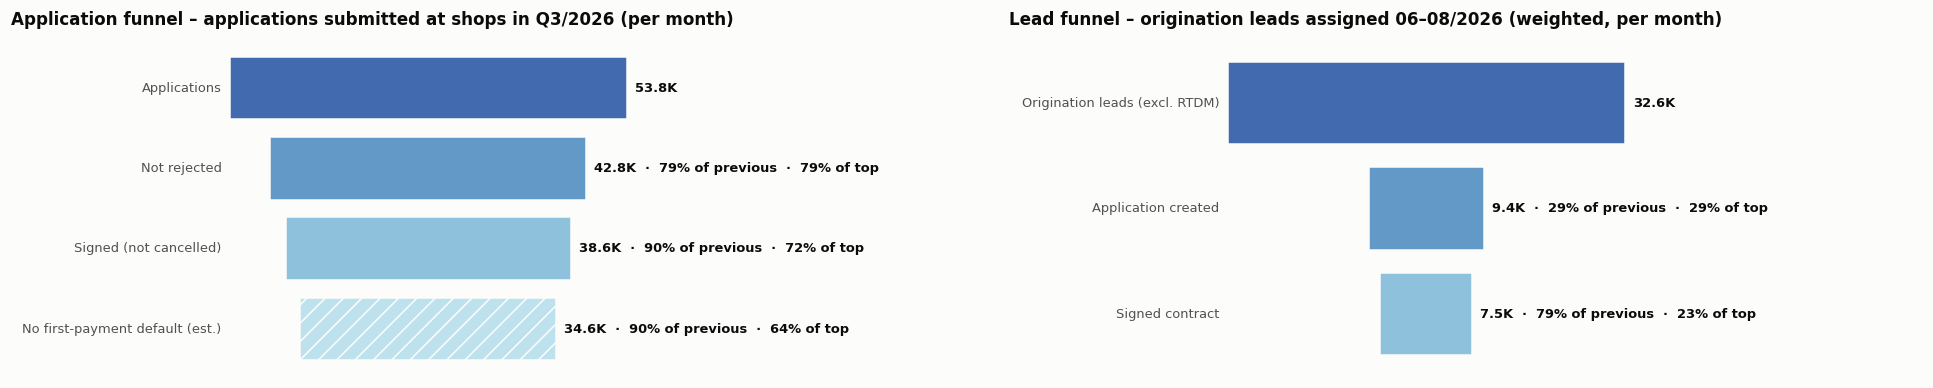

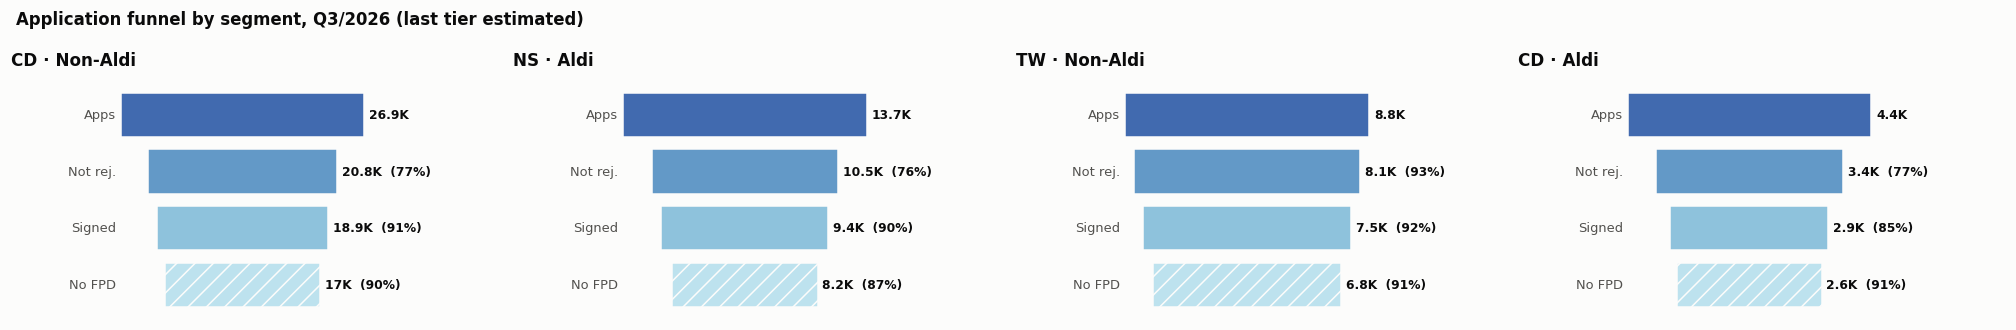

,ho_so,khong_tu_choi,ky,khong_tre,% không bị từ chối,% ký / không bị từ chối,% ký / hồ sơ,% không trễ / hồ sơ (ước tính)
seg,,,,,,,,
CD · Non-Aldi,"26,886","20,773","18,851","17,021",77.3%,90.7%,70.1%,63.3%
NS · Aldi,"13,729","10,472","9,390","8,201",76.3%,89.7%,68.4%,59.7%
TW · Non-Aldi,"8,776","8,144","7,471","6,798",92.8%,91.7%,85.1%,77.5%
CD · Aldi,"4,422","3,383","2,867","2,619",76.5%,84.7%,64.8%,59.2%
Toàn bộ,"53,813","42,773","38,579","34,640",79.5%,90.2%,71.7%,64.4%


Mỗi 100 hồ sơ nộp tại shop (Q3/2026): 79 không bị từ chối → 72 thành HĐ → khoảng 64 HĐ trả đúng kỳ đầu. Khâu rơi nhiều nhất: bị từ chối (21% hồ sơ). Lead ORIGINATION: 29.0% tạo hồ sơ, 23.0% thành HĐ.


In [22]:
fun_q3 = q('''SELECT seg, count(*) / 3 ho_so,
                     count(*) FILTER (WHERE name_status <> 'Rejected') / 3 khong_tu_choi,
                     count(*) FILTER (WHERE is_signed AND name_status <> 'Cancelled') / 3 ky
              FROM ctr WHERE date_apply >= DATE '2026-07-01' AND date_apply < DATE '2026-10-01' GROUP BY 1''').set_index('seg')
fpd_seg = q('''SELECT seg, avg(flag_dpd_1pd) fpd FROM ctr WHERE is_signed AND name_status <> 'Cancelled'
               AND date_sign >= DATE '2025-10-01' AND date_sign < DATE '2026-06-01' AND flag_dpd_1pd IS NOT NULL GROUP BY 1''').set_index('seg').fpd
fun_q3['khong_tre'] = fun_q3.ky * (1 - fun_q3.index.map(fpd_seg).fillna(fpd_seg.mean()))
lead_f = q('''SELECT sum(w) lead, sum(w) FILTER (WHERE converted_apply) ho_so, sum(w) FILTER (WHERE converted_apply AND converted_sign) ky
              FROM lds WHERE id_lead_source <> 'INSTANT_TWO_RTDM' AND lead_flow = 'ORIGINATION'
                AND m >= DATE '2026-06-01' AND m <= DATE '2026-08-01' ''').iloc[0] / 3
TIERS = ['ho_so', 'khong_tu_choi', 'ky', 'khong_tre']
T_EN = ['Applications', 'Not rejected', 'Signed (not cancelled)', 'No first-payment default (est.)']

def funnel(ax, vals, labels, title, est_last=False, compact=False, cmap=(RDYLBU[10], RDYLBU[9], RDYLBU[8], RDYLBU[7])):
    # phễu căn giữa; số liệu đặt bên phải mỗi thanh để không bị tràn ở thanh hẹp
    vals = list(vals); top = vals[0]; y = np.arange(len(vals))[::-1]
    for k, (v, yi) in enumerate(zip(vals, y)):
        hatch = '//' if (est_last and k == len(vals) - 1) else None
        ax.barh(yi, v, left=(top - v) / 2, height=.78, color=cmap[min(k, len(cmap) - 1)], hatch=hatch, edgecolor=SURF)
        if compact:
            txt = human(v) + ('' if k == 0 else f'  ({v / vals[k - 1]:.0%})')
        else:
            txt = human(v) + ('' if k == 0 else f'  ·  {v / vals[k - 1]:.0%} of previous  ·  {v / top:.0%} of top')
        ax.text((top + v) / 2 + top * .02, yi, txt, ha='left', va='center', fontsize=8.5 if not compact else 8, color=INK, fontweight='bold')
        ax.text(-top * .02, yi, labels[k], ha='right', va='center', fontsize=8.5, color=INK2)
    ax.set_xlim(-top * (.45 if compact else .55), top * (1.55 if compact else 1.75)); ax.set_ylim(-.6, len(vals) - .4); ax.axis('off')
    ax.set_title(title, loc='left')

tot = fun_q3[TIERS].sum()
fig, ax = plt.subplots(1, 2, figsize=(18, 3.6))
funnel(ax[0], tot.values, T_EN, 'Application funnel – applications submitted at shops in Q3/2026 (per month)', est_last=True)
funnel(ax[1], lead_f[['lead', 'ho_so', 'ky']].values, ['Origination leads (excl. RTDM)', 'Application created', 'Signed contract'],
       'Lead funnel – origination leads assigned 06–08/2026 (weighted, per month)')
plt.tight_layout(); plt.show()

segs_ = [s_ for s_ in SEG if s_ in fun_q3.index]
fig, ax = plt.subplots(1, len(segs_), figsize=(4.6 * len(segs_), 3.0))
for a_, s_ in zip(np.atleast_1d(ax), segs_):
    v_ = fun_q3.loc[s_, TIERS]
    funnel(a_, v_.values, ['Apps', 'Not rej.', 'Signed', 'No FPD'], f'{s_}', est_last=True, compact=True)
fig.suptitle('Application funnel by segment, Q3/2026 (last tier estimated)', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

tb_f = fun_q3[TIERS].copy(); tb_f.loc['Toàn bộ'] = tot
tb_f['% không bị từ chối'] = tb_f.khong_tu_choi / tb_f.ho_so
tb_f['% ký / không bị từ chối'] = tb_f.ky / tb_f.khong_tu_choi
tb_f['% ký / hồ sơ'] = tb_f.ky / tb_f.ho_so
tb_f['% không trễ / hồ sơ (ước tính)'] = tb_f.khong_tre / tb_f.ho_so
display(tb_f.reindex(segs_ + ['Toàn bộ']).style.format({**{c: '{:,.0f}' for c in TIERS}, **{c: '{:.1%}' for c in tb_f.columns if c.startswith('%')}}))
lost = pd.Series({'Bị từ chối': tot.ho_so - tot.khong_tu_choi, 'Huỷ / chưa hoàn tất sau duyệt': tot.khong_tu_choi - tot.ky,
                  'Trễ kỳ đầu (ước tính)': tot.ky - tot.khong_tre})
print(f"Mỗi 100 hồ sơ nộp tại shop (Q3/2026): {100 * tot.khong_tu_choi / tot.ho_so:.0f} không bị từ chối → {100 * tot.ky / tot.ho_so:.0f} thành HĐ → "
      f"khoảng {100 * tot.khong_tre / tot.ho_so:.0f} HĐ trả đúng kỳ đầu. Khâu rơi nhiều nhất: {lost.idxmax().lower()} "
      f"({lost.max() / tot.ho_so:.0%} hồ sơ). Lead ORIGINATION: {lead_f.ho_so / lead_f.lead:.1%} tạo hồ sơ, {lead_f.ky / lead_f.lead:.1%} thành HĐ.")

### 4.1 Tỷ lệ ký, từ chối, huỷ theo tháng – theo sản phẩm

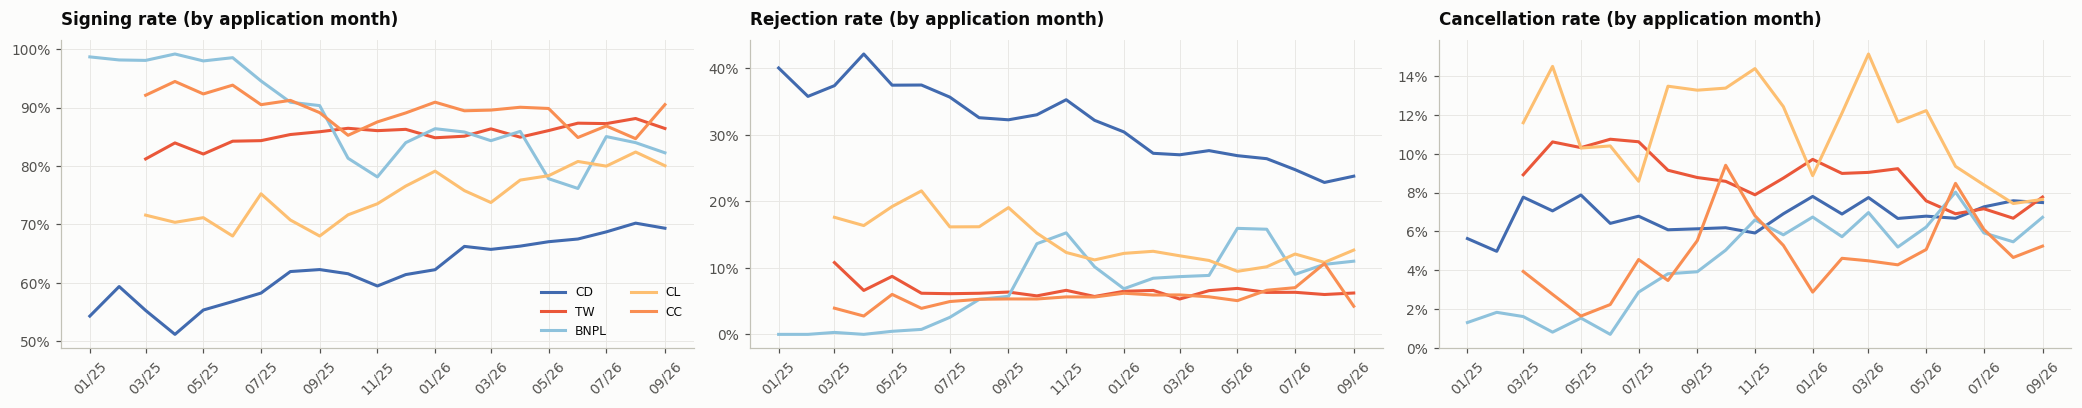

sign                   rej           
thang 2025-04-01 2026-09-01 2025-04-01 2026-09-01
prod                                             
BNPL       99.20      82.30       0.00      11.00
CC         94.50      90.50       2.80       4.20
CD         51.20      69.40      42.20      23.80
CL         70.40      80.10      16.40      12.70
TW         84.00      86.40       6.60       6.20

In [23]:
lr = q('''SELECT thang, prod, count(*) n, 100 * avg(is_signed::INT) sign,
                 100 * avg((name_status = 'Rejected')::INT) rej, 100 * avg((name_status = 'Cancelled')::INT) canc
          FROM ctr WHERE prod IN ('CD','TW','BNPL','CL','CC') GROUP BY ALL HAVING count(*) >= 100 ORDER BY 1''')
fig, ax = plt.subplots(1, 3, figsize=(19, 3.8), sharex=True)
for a, col, t in zip(ax, ['sign', 'rej', 'canc'], ['Tỷ lệ ký', 'Tỷ lệ bị từ chối', 'Tỷ lệ huỷ']):
    for p_ in ['CD', 'TW', 'BNPL', 'CL', 'CC']:
        d = lr[lr['prod'] == p_].sort_values('thang')
        a.plot(pd.to_datetime(d.thang), d[col], color=PCOL[p_], label=p_)
    a.set_title(t + ' (theo tháng nộp hồ sơ)'); a.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v_, _: f'{v_:.0f}%'))
    a.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%m/%y')); a.tick_params(axis='x', rotation=45)
ax[0].legend(loc='lower right', ncol=2)
plt.tight_layout(); plt.show()
first, last = lr.thang.min(), pd.Timestamp('2026-09-01')
cmp_ = lr[lr.thang.isin([pd.Timestamp('2025-04-01'), last])].pivot(index='prod', columns='thang', values=['sign', 'rej'])
display(cmp_.round(1))

### 4.2 Phễu theo phân khúc lớn (theo tháng nộp hồ sơ)
Cùng ba tỷ lệ của mục 4.1 nhưng tách theo phân khúc. Tỷ lệ bị từ chối chủ yếu do chính sách tín dụng; tỷ lệ huỷ phản ánh khâu chốt tại shop.

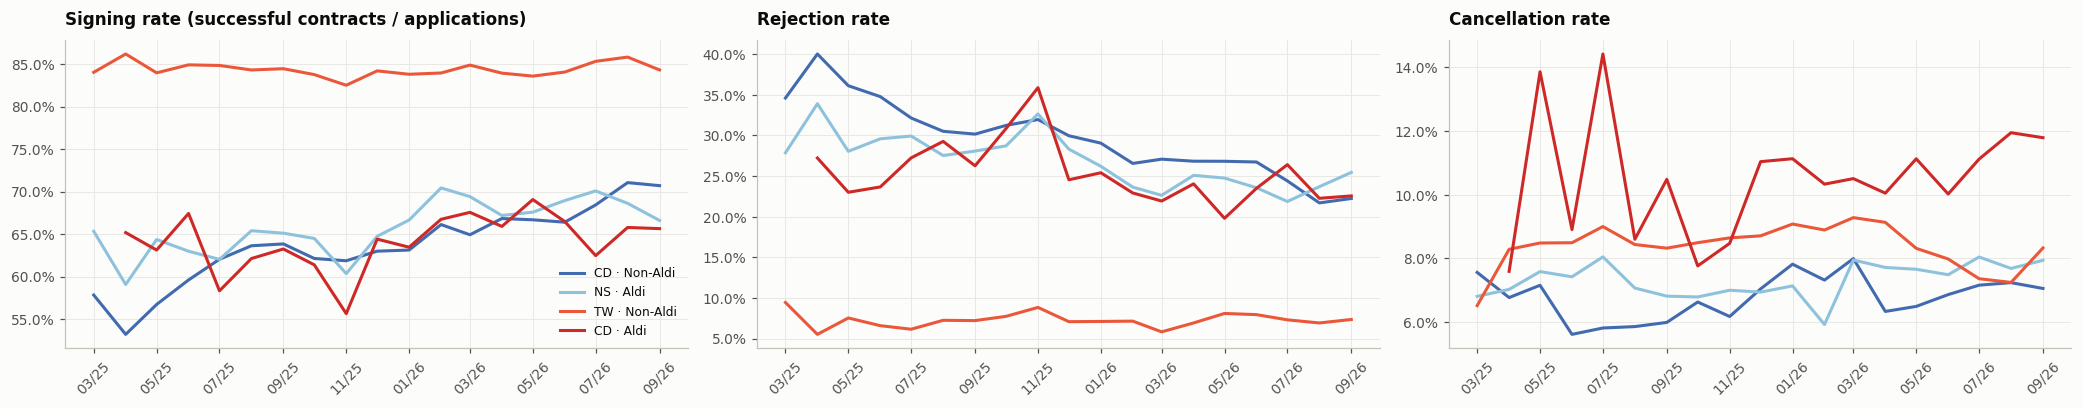

In [24]:
fs = q(f'''SELECT thang, seg, count(*) n, avg((is_signed AND name_status <> 'Cancelled')::INT) ky,
                  avg((name_status = 'Rejected')::INT) tu_choi, avg((name_status = 'Cancelled')::INT) huy
           FROM ctr WHERE seg IN {tuple(SEG)} AND thang >= DATE '2025-03-01' GROUP BY ALL HAVING count(*) >= 200 ORDER BY 1''')
fig, ax = plt.subplots(1, 3, figsize=(19, 3.8), sharex=True)
for a, col, t in zip(ax, ['ky', 'tu_choi', 'huy'], ['Tỷ lệ ký (HĐ thành công / hồ sơ)', 'Tỷ lệ bị từ chối', 'Tỷ lệ huỷ']):
    for sg in SEG:
        d = fs[fs.seg == sg]; a.plot(pd.to_datetime(d.thang), d[col], color=SEGCOL[sg], label=sg)
    a.set_title(t); a.yaxis.set_major_formatter(mtick.PercentFormatter(1))
    a.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%m/%y')); a.tick_params(axis='x', rotation=45)
ax[0].legend(loc='lower right')
plt.tight_layout(); plt.show()
fs['ky_q'] = pd.PeriodIndex(fs.thang, freq='Q')
fq = fs[fs.ky_q.isin([P3p, P2, P3])].assign(**{c: lambda d, c=c: d[c] * d.n for c in ['ky', 'tu_choi', 'huy']})
fq = fq.groupby(['seg', 'ky_q'])[['n', 'ky', 'tu_choi', 'huy']].sum()
fq[['ky', 'tu_choi', 'huy']] = fq[['ky', 'tu_choi', 'huy']].div(fq.n, axis=0)
display(fq[['ky', 'tu_choi', 'huy']].unstack('ky_q').reindex(SEG).style.format('{:.1%}'))

### 4.3 Kết quả hồ sơ theo sản phẩm

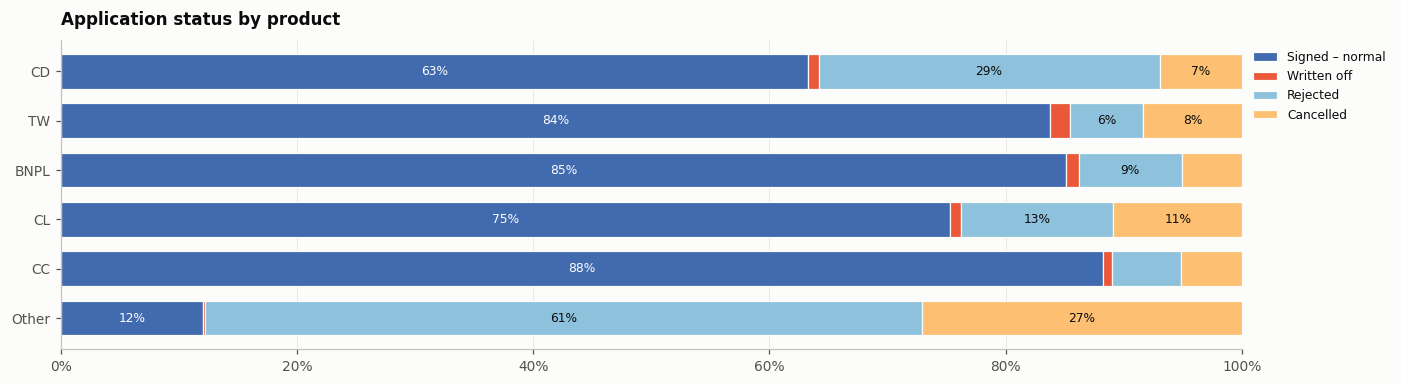

In [25]:
st = q('''SELECT prod, CASE WHEN name_status IN ('Active','Finished','Paid off','Signed') THEN 'Đã ký – bình thường'
                          WHEN name_status = 'Written off' THEN 'Xoá nợ (written off)'
                          WHEN name_status = 'Rejected' THEN 'Từ chối'
                          WHEN name_status = 'Cancelled' THEN 'Huỷ'
                          ELSE 'Đang xử lý' END tt, count(*) n FROM ctr GROUP BY ALL''')
SCOL = {'Đã ký – bình thường': BLUE, 'Xoá nợ (written off)': ORANGE, 'Từ chối': AQUA, 'Huỷ': YELLOW, 'Đang xử lý': GREY}
p = st.pivot(index='prod', columns='tt', values='n').fillna(0)
p = p.reindex([x for x in PORDER if x in p.index])[[c for c in SCOL if c in p.columns]]
p = p.div(p.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(13, 3.6))
left = np.zeros(len(p)); y = np.arange(len(p))
for c in p.columns:
    ax.barh(y, p[c], left=left, color=SCOL[c], label=c, height=.7, edgecolor=SURF, linewidth=.8)
    for yi, (l, v) in enumerate(zip(left, p[c])):
        if v >= 6: ax.text(l + v / 2, yi, f'{v:.0f}%', ha='center', va='center', fontsize=8, color='white' if c == 'Đã ký – bình thường' else INK)
    left += p[c].values
ax.set_yticks(y, p.index); ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.grid(axis='y', visible=False)
ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0)); ax.set_title('Phân bổ trạng thái hồ sơ theo sản phẩm')
plt.tight_layout(); plt.show()

### 4.4 Quy mô khoản vay & kỳ hạn (hợp đồng đã ký)

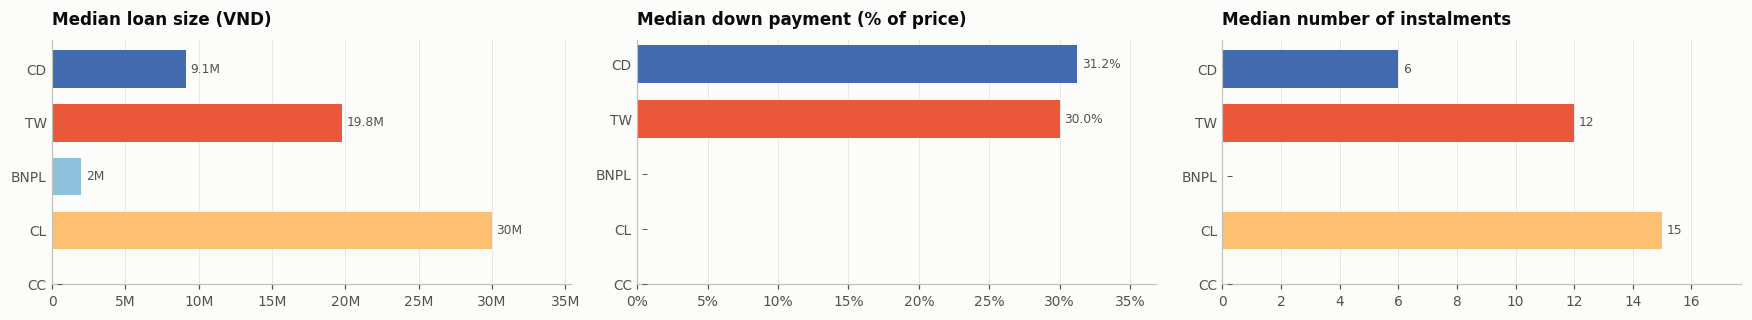

,prod,n,med_loan,med_price,med_init_pct,med_term
0,CD,291848,"9,100,000.00","14,000,000.00",31.24,6.00
1,TW,63310,"19,800,000.00","26,200,000.00",30.00,12.00
2,BNPL,37825,"2,000,000.00",NaN,NaN,NaN
3,CL,18956,"30,000,000.00",NaN,NaN,15.00
4,CC,16203,NaN,NaN,NaN,NaN


In [26]:
tk = q('''SELECT prod, count(*) n, median(loan_amount_eff) med_loan, median(price) med_price,
                 100 * median(init_pay / nullif(price, 0)) med_init_pct, median(payment_num) med_term
          FROM ctr WHERE is_signed AND prod <> 'Khác' GROUP BY 1''').set_index('prod').reindex([p for p in PORDER if p != 'Khác']).reset_index()
fig, ax = plt.subplots(1, 3, figsize=(16, 3))
barh(ax[0], tk['prod'], tk.med_loan, 'Khoản vay trung vị (VND)', color=[PCOL[x] for x in tk['prod']])
barh(ax[1], tk['prod'], tk.med_init_pct, 'Trả trước trung vị (% giá hàng)', pct=True, color=[PCOL[x] for x in tk['prod']])
barh(ax[2], tk['prod'], tk.med_term, 'Số kỳ trả góp trung vị', fmt=lambda v: '–' if not np.isfinite(v) else f'{v:.0f}', color=[PCOL[x] for x in tk['prod']])
plt.tight_layout(); plt.show()
display(tk)

### 4.5 Quy mô khoản vay theo thời gian (HĐ đã ký, trung vị theo tháng ký)

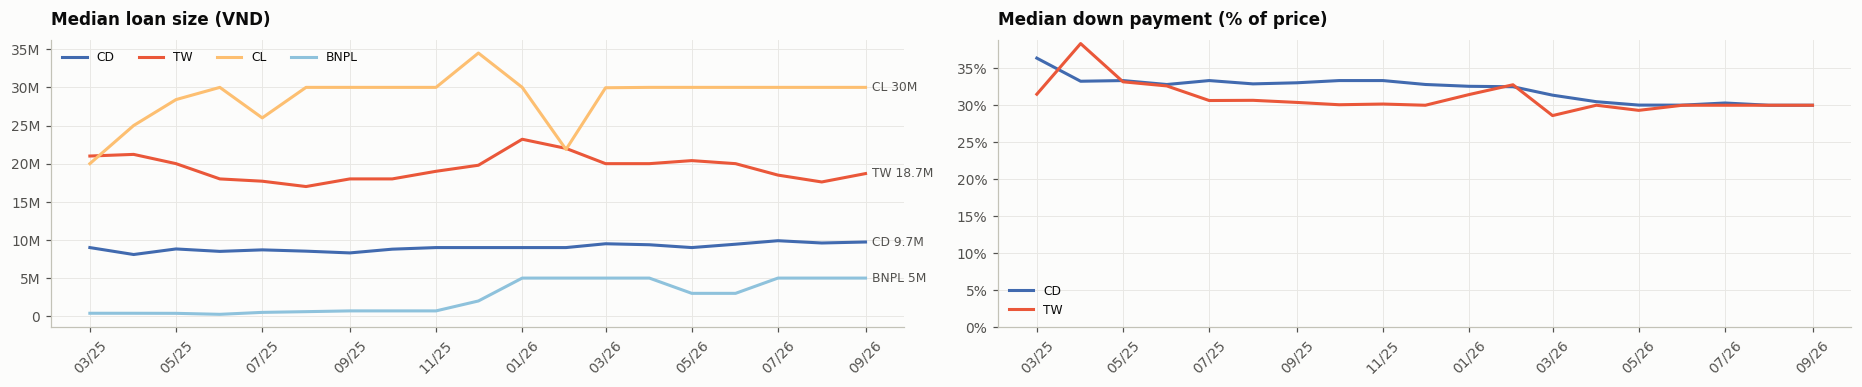

In [27]:
tk_m = q('''SELECT m_sign m, prod, median(loan_amount_eff) med, 100 * median(init_pay / nullif(price, 0)) init_pct
            FROM ctr WHERE is_signed AND prod IN ('CD','TW','CL','BNPL') AND m_sign BETWEEN DATE '2025-03-01' AND DATE '2026-09-01'
            GROUP BY ALL ORDER BY 1''')
fig, ax = plt.subplots(1, 2, figsize=(17, 3.6))
for p_ in ['CD', 'TW', 'CL', 'BNPL']:
    d = tk_m[tk_m['prod'] == p_]
    ax[0].plot(pd.to_datetime(d.m), d.med, color=PCOL[p_], label=p_)
    ax[0].annotate(f'{p_} {human(d.med.iloc[-1])}', (pd.to_datetime(d.m).iloc[-1], d.med.iloc[-1]), xytext=(4, 0), textcoords='offset points', fontsize=8, color=INK2, va='center')
for p_ in ['CD', 'TW']:
    d = tk_m[tk_m['prod'] == p_]
    ax[1].plot(pd.to_datetime(d.m), d.init_pct, color=PCOL[p_], label=p_)
ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(human)); ax[0].set_title('Khoản vay trung vị (VND)'); ax[0].legend(loc='upper left', ncol=4)
ax[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v_, _: f'{v_:.0f}%')); ax[1].set_title('Trả trước trung vị (% giá hàng)'); ax[1].legend(loc='lower left')
ax[1].set_ylim(0, None)
for a in ax: a.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%m/%y')); a.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

### 4.6 Hàng hoá được mua (CD / TW, hợp đồng đã ký)

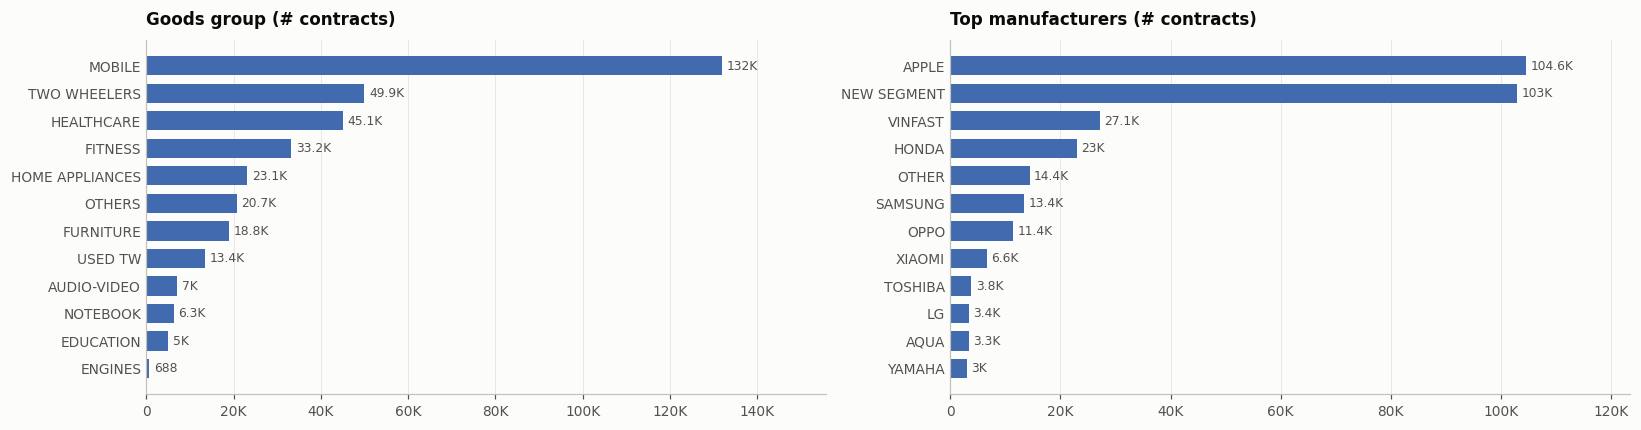

In [28]:
gd = q('''SELECT cp.goods_group, count(DISTINCT c.skp_credit_case) n FROM ctr c JOIN contract_product cp USING (skp_credit_case)
          WHERE c.is_signed GROUP BY 1 ORDER BY 2 DESC LIMIT 12''')
br = q('''SELECT cp.name_producer, count(DISTINCT c.skp_credit_case) n FROM ctr c JOIN contract_product cp USING (skp_credit_case)
          WHERE c.is_signed AND cp.name_producer IS NOT NULL GROUP BY 1 ORDER BY 2 DESC LIMIT 12''')
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
barh(ax[0], gd.goods_group, gd.n, 'Nhóm hàng (số HĐ)')
barh(ax[1], br.name_producer, br.n, 'Top hãng sản xuất (số HĐ)')
plt.tight_layout(); plt.show()

> **Key point 4 – Tỷ lệ vay: CD cải thiện mạnh nhưng vẫn là điểm nghẽn; tỷ lệ ký BNPL giảm**
> - *Tỷ lệ ký* = HĐ ký / hồ sơ, **không phải tỷ lệ duyệt** (xem ghi chú đầu mục 4).
> - **CD**: tỷ lệ ký tăng từ 51% (04/2025) lên **69%** (09/2026), tỷ lệ từ chối giảm từ 42% xuống 24%. Đây là cải thiện lớn nhất, nhưng CD vẫn có tỷ lệ ký thấp nhất trong khi chiếm khoảng 75% hồ sơ của shop mới.
> - **BNPL**: tỷ lệ ký giảm từ 99% xuống **82%**, tỷ lệ từ chối tăng từ 0% lên 11%. Cần kiểm tra thêm chính sách duyệt, cơ cấu khách và nguồn hồ sơ trước khi kết luận nguyên nhân (dữ liệu không cho biết lý do từ chối).
> - CL tăng từ 70% lên 80%; TW (khoảng 86%) và CC (khoảng 90%) ổn định. Tỷ lệ huỷ ở mọi sản phẩm vào khoảng 5–8%.
> - Quy mô khoản vay ổn định (CD khoảng 9–10M, TW 18–20M, CL 30M), trả trước khoảng 30% giá hàng. Riêng BNPL tăng từ dưới 1M lên **5M** kể từ 01/2026.

## 5. Chân dung khách hàng
### 5.1 Hành vi khách (từ dữ liệu Round 3)

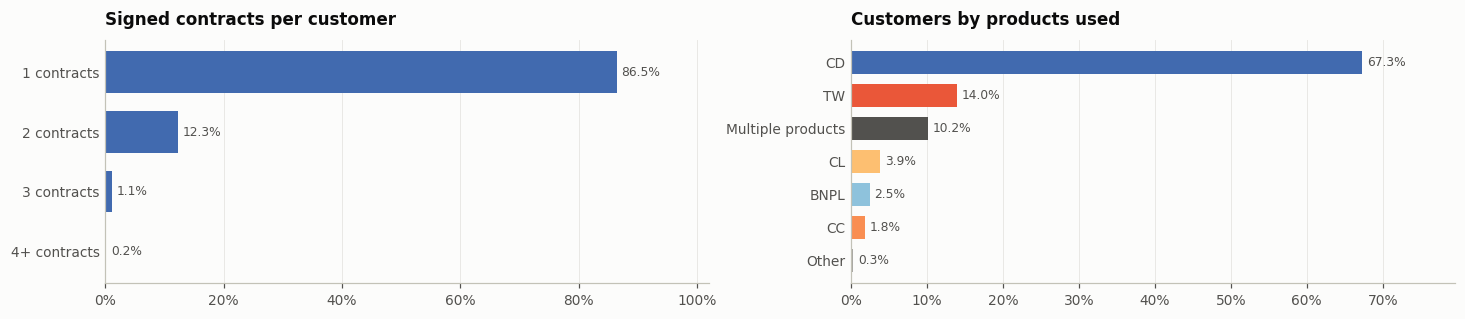

In [29]:
cc = q('''SELECT CASE WHEN n >= 4 THEN '4+' ELSE n::VARCHAR END so_hd, count(*) n_khach FROM
          (SELECT skp_client, count(*) n FROM ctr WHERE is_signed GROUP BY 1) GROUP BY 1 ORDER BY 1''')
cc['p'] = 100 * cc.n_khach / cc.n_khach.sum()
mp = q('''SELECT CASE WHEN n_prod = 1 THEN first_prod ELSE 'Nhiều sản phẩm' END nhom, count(*) n FROM
          (SELECT skp_client, count(DISTINCT prod) n_prod, min(prod) first_prod FROM ctr WHERE is_signed GROUP BY 1)
          GROUP BY 1 ORDER BY 2 DESC''')
mp['p'] = 100 * mp.n / mp.n.sum()
fig, ax = plt.subplots(1, 2, figsize=(13, 3))
barh(ax[0], cc.so_hd + ' HĐ', cc.p, 'Số hợp đồng đã ký trên mỗi khách', pct=True)
barh(ax[1], mp.nhom, mp.p, 'Khách theo sản phẩm đã dùng', pct=True,
     color=[PCOL.get(v, GREY) if v != 'Nhiều sản phẩm' else INK2 for v in mp.nhom])
plt.tight_layout(); plt.show()

### 5.2 Shop là cửa ngõ thu hút khách: khách mới và vay thêm
Trong tài chính tiêu dùng, shop đối tác thường là nơi **thu hút khách mới** bằng khoản vay mua hàng (CD / TW); giá trị lớn hơn đến sau, khi khách quay lại vay tiền mặt hoặc mở thẻ (CL / CC / CW), thường qua kênh online.
- **Khách mới / khách cũ:** khách có HĐ thành công tại shop vật lý trong Q3/2026; "khách cũ" = đã có HĐ thành công trước đó ở bất kỳ kênh nào **từ 01/2025** (dữ liệu bắt đầu 01/2025, nên tỷ lệ khách mới là **cận trên**).
- **Vay thêm:** khách có HĐ đầu tiên là **CD / TW tại shop vật lý** trong 03–09/2025, theo dõi 12 tháng sau (bỏ hợp đồng trong vòng 1 ngày, tức mua kèm tại quầy): bao nhiêu khách vay thêm CL / CC / CW và vay ở **kênh nào**.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,khach,ty_le_khach_cu,shop_mo,khach_moi_shop_thang
seg,,,,
CD · Non-Aldi,"53,269",19%,"6,182",2.3
NS · Aldi,"27,924",12%,"3,519",2.3
TW · Non-Aldi,"20,712",18%,"2,318",2.4
CD · Aldi,"8,428",17%,66,35.2


,Khách (cohort),% vay thêm trong 12 tháng,nơi vay: Cùng shop,nơi vay: Shop vật lý khác,nơi vay: Online hub,nơi vay: POS ngoài danh sách shop
seg,,,,,,
Toàn bộ,"53,515",9.1%,4.8%,3.6%,52.6%,39.0%
CD · Non-Aldi,"25,200",11.8%,6.7%,3.7%,50.0%,39.6%
NS · Aldi,"19,140",6.0%,0.0%,3.0%,60.4%,36.6%
TW · Non-Aldi,"7,318",8.6%,5.4%,5.1%,48.6%,40.9%
CD · Aldi,"1,857",6.8%,0.0%,0.8%,63.0%,36.2%


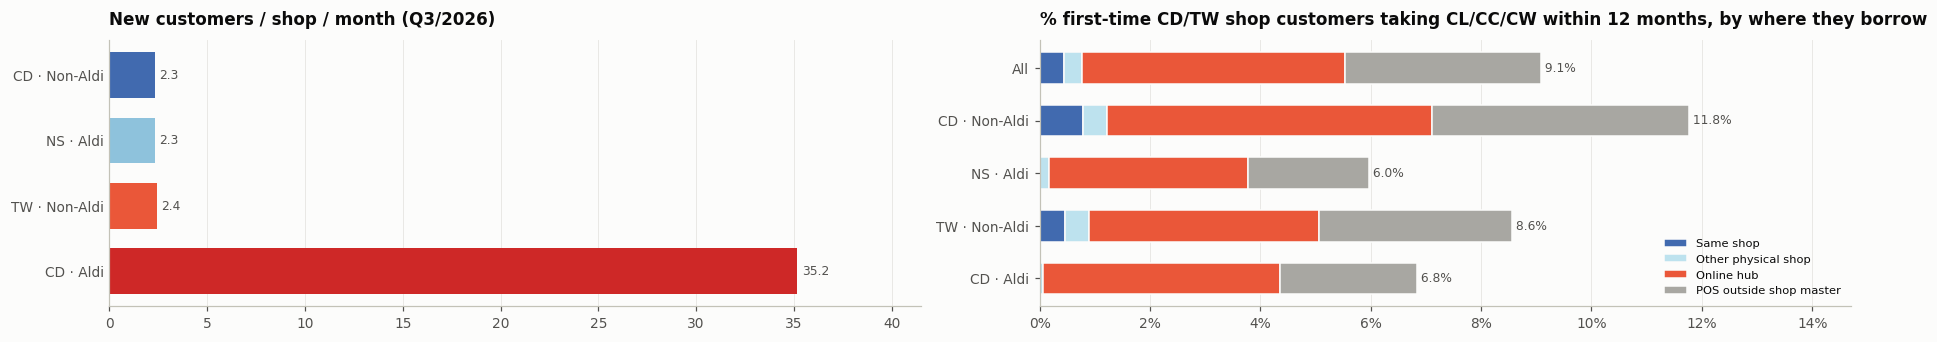

83% khách có HĐ tại shop Q3/2026 là khách mới (cận trên). 9.1% khách CD/TW lần đầu tại shop vay thêm CL/CC/CW trong 12 tháng; 95% trong số đó vay ở nơi khác, chủ yếu online hub (53%).


In [30]:
con.sql(f'''CREATE OR REPLACE TABLE allc AS
SELECT c.skp_client, c.skp_salesroom, c.date_apply, c.product,
       CASE WHEN s.salesroom_category IN ('Big','Medium','Small') THEN 'Shop vật lý' WHEN s.skp_salesroom IS NOT NULL THEN 'Shop ảo (Virtual)'
            WHEN h.skp_salesroom IS NOT NULL THEN 'Online hub' ELSE 'POS ngoài danh sách shop' END kenh,
       s.salesroom_product || ' · ' || s.salesroom_model seg
FROM {rd('contract')} c LEFT JOIN salesroom s USING (skp_salesroom)
LEFT JOIN (SELECT skp_salesroom FROM {rd('contract')} WHERE is_signed AND name_status <> 'Cancelled'
           GROUP BY 1 HAVING count(*) >= 50000) h USING (skp_salesroom)
WHERE c.is_signed AND c.name_status <> 'Cancelled' AND c.skp_client > 0''')
nr = q(f'''WITH f AS (SELECT skp_client, min(date_apply) f FROM allc GROUP BY 1),
              cu AS (SELECT skp_client, seg, min(date_apply) t FROM allc
                     WHERE kenh = 'Shop vật lý' AND date_apply >= DATE '2026-07-01' AND date_apply < DATE '2026-10-01' GROUP BY ALL)
         SELECT seg, count(*) khach, avg((f.f < cu.t)::INT) ty_le_khach_cu FROM cu JOIN f USING (skp_client)
         WHERE seg IN {tuple(SEG)} GROUP BY 1''').set_index('seg').reindex(SEG)
nr['shop_mo'] = q("SELECT seg, count(*) n FROM shop WHERE category <> 'Virtual' AND (m_close IS NULL OR m_close > DATE '2026-09-01') GROUP BY 1").set_index('seg').n
nr['khach_moi_shop_thang'] = nr.khach * (1 - nr.ty_le_khach_cu) / 3 / nr.shop_mo
xs = q(f'''WITH fr AS (SELECT * FROM allc QUALIFY row_number() OVER (PARTITION BY skp_client ORDER BY date_apply, skp_salesroom) = 1),
              coh AS (SELECT skp_client, skp_salesroom room0, seg, date_apply t0 FROM fr
                      WHERE kenh = 'Shop vật lý' AND product IN ('CD','TW') AND date_apply >= DATE '2025-03-01' AND date_apply < DATE '2025-10-01'),
              nx AS (SELECT c.skp_client,
                            arg_min(CASE WHEN b.skp_salesroom = c.room0 THEN 'Cùng shop' WHEN b.kenh = 'Shop vật lý' THEN 'Shop vật lý khác' ELSE b.kenh END,
                                    b.date_apply) noi
                     FROM coh c JOIN allc b ON b.skp_client = c.skp_client AND b.product IN ('CL','CC','CW')
                          AND b.date_apply > c.t0 + INTERVAL 1 DAY AND b.date_apply <= c.t0 + INTERVAL 365 DAY GROUP BY 1)
         SELECT coh.seg, coalesce(nx.noi, 'Không vay thêm') noi, count(*) khach FROM coh LEFT JOIN nx USING (skp_client) GROUP BY ALL''')
xp = xs.pivot_table(index='seg', columns='noi', values='khach', aggfunc='sum').fillna(0)
xp.loc['Toàn bộ'] = xp.sum()
xp = xp.reindex([g for g in ['Toàn bộ'] + SEG if g in xp.index])
NOI = [c for c in ['Cùng shop', 'Shop vật lý khác', 'Online hub', 'POS ngoài danh sách shop', 'Shop ảo (Virtual)'] if c in xp.columns]
xs_tab = pd.DataFrame({'Khách (cohort)': xp.sum(axis=1), '% vay thêm trong 12 tháng': xp[NOI].sum(axis=1) / xp.sum(axis=1)})
for c_ in NOI: xs_tab[f'nơi vay: {c_}'] = xp[c_] / xp[NOI].sum(axis=1)
display(nr.style.format({'khach': '{:,.0f}', 'ty_le_khach_cu': '{:.0%}', 'shop_mo': '{:,.0f}', 'khach_moi_shop_thang': '{:.1f}'}))
display(xs_tab.style.format('{:.1%}').format('{:,.0f}', subset=['Khách (cohort)']))
fig, ax = plt.subplots(1, 2, figsize=(17, 3.2))
barh(ax[0], nr.index, nr.khach_moi_shop_thang, 'Khách mới / shop / tháng (Q3/2026)', color=[SEGCOL[x] for x in nr.index], fmt=lambda v: f'{v:.1f}')
NCOL = {'Cùng shop': BLUE, 'Shop vật lý khác': '#bde2ee', 'Online hub': ORANGE, 'POS ngoài danh sách shop': GREY, 'Shop ảo (Virtual)': INK2}
share_ = xp[NOI].div(xp.sum(axis=1), axis=0); left = np.zeros(len(share_)); y = np.arange(len(share_))
for c_ in NOI:
    ax[1].barh(y, share_[c_], left=left, color=NCOL[c_], label=c_, height=.6, edgecolor=SURF); left += share_[c_].values
for yi, v_ in zip(y, left): ax[1].text(v_, yi, f' {v_:.1%}', va='center', fontsize=8, color=INK2)
ax[1].set_yticks(y, share_.index); ax[1].invert_yaxis(); ax[1].xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax[1].set_xlim(0, left.max() * 1.25); ax[1].grid(axis='y', visible=False); ax[1].legend(loc='lower right', fontsize=7.5)
ax[1].set_title('% khách CD/TW lần đầu tại shop vay thêm CL/CC/CW trong 12 tháng, theo nơi vay')
plt.tight_layout(); plt.show()
xs_tot = xs_tab.loc['Toàn bộ']
print(f"{1 - (nr.khach * nr.ty_le_khach_cu).sum() / nr.khach.sum():.0%} khách có HĐ tại shop Q3/2026 là khách mới (cận trên). "
      f"{xs_tot['% vay thêm trong 12 tháng']:.1%} khách CD/TW lần đầu tại shop vay thêm CL/CC/CW trong 12 tháng; "
      f"{1 - xs_tot['nơi vay: Cùng shop']:.0%} trong số đó vay ở nơi khác, chủ yếu online hub ({xs_tot.get('nơi vay: Online hub', 0):.0%}).")

## 6. Năng suất shop – Current Actual
Chỉ xét shop vật lý **mở trước 04/2026 và còn hoạt động hết 09/2026** (bảng `cur`, cùng phạm vi với mục 7).

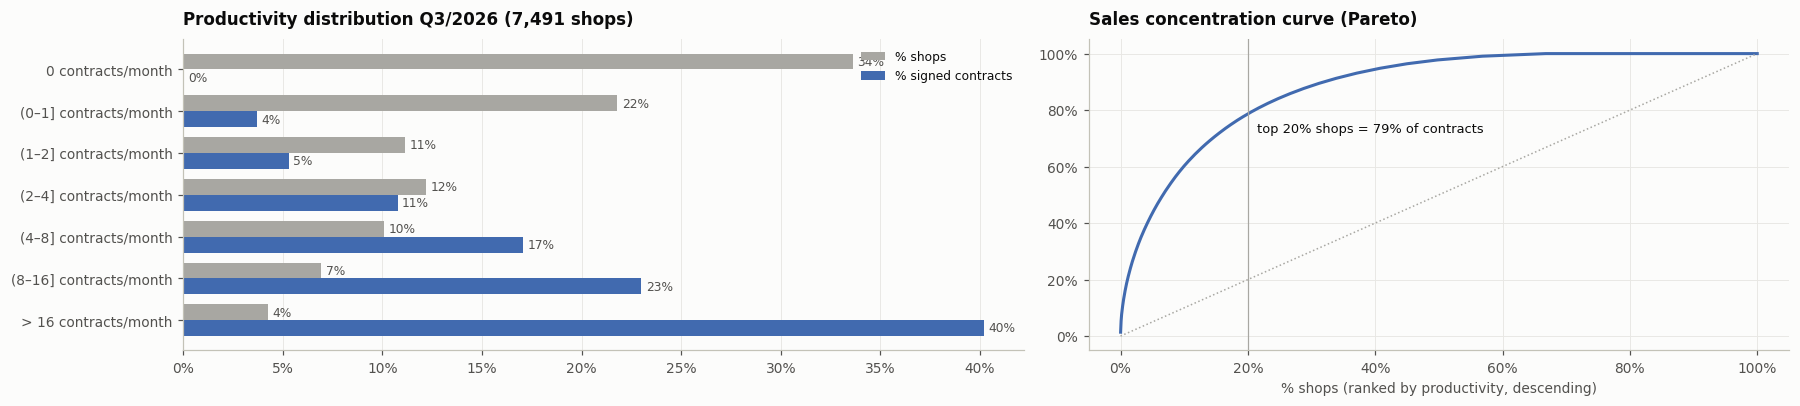

Trung vị 0.67 · TB 3.45 · P75 3.33 · P90 9.00 HĐ/tháng; top 50% shop = 98% HĐ


In [31]:
cu = q('SELECT * FROM cur')
bins = [-0.01, 0, 1, 2, 4, 8, 16, 1e9]; names = ['0', '(0–1]', '(1–2]', '(2–4]', '(4–8]', '(8–16]', '> 16']
cu['b'] = pd.cut(cu.sign_m, bins, labels=names)
h = cu.groupby('b', observed=False).agg(n=('sign_m', 'size'), hd=('sign_m', 'sum')).reset_index()
h['p_shop'] = 100 * h.n / h.n.sum(); h['p_hd'] = 100 * h.hd / h.hd.sum()
s = cu.sign_m.sort_values(ascending=False).values
cum = np.cumsum(s) / s.sum() * 100; xs = np.arange(1, len(s) + 1) / len(s) * 100
top20 = cum[int(len(s) * .2) - 1]; top50 = cum[int(len(s) * .5) - 1]

fig, ax = plt.subplots(1, 2, figsize=(16, 3.8), gridspec_kw={'width_ratios': [1.2, 1]})
y = np.arange(len(h)); hh = .38
ax[0].barh(y - hh / 2, h.p_shop, hh, color=GREY, label='% số shop')
ax[0].barh(y + hh / 2, h.p_hd, hh, color=BLUE, label='% số HĐ ký')
for yi, a, b in zip(y, h.p_shop, h.p_hd):
    ax[0].annotate(f'{a:.0f}%', (a, yi - hh / 2), xytext=(3, 0), textcoords='offset points', va='center', fontsize=8, color=INK2)
    ax[0].annotate(f'{b:.0f}%', (b, yi + hh / 2), xytext=(3, 0), textcoords='offset points', va='center', fontsize=8, color=INK2)
ax[0].set_yticks(y, [n + ' HĐ/tháng' for n in names]); ax[0].invert_yaxis(); ax[0].legend(loc='upper right')
ax[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:.0f}%')); ax[0].grid(axis='y', visible=False)
ax[0].set_title(f'Phân bố năng suất Q3/2026 ({len(cu):,} shop)')
ax[1].plot(xs, cum, color=BLUE); ax[1].plot([0, 100], [0, 100], color=GREY, ls=':', lw=1)
ax[1].axvline(20, color=GREY, lw=.8); ax[1].annotate(f'top 20% shop = {top20:.0f}% HĐ', (20, top20), xytext=(6, -12), textcoords='offset points', fontsize=8.5)
ax[1].set_xlabel('% shop (xếp theo năng suất giảm dần)'); ax[1].set_title('Đường tập trung doanh số (Pareto)')
for a in (ax[1].xaxis, ax[1].yaxis): a.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:.0f}%'))
plt.tight_layout(); plt.show()
print(f"Trung vị {cu.sign_m.median():.2f} · TB {cu.sign_m.mean():.2f} · P75 {cu.sign_m.quantile(.75):.2f} · P90 {cu.sign_m.quantile(.9):.2f} HĐ/tháng; top 50% shop = {top50:.0f}% HĐ")

### 6.1 Năng suất theo nhóm shop
Đã gộp vào mục 7 để cả notebook chỉ dùng **một cách chia nhóm**: nhóm peer = dòng hàng × mô hình × quy mô × loại đại lý (gộp lên cấp cha nếu < 30 shop).
Phân bố HĐ / tháng trong từng nhóm xem **7.2**, bảng trung vị theo nhóm xem **7.9**.

## 7. Hiện trạng cửa hàng theo phân khúc – bộ chỉ số ngành tài chính tiêu dùng

**Câu hỏi của phần này:** *các cửa hàng cùng phân khúc đang hoạt động thế nào, đo bằng bộ chỉ số mà các công ty tài chính tiêu dùng dùng để theo dõi đối tác?*
Đây là phần **Current Actual** của đề. Các phần BAU, Attainable và Ceiling làm ở notebook sau.

Mục này dùng kết nối dữ liệu riêng (`cons`) nên không ảnh hưởng các bảng của notebook.

**Phạm vi:**
- Shop vật lý (bỏ shop online) mở trước 04/2026 và còn mở hết 30/09/2026: đủ ≥ 2 quý hoạt động.
- Kỳ đo: hồ sơ nộp trong **Q3/2026**, tính theo tháng.
- HĐ tính cho **shop nơi xử lý hồ sơ**.
- Chỉ dùng dữ liệu Round 3.

| Nhóm | Chỉ số | Cách tính với dữ liệu Round 3 |
|---|---|---|
| Quy mô | **HĐ thành công / tháng** | hồ sơ đã ký và không bị huỷ sau ký |
| Quy mô | **Giá trị khoản vay đã ký / tháng** | tổng `loan_amount_eff` của HĐ thành công (BNPL lấy từ số tiền hoá đơn kỳ đầu; CC không có số tiền giải ngân) |
| Giá trị giao dịch | **Khoản vay bình quân** | giá trị khoản vay đã ký ÷ HĐ thành công (không tính CC) |
| Đầu vào | **Hồ sơ / tháng** | mọi hồ sơ nộp trong kỳ |
| Phễu | **Tỷ lệ không bị từ chối** | ký ÷ (ký + từ chối) = **cận trên của tỷ lệ duyệt** (xem ghi chú đầu mục 4); không gọi là tỷ lệ duyệt |
| Phễu | **Tỷ lệ hoàn tất** | HĐ thành công ÷ hồ sơ không bị từ chối; phần còn lại là khách huỷ |
| Phễu | **Chuyển đổi tổng thể** | HĐ thành công ÷ hồ sơ (cùng nhóm hồ sơ nộp trong kỳ) |
| Vận hành | **Thời gian xử lý** | phút từ nộp hồ sơ đến ký (dữ liệu không có thời điểm duyệt) |
| Nhân sự | **HĐ / SA quy đổi** | mỗi SA chia đều cho các shop được gán trong quý; chỉ áp dụng shop **Non-Aldi** (shop Aldi do nhân viên của đối tác làm hồ sơ) |
| Rủi ro | **Trễ kỳ đầu (FPD) · trễ ≥ 1 kỳ trong 4 kỳ đầu** | trên HĐ ký 10/2025–05/2026 (đủ ≥ 4 tháng để quan sát) |
| Kinh tế | Lợi nhuận đóng góp sau rủi ro | **không tính được**: không có dữ liệu lãi suất, hoa hồng, chi phí |

In [32]:
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mtick, pathlib
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 220)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
CLEAN = pathlib.Path('data_clean')
OUT = pathlib.Path('output'); OUT.mkdir(exist_ok=True)

# bảng màu tham chiếu (categorical cố định thứ tự, ramp xanh tuần tự), chữ dùng màu chữ, không dùng màu series
SURF, TXT, TXT2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
C1, C2, C3, C4 = '#416aaf', '#ea5739', '#8ec2dc', '#fdbf71'
SEQ = ['#bde2ee', '#bde2ee', '#8ec2dc', '#6399c7', '#416aaf', '#416aaf', '#416aaf']
plt.rcParams.update({'figure.dpi': 110, 'figure.facecolor': SURF, 'axes.facecolor': SURF, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.spines.left': False, 'axes.edgecolor': GRID, 'axes.grid': True,
                     'grid.color': GRID, 'grid.linewidth': .6, 'axes.axisbelow': True, 'axes.titleweight': 'bold',
                     'axes.titlesize': 10.5, 'axes.titlelocation': 'left', 'axes.titlecolor': TXT, 'font.size': 9,
                     'text.color': TXT, 'axes.labelcolor': TXT2, 'xtick.color': TXT2, 'ytick.color': TXT2,
                     'legend.frameon': False})
cons = duckdb.connect(); cons.sql("SET preserve_insertion_order=false")
rd = lambda t: f"read_csv('{(CLEAN / (t + '.csv')).as_posix()}', sample_size=200000)"
Q_FROM, Q_TO = '2026-07-01', '2026-10-01'            # hồ sơ nộp Q3/2026
R_FROM, R_TO = '2025-10-01', '2026-06-01'            # HĐ ký đủ ≥ 4 tháng để quan sát trễ hạn

cons.sql(f'''CREATE TABLE shop AS
SELECT skp_salesroom, salesroom_category category, salesroom_model model,
       CASE WHEN salesroom_product IN ('CD','TW','NS') THEN salesroom_product ELSE 'NS' END line,
       coalesce(seller_type, 'Stone Shop') seller_type, skp_seller, province_std, salesroom_area area, salesroom_start, salesroom_end
FROM {rd('salesroom')}
WHERE salesroom_category <> 'Virtual' AND salesroom_start < DATE '2026-04-01'
  AND (salesroom_end IS NULL OR salesroom_end >= DATE '2026-10-01')''')
cons.sql(f'''CREATE TABLE c AS
SELECT skp_salesroom, product, name_status, date_apply, date_sign, loan_amount_eff, ins_amount, flag_dpd_1pd, flag_any_dpd,
       is_signed AND name_status <> 'Cancelled' ok,                       -- HĐ thành công
       name_status = 'Rejected' rej,
       name_status = 'Cancelled' AND NOT is_signed cancel_pre,           -- huỷ trước khi ký
       name_status = 'Cancelled' AND is_signed cancel_post               -- huỷ sau khi ký
FROM {rd('contract')} WHERE skp_salesroom IN (SELECT skp_salesroom FROM shop)''')
print(cons.sql('SELECT count(*) shop FROM shop').fetchone()[0], 'shop trong phạm vi')

7491 shop trong phạm vi


In [33]:
# ---- chỉ số theo shop -------------------------------------------------------------------------------------------
k = cons.sql(f'''
SELECT skp_salesroom,
  count(*) / 3 apps_m,
  count(*) FILTER (WHERE ok) / 3 ok_m,
  count(*) FILTER (WHERE rej) / 3 rej_m,
  count(*) FILTER (WHERE cancel_pre OR cancel_post) / 3 cancel_m,
  sum(loan_amount_eff) FILTER (WHERE ok) / 3 fund_m,
  sum(loan_amount_eff) FILTER (WHERE ok AND product <> 'CC') / nullif(count(*) FILTER (WHERE ok AND product <> 'CC'), 0) ticket,
  median(date_diff('minute', date_apply, date_sign)) FILTER (WHERE ok) proc_min,
  count(*) FILTER (WHERE ok AND product IN ('CD','TW','CL') AND ins_amount > 0) / nullif(count(*) FILTER (WHERE ok AND product IN ('CD','TW','CL')), 0) ins_rate
FROM c WHERE date_apply >= '{Q_FROM}' AND date_apply < '{Q_TO}' GROUP BY 1''').df()
r = cons.sql(f'''SELECT skp_salesroom, count(*) n_risk, avg(flag_dpd_1pd) fpd, avg(flag_any_dpd) dpd14
                FROM c WHERE ok AND date_sign >= '{R_FROM}' AND date_sign < '{R_TO}' GROUP BY 1''').df()
mix = cons.sql(f'''SELECT skp_salesroom, product, count(*) n FROM c
                  WHERE ok AND date_apply >= '{Q_FROM}' AND date_apply < '{Q_TO}' GROUP BY 1, 2''').df()
# SA quy đổi trong Q3: mỗi SA chia đều cho các shop được gán trong quý
sa = cons.sql(f'''WITH e AS (SELECT DISTINCT skp_employee, skp_salesroom FROM {rd('emp_2_salesroom')}
                            WHERE role = 'SA' AND dtime_valid_from < '{Q_TO}' AND (dtime_valid_to IS NULL OR dtime_valid_to >= '{Q_FROM}')),
                      n AS (SELECT skp_employee, count(*) n_shop FROM e GROUP BY 1)
                 SELECT e.skp_salesroom, sum(1.0 / n.n_shop) sa_fte, count(*) sa_assigned
                 FROM e JOIN n USING (skp_employee) GROUP BY 1''').df()
s = cons.sql('SELECT * FROM shop').df()
s = s.merge(k, on='skp_salesroom', how='left').merge(r, on='skp_salesroom', how='left').merge(sa, on='skp_salesroom', how='left')
cnt = ['apps_m', 'ok_m', 'rej_m', 'cancel_m', 'fund_m', 'sa_fte', 'sa_assigned']
s[cnt] = s[cnt].fillna(0)
s['approval'] = s.ok_m / (s.ok_m + s.rej_m).replace(0, np.nan)
s['completion'] = s.ok_m / (s.apps_m - s.rej_m).replace(0, np.nan)
s['conversion'] = s.ok_m / s.apps_m.replace(0, np.nan)
s['cancel_rate'] = s.cancel_m / s.apps_m.replace(0, np.nan)
s['hd_per_sa'] = np.where((s.model == 'Non-Aldi') & (s.sa_fte >= 0.2), s.ok_m / s.sa_fte, np.nan)
s.loc[s.n_risk < 10, ['fpd', 'dpd14']] = np.nan                    # < 10 HĐ đủ tuổi → chưa đủ để đánh giá rủi ro
s['active'] = s.ok_m > 0
s['segment'] = s.line + ' · ' + s.model                            # phân khúc lớn
# phân khúc chi tiết (= nhóm peer): mức chi tiết nhất có ≥ 30 shop
lv = [s.line + ' · ' + s.model + ' · ' + s.category + ' · ' + s.seller_type, s.line + ' · ' + s.model + ' · ' + s.category, s.segment]
s['peer'] = lv[-1]
for l in reversed(lv[:-1]):
    s['peer'] = np.where(l.map(l.value_counts()) >= 30, l, s.peer)
SEG = [x for x in SEG if x in set(s.segment)]
rated = s.apps_m * 3 >= 5                                         # tỷ lệ chỉ tính cho shop có ≥ 5 hồ sơ trong quý
print('Phân khúc lớn:', s.segment.value_counts().to_dict())
print(f"Phân khúc chi tiết: {s.peer.nunique()} nhóm · shop có ≥ 5 hồ sơ trong quý (dùng tính tỷ lệ): {rated.sum():,}/{len(s):,}")

Phân khúc lớn: {'CD · Non-Aldi': 4098, 'NS · Aldi': 1921, 'TW · Non-Aldi': 1443, 'CD · Aldi': 29}
Phân khúc chi tiết: 21 nhóm · shop có ≥ 5 hồ sơ trong quý (dùng tính tỷ lệ): 3,420/7,491


### 7.1 Mạng lưới chia thành những phân khúc nào, mỗi phân khúc đóng góp bao nhiêu?
Phân khúc lớn = **dòng hàng × mô hình vận hành**. Hai yếu tố này quyết định khách mua gì và ai làm hồ sơ.

,shop,shop_co_HD,ho_so,HD,tai_tro_ty,% shop,% HĐ,% giá trị vay
segment,,,,,,,,
CD · Non-Aldi,4098,0.67,"18,200.00","13,009.00",152.32,0.55,0.51,0.42
NS · Aldi,1921,0.60,"8,761.33","6,033.33",81.31,0.26,0.23,0.23
TW · Non-Aldi,1443,0.72,"6,241.33","5,314.00",114.99,0.19,0.21,0.32
CD · Aldi,29,0.55,"2,016.67","1,325.33",13.23,0.00,0.05,0.04


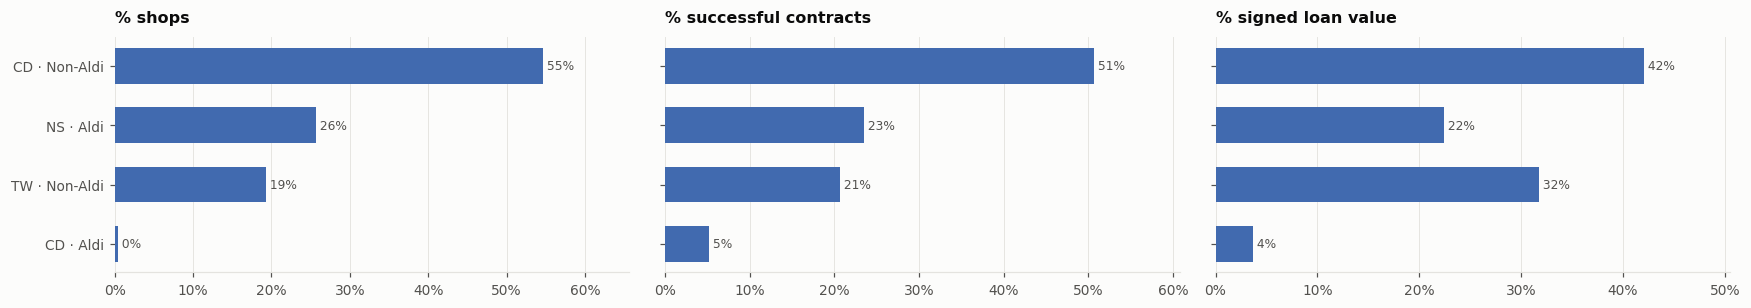

In [34]:
seg = s.groupby('segment').agg(shop=('ok_m', 'size'), shop_co_HD=('active', 'mean'), ho_so=('apps_m', 'sum'), HD=('ok_m', 'sum'),
                               tai_tro_ty=('fund_m', lambda x: x.sum() / 1e9)).reindex(SEG)
seg['% shop'] = seg.shop / seg.shop.sum(); seg['% HĐ'] = seg.HD / seg.HD.sum(); seg['% giá trị vay'] = seg.tai_tro_ty / seg.tai_tro_ty.sum()
display(seg.round(3))
fig, ax = plt.subplots(1, 3, figsize=(16, 2.9), sharey=True)
y = np.arange(len(seg))
for a_, col, ttl, fmt in [(ax[0], '% shop', '% số shop', '{:.0%}'), (ax[1], '% HĐ', '% HĐ thành công', '{:.0%}'), (ax[2], '% giá trị vay', '% giá trị khoản vay đã ký', '{:.0%}')]:
    a_.barh(y, seg[col], color=C1, height=.6); a_.set_yticks(y, seg.index); a_.invert_yaxis(); a_.set_title(ttl)
    a_.xaxis.set_major_formatter(mtick.PercentFormatter(1)); a_.grid(axis='y', visible=False)
    for yi, v in zip(y, seg[col]): a_.text(v, yi, ' ' + fmt.format(v), va='center', fontsize=8, color=TXT2)
    a_.set_xlim(0, seg[col].max() * 1.2)
plt.tight_layout(); plt.show()

### 7.2 Quy mô: cùng phân khúc, các shop chênh nhau bao nhiêu?
Mỗi chấm là 1 shop. Trục ngang là thang log (0, 1, 3, 10, 30… HĐ/tháng). Vạch đen là trung vị; khung là khoảng P25–P75.

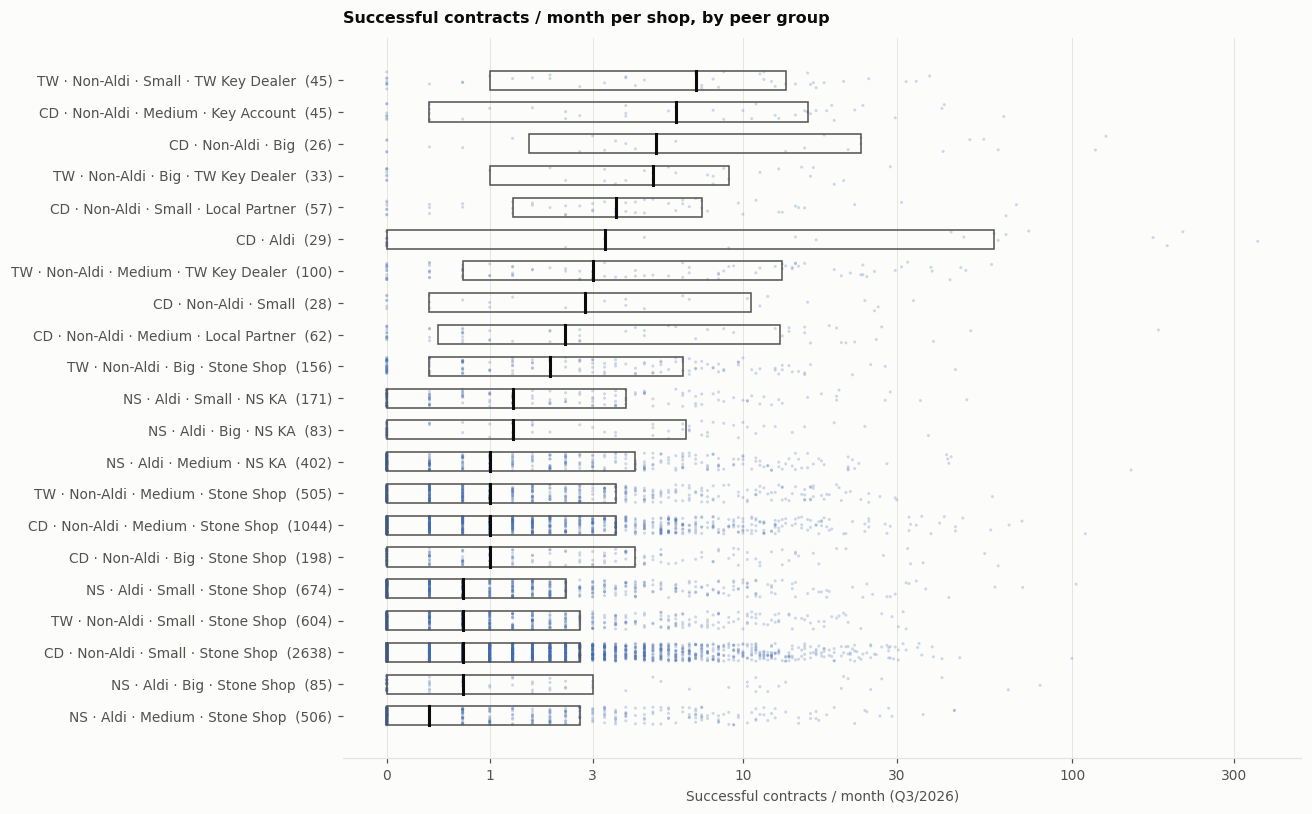

,count,25%,50%,75%,90%,max,P90 / trung vị,% shop 0 HĐ
peer,,,,,,,,
CD · Non-Aldi · Small · Stone Shop,"2,638.00",0.00,0.67,2.67,6.67,99.67,10.00,0.34
CD · Non-Aldi · Medium · Stone Shop,"1,044.00",0.00,1.00,3.67,8.67,109.33,8.67,0.34
NS · Aldi · Small · Stone Shop,674.00,0.00,0.67,2.33,7.23,102.67,10.85,0.40
TW · Non-Aldi · Small · Stone Shop,604.00,0.00,0.67,2.67,7.57,32.00,11.35,0.35
NS · Aldi · Medium · Stone Shop,506.00,0.00,0.33,2.67,7.17,44.67,21.50,0.46
TW · Non-Aldi · Medium · Stone Shop,505.00,0.00,1.00,3.67,9.67,58.00,9.67,0.26
NS · Aldi · Medium · NS KA,402.00,0.00,1.00,4.33,10.00,149.00,10.00,0.36
CD · Non-Aldi · Big · Stone Shop,198.00,0.00,1.00,4.33,10.53,60.33,10.53,0.32
NS · Aldi · Small · NS KA,171.00,0.00,1.33,4.00,10.00,48.67,7.50,0.30


In [35]:
pk = s.groupby('peer').agg(segment=('segment', 'first'), shop=('ok_m', 'size'), HD_TV=('ok_m', 'median')).sort_values(['segment', 'HD_TV'])
order_peer = pk.sort_values('HD_TV').index.tolist()
fig, ax = plt.subplots(figsize=(12, 7.5))
rng = np.random.default_rng(0)
for i, p in enumerate(order_peer):
    v = np.log1p(s.loc[s.peer == p, 'ok_m'].values)
    ax.scatter(v, i + rng.uniform(-.28, .28, len(v)), s=4, color=C1, alpha=.25, edgecolor='none')
    q1, q2, q3 = np.percentile(v, [25, 50, 75])
    ax.add_patch(plt.Rectangle((q1, i - .3), q3 - q1, .6, fill=False, edgecolor=TXT2, lw=1))
    ax.plot([q2, q2], [i - .3, i + .3], color=TXT, lw=2)
ax.set_yticks(range(len(order_peer)), [f'{p}  ({pk.loc[p, "shop"]})' for p in order_peer])
ticks = [0, 1, 3, 10, 30, 100, 300]
ax.set_xticks(np.log1p(ticks), ticks); ax.set_xlabel('HĐ thành công / tháng (Q3/2026)')
ax.grid(axis='y', visible=False); ax.set_title('HĐ thành công / tháng của từng shop, theo phân khúc chi tiết')
plt.tight_layout(); plt.show()
disp = s.groupby('peer').ok_m.describe(percentiles=[.25, .5, .75, .9])[['count', '25%', '50%', '75%', '90%', 'max']]
disp['P90 / trung vị'] = disp['90%'] / disp['50%'].replace(0, np.nan)
disp['% shop 0 HĐ'] = s.groupby('peer').active.apply(lambda x: 1 - x.mean())
display(disp.sort_values('count', ascending=False).round(2))

### 7.3 Giá trị khoản vay đã ký và khoản vay bình quân
Khoản vay bình quân phụ thuộc chủ yếu vào **sản phẩm**: vay xe máy và vay tiền mặt lớn, BNPL rất nhỏ.
Vì vậy shop cùng số HĐ có thể chênh nhiều lần về giá trị khoản vay đã ký.

,HD_thang,TV_tr,P25_tr,P75_tr,tai_tro_ty
product,,,,,
CD,"17,930.33",9.77,6.31,13.90,201.55
TW,"4,266.33",18.10,12.94,27.75,92.04
BNPL,"1,810.00",5.00,2.00,8.00,12.74
CL,"1,215.33",30.00,15.60,51.00,52.43
CC,313.00,NaN,NaN,NaN,NaN
CW,146.67,20.00,10.88,30.00,3.10


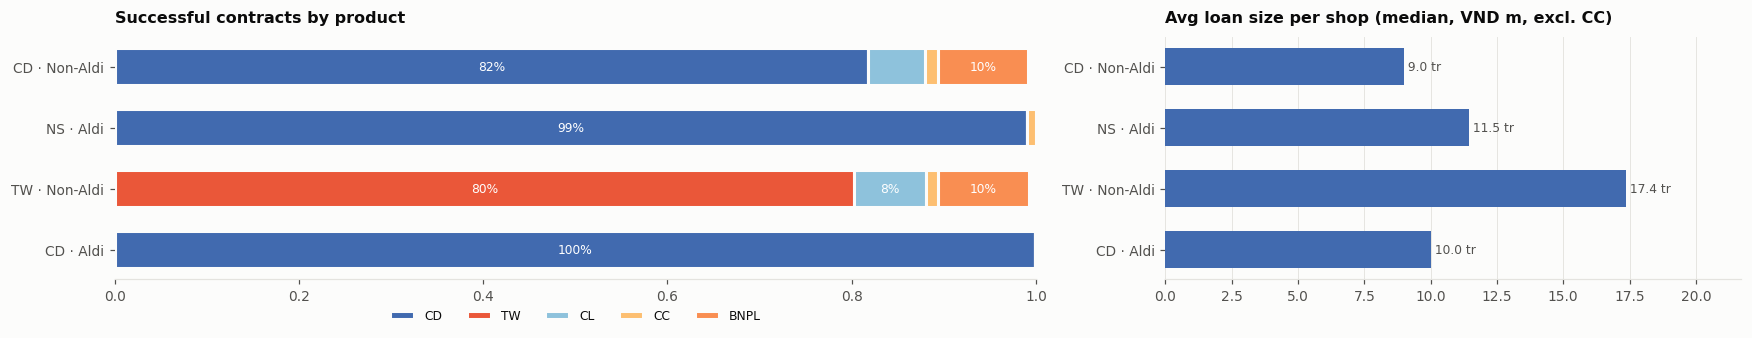

In [36]:
tk = cons.sql(f'''SELECT product, count(*) / 3 HD_thang, median(loan_amount_eff) / 1e6 TV_tr, quantile_cont(loan_amount_eff, .25) / 1e6 P25_tr,
                        quantile_cont(loan_amount_eff, .75) / 1e6 P75_tr, sum(loan_amount_eff) / 3 / 1e9 tai_tro_ty
                 FROM c WHERE ok AND date_apply >= '{Q_FROM}' AND date_apply < '{Q_TO}' AND product IS NOT NULL
                 GROUP BY 1 ORDER BY 2 DESC''').df().set_index('product')
display(tk.round(2))
mx = mix.merge(s[['skp_salesroom', 'segment']], on='skp_salesroom').pivot_table(index='segment', columns='product', values='n', aggfunc='sum').fillna(0)
mx = mx.div(mx.sum(axis=1), axis=0).reindex(SEG)
seg_t = s.groupby('segment').agg(ticket_TV=('ticket', 'median'), tai_tro_shop_TV=('fund_m', 'median')).reindex(SEG) / 1e6
fig, ax = plt.subplots(1, 2, figsize=(16, 3.2), gridspec_kw={'width_ratios': [1.6, 1]})
PRODS = ['CD', 'TW', 'CL', 'CC', 'BNPL']; PC = dict(zip(PRODS, [C1, C2, C3, C4, '#f98e52']))
left = np.zeros(len(mx)); y = np.arange(len(mx))
for p in [p for p in PRODS if p in mx.columns]:
    ax[0].barh(y, mx[p], left=left, color=PC[p], label=p, height=.6, edgecolor=SURF, linewidth=2)
    for yi, l_, v in zip(y, left, mx[p]):
        if v >= .07: ax[0].text(l_ + v / 2, yi, f'{v:.0%}', ha='center', va='center', fontsize=8, color='white')
    left += mx[p].values
ax[0].set_yticks(y, mx.index); ax[0].invert_yaxis(); ax[0].set_xlim(0, 1); ax[0].grid(False)
ax[0].legend(ncol=5, loc='upper center', bbox_to_anchor=(.5, -.08)); ax[0].set_title('Cơ cấu HĐ thành công theo sản phẩm')
ax[1].barh(y, seg_t.ticket_TV, color=C1, height=.6); ax[1].set_yticks(y, seg_t.index); ax[1].invert_yaxis(); ax[1].grid(axis='y', visible=False)
for yi, v in zip(y, seg_t.ticket_TV): ax[1].text(v, yi, f' {v:.1f} tr', va='center', fontsize=8, color=TXT2)
ax[1].set_xlim(0, seg_t.ticket_TV.max() * 1.25); ax[1].set_title('Khoản vay bình quân của shop (trung vị, triệu đ, không tính CC)')
plt.tight_layout(); plt.show()

### 7.4 Phễu bán hàng: khách rơi ở đâu?
Mỗi 100 hồ sơ nộp có ba kết cục: **bị từ chối** (do chính sách tín dụng), **khách huỷ** (trước hoặc sau ký), hoặc **thành HĐ**.

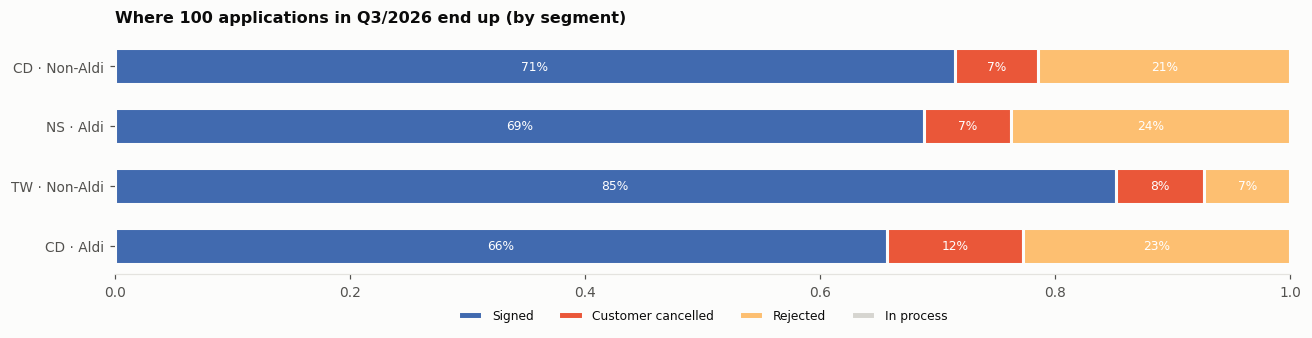

Tỷ lệ theo shop (shop có ≥ 5 hồ sơ trong quý): P25 / trung vị / P75


approval           completion           conversion           cancel_rate          
                   25%  50%  75%        25%  50%  75%        25%  50%  75%         25%  50%  75%
segment                                                                                         
CD · Non-Aldi     0.69 0.80 0.90       0.85 0.93 1.00       0.62 0.74 0.84        0.00 0.05 0.12
NS · Aldi         0.67 0.79 0.89       0.85 0.93 1.00       0.61 0.72 0.83        0.00 0.05 0.12
TW · Non-Aldi     0.90 0.97 1.00       0.88 0.94 1.00       0.80 0.89 0.95        0.00 0.06 0.11
CD · Aldi         0.68 0.74 0.81       0.85 0.90 0.92       0.62 0.66 0.74        0.07 0.08 0.11

In [37]:
fn = s.groupby('segment')[['apps_m', 'rej_m', 'cancel_m', 'ok_m']].sum().reindex(SEG)
fn = fn.assign(khac=fn.apps_m - fn.rej_m - fn.cancel_m - fn.ok_m)
part = pd.DataFrame({'Thành HĐ': fn.ok_m, 'Khách huỷ': fn.cancel_m, 'Bị từ chối': fn.rej_m, 'Đang xử lý': fn.khac.clip(lower=0)}).div(fn.apps_m, axis=0)
fig, ax = plt.subplots(figsize=(12, 3.2)); left = np.zeros(len(part)); y = np.arange(len(part))
for col_, c_ in zip(part.columns, [C1, C2, '#fdbf71', '#d6d5d0']):
    ax.barh(y, part[col_], left=left, color=c_, label=col_, height=.6, edgecolor=SURF, linewidth=2)
    for yi, l_, v in zip(y, left, part[col_]):
        if v >= .05: ax.text(l_ + v / 2, yi, f'{v:.0%}', ha='center', va='center', fontsize=8, color='white')
    left += part[col_].values
ax.set_yticks(y, part.index); ax.invert_yaxis(); ax.set_xlim(0, 1); ax.grid(False)
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(.5, -.1)); ax.set_title('100 hồ sơ nộp Q3/2026 đi về đâu (theo phân khúc)')
plt.tight_layout(); plt.show()
rt = s[rated].groupby('segment')[['approval', 'completion', 'conversion', 'cancel_rate']].describe(percentiles=[.25, .5, .75])
rt = rt.loc[:, (slice(None), ['25%', '50%', '75%'])].reindex(SEG)
print('Tỷ lệ theo shop (shop có ≥ 5 hồ sơ trong quý): P25 / trung vị / P75'); display(rt.round(3))

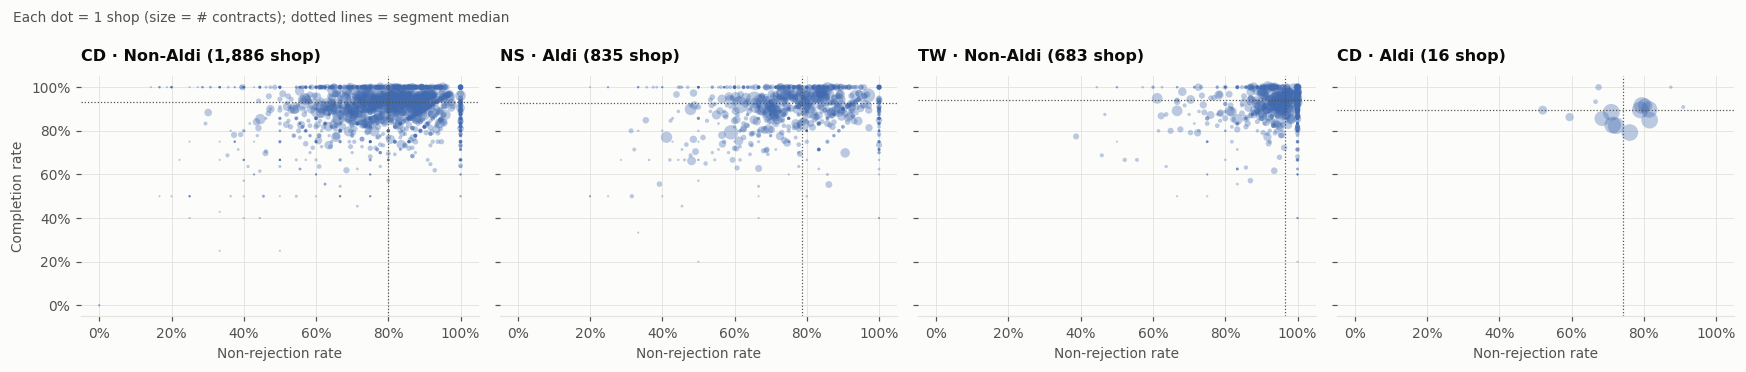

In [38]:
# trong cùng phân khúc: shop rơi khách vì bị từ chối hay vì khách huỷ?
fig, axes = plt.subplots(1, len(SEG), figsize=(4 * len(SEG), 3.4), sharex=True, sharey=True)
for a_, g in zip(np.atleast_1d(axes), SEG):
    t = s[rated & (s.segment == g)]
    a_.scatter(t.approval, t.completion, s=np.clip(t.ok_m, 1, 60) * 2, color=C1, alpha=.35, edgecolor='none')
    a_.axvline(t.approval.median(), color=TXT2, lw=.8, ls=':'); a_.axhline(t.completion.median(), color=TXT2, lw=.8, ls=':')
    a_.set_title(f'{g} ({len(t):,} shop)'); a_.xaxis.set_major_formatter(mtick.PercentFormatter(1)); a_.yaxis.set_major_formatter(mtick.PercentFormatter(1))
np.atleast_1d(axes)[0].set_ylabel('Tỷ lệ hoàn tất'); [a_.set_xlabel('Tỷ lệ không bị từ chối') for a_ in np.atleast_1d(axes)]
fig.suptitle('Mỗi chấm = 1 shop (kích thước = số HĐ); đường chấm = trung vị phân khúc', x=.01, ha='left', fontsize=9, color=TXT2)
plt.tight_layout(); plt.show()

### 7.5 Vận hành: thời gian từ nộp hồ sơ đến ký

,n,TV_phut,P90_phut,pct_qua_1_ngay
product,,,,
CD,53791,11.00,28.00,0.01
TW,12799,18.00,46.00,0.02
BNPL,5430,3.00,13.00,0.01
CL,3646,11.00,50.00,0.02
CC,939,9.00,17.00,0.00
CW,440,17.00,47.10,0.01


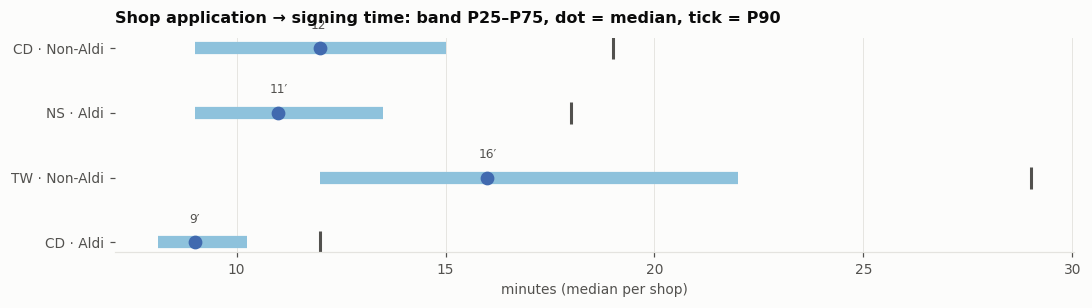

In [39]:
pt = cons.sql(f'''SELECT product, count(*) n, quantile_cont(date_diff('minute', date_apply, date_sign), .5) TV_phut,
                        quantile_cont(date_diff('minute', date_apply, date_sign), .9) P90_phut,
                        avg((date_diff('minute', date_apply, date_sign) > 1440)::INT) pct_qua_1_ngay
                 FROM c WHERE ok AND date_apply >= '{Q_FROM}' AND date_apply < '{Q_TO}' AND product IS NOT NULL GROUP BY 1 ORDER BY 2 DESC''').df().set_index('product')
display(pt.round(2))
sp_ = s[rated].groupby('segment').proc_min.describe(percentiles=[.25, .5, .75, .9]).reindex(SEG)
fig, ax = plt.subplots(figsize=(10, 2.9)); y = np.arange(len(sp_))
ax.hlines(y, sp_['25%'], sp_['75%'], color=SEQ[2], lw=8)
ax.plot(sp_['50%'], y, 'o', color=SEQ[5], ms=8); ax.plot(sp_['90%'], y, '|', color=TXT2, ms=14, mew=2)
for yi, v in zip(y, sp_['50%']): ax.text(v, yi - .3, f'{v:.0f}′', ha='center', fontsize=8, color=TXT2)
ax.set_yticks(y, sp_.index); ax.invert_yaxis(); ax.grid(axis='y', visible=False); ax.set_xlabel('phút (trung vị của từng shop)')
ax.set_title('Thời gian nộp → ký của shop: dải P25–P75, chấm = trung vị, vạch = P90'); plt.tight_layout(); plt.show()

### 7.6 Nhân sự: HĐ trên mỗi SA quy đổi (chỉ shop Non-Aldi)
**SA quy đổi** = mỗi SA được chia đều cho các shop mà SA đó được gán trong quý. Ví dụ SA gán 4 shop thì mỗi shop nhận 0,25 SA.
Dữ liệu chỉ cho biết **phân công**, không cho biết giờ công thực tế, nên đây là năng suất **theo phân công**.

,shop,SA_gan_TV,SA_quy_doi_TV,HD_moi_SA_TV,HD_moi_SA_P75
segment,,,,,
CD · Non-Aldi,4098,24.00,0.62,1.26,5.10
TW · Non-Aldi,1443,24.00,0.62,1.72,6.64


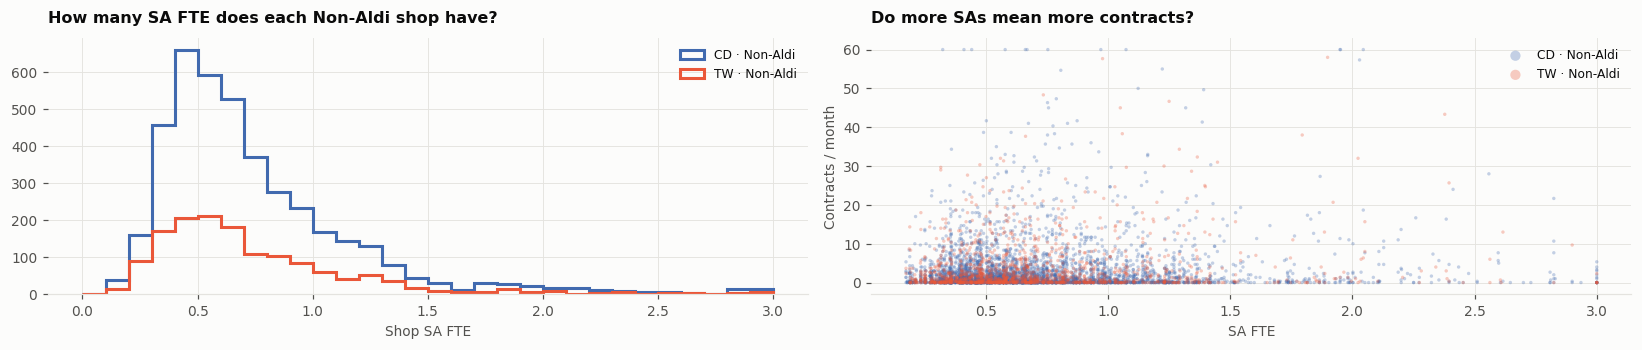

Tương quan Spearman (SA quy đổi, HĐ/tháng) theo phân khúc: {'CD · Non-Aldi': 0.02, 'TW · Non-Aldi': 0.05}


In [40]:
nn = s[(s.model == 'Non-Aldi')]
st_ = nn.groupby('segment').agg(shop=('ok_m', 'size'), SA_gan_TV=('sa_assigned', 'median'), SA_quy_doi_TV=('sa_fte', 'median'),
                                HD_moi_SA_TV=('hd_per_sa', 'median'), HD_moi_SA_P75=('hd_per_sa', lambda x: x.quantile(.75)))
display(st_.round(2))
fig, ax = plt.subplots(1, 2, figsize=(15, 3.3))
for g, c_ in zip([x for x in SEG if 'Non-Aldi' in x], [C1, C2, C3]):
    t = nn[nn.segment == g]
    ax[0].hist(t.sa_fte.clip(upper=3), bins=np.arange(0, 3.1, .1), histtype='step', lw=2, color=c_, label=g)
    ax[1].scatter(t.sa_fte.clip(upper=3), t.ok_m.clip(upper=60), s=5, alpha=.3, color=c_, edgecolor='none', label=g)
ax[0].set_xlabel('SA quy đổi của shop'); ax[0].set_title('Mỗi shop Non-Aldi có bao nhiêu SA quy đổi?'); ax[0].legend()
ax[1].set_xlabel('SA quy đổi'); ax[1].set_ylabel('HĐ / tháng'); ax[1].set_title('Nhiều SA hơn có nhiều HĐ hơn không?'); ax[1].legend(markerscale=3)
plt.tight_layout(); plt.show()
print('Tương quan Spearman (SA quy đổi, HĐ/tháng) theo phân khúc:',
      {g: round(nn[nn.segment == g][['sa_fte', 'ok_m']].corr('spearman').iloc[0, 1], 2) for g in st_.index})

### 7.7 Rủi ro: chất lượng khoản vay phát sinh tại shop
Tính trên HĐ ký 10/2025–05/2026 (đã đủ ≥ 4 tháng để quan sát). Shop có < 10 HĐ đủ tuổi **không được đánh giá**, không coi là "sạch".

,shop_du_du_lieu,HD_du_tuoi,FPD_TV,FPD_P75,FPD_P90,tre_1_4_TV
segment,,,,,,
CD · Non-Aldi,1713,"87,607.00",0.09,0.16,0.23,0.29
NS · Aldi,693,"33,012.00",0.10,0.17,0.25,0.32
TW · Non-Aldi,655,"38,167.00",0.08,0.14,0.21,0.27
CD · Aldi,15,"8,357.00",0.08,0.13,0.18,0.32


FPD theo sản phẩm (gộp toàn mạng lưới): {'BNPL': 0.075, 'CC': 0.095, 'CD': 0.108, 'CL': 0.067, 'CW': 0.064, 'TW': 0.091}


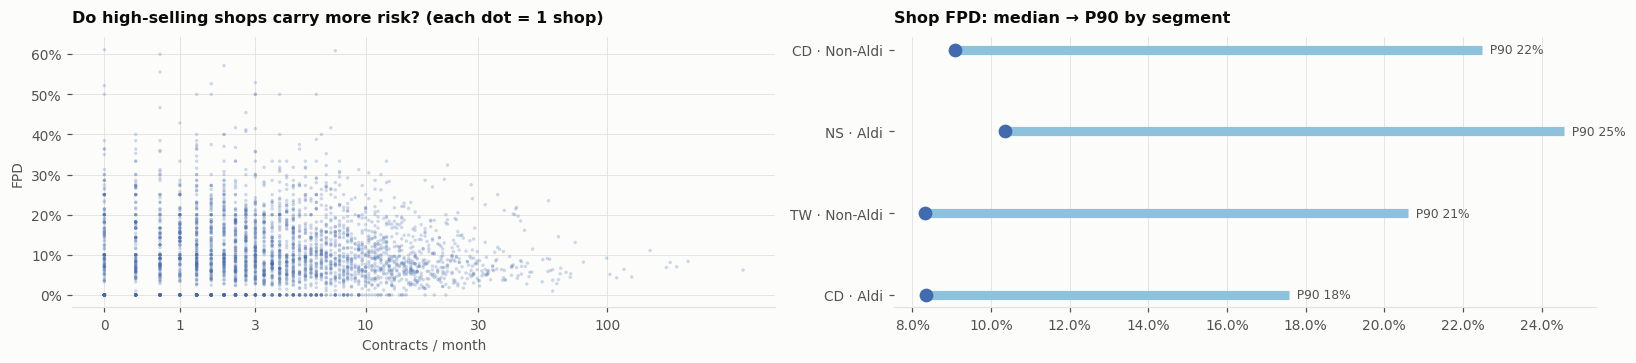

In [41]:
rk = s.groupby('segment').agg(shop_du_du_lieu=('fpd', 'count'), HD_du_tuoi=('n_risk', 'sum'),
                              FPD_TV=('fpd', 'median'), FPD_P75=('fpd', lambda x: x.quantile(.75)), FPD_P90=('fpd', lambda x: x.quantile(.9)),
                              tre_1_4_TV=('dpd14', 'median')).reindex(SEG)
pooled = cons.sql(f'''SELECT s.line || ' · ' || s.model segment, product, avg(flag_dpd_1pd) fpd, avg(flag_any_dpd) dpd14, count(*) n
                     FROM c JOIN shop s USING (skp_salesroom) WHERE ok AND date_sign >= '{R_FROM}' AND date_sign < '{R_TO}'
                     GROUP BY ALL''').df()
display(rk.round(3))
pp = pooled.assign(b=pooled.fpd * pooled.n).groupby('product')[['b', 'n']].sum()
print('FPD theo sản phẩm (gộp toàn mạng lưới):', (pp.b / pp.n).round(3).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(15, 3.4))
t = s[s.fpd.notna()]
ax[0].scatter(np.log1p(t.ok_m), t.fpd, s=5, alpha=.25, color=C1, edgecolor='none')
ax[0].set_xticks(np.log1p([0, 1, 3, 10, 30, 100]), [0, 1, 3, 10, 30, 100]); ax[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[0].set_xlabel('HĐ / tháng'); ax[0].set_ylabel('FPD'); ax[0].set_title('Shop bán nhiều có rủi ro cao hơn không? (mỗi chấm = 1 shop)')
y = np.arange(len(rk))
ax[1].hlines(y, rk.FPD_TV, rk.FPD_P90, color=SEQ[2], lw=6); ax[1].plot(rk.FPD_TV, y, 'o', color=SEQ[5], ms=8)
for yi, a_, b_ in zip(y, rk.FPD_TV, rk.FPD_P90): ax[1].text(b_, yi, f'  P90 {b_:.0%}', va='center', fontsize=8, color=TXT2)
ax[1].set_yticks(y, rk.index); ax[1].invert_yaxis(); ax[1].grid(axis='y', visible=False); ax[1].xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[1].set_title('FPD của shop: trung vị → P90 theo phân khúc'); plt.tight_layout(); plt.show()

### 7.8 Trong cùng phân khúc, shop bán tốt khác shop bán kém ở chỉ số nào?
Chia shop của mỗi phân khúc chi tiết thành 4 nhóm theo HĐ/tháng. So **nhóm 25% cao nhất** với **nhóm 25% thấp nhất (đang có HĐ)** trên từng chỉ số.
Mỗi chỉ số được quy về bội số so với trung vị phân khúc, để các phân khúc so được với nhau.

,Q1 thấp,Q2,Q3,Q4 cao
chi_so,,,,
Hồ sơ / tháng,0.42,0.70,1.38,3.23
Tỷ lệ không bị từ chối,0.97,1.02,1.00,0.99
Tỷ lệ hoàn tất,1.05,1.01,1.00,0.99
Khoản vay BQ,0.93,0.97,1.00,1.09
Thời gian xử lý,1.06,1.00,1.00,0.95
SA quy đổi,0.98,0.99,1.00,1.09
FPD,0.99,1.12,1.02,0.95


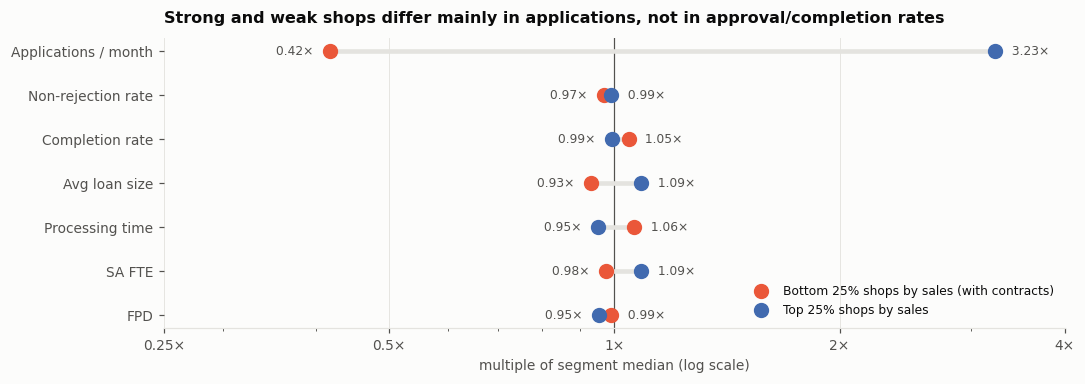

In [42]:
t = s[s.active & rated].copy()
t['q'] = t.groupby('peer').ok_m.transform(lambda x: pd.qcut(x.rank(method='first'), 4, labels=['Q1 thấp', 'Q2', 'Q3', 'Q4 cao']))
KPI = {'apps_m': 'Hồ sơ / tháng', 'approval': 'Tỷ lệ không bị từ chối', 'completion': 'Tỷ lệ hoàn tất', 'ticket': 'Khoản vay BQ',
       'proc_min': 'Thời gian xử lý', 'sa_fte': 'SA quy đổi', 'fpd': 'FPD'}
rows = []
for k_, name in KPI.items():
    med = t.groupby('peer')[k_].transform('median')
    rel = t[k_] / med.replace(0, np.nan)
    g = rel.groupby(t.q, observed=True).median()
    rows.append(dict(chi_so=name, **{q: g.get(q, np.nan) for q in ['Q1 thấp', 'Q2', 'Q3', 'Q4 cao']}))
prof = pd.DataFrame(rows).set_index('chi_so')
display(prof.round(2))
fig, ax = plt.subplots(figsize=(10, 3.6)); y = np.arange(len(prof))
ax.axvline(1, color=TXT2, lw=.8)
ax.hlines(y, prof['Q1 thấp'], prof['Q4 cao'], color=GRID, lw=3)
ax.plot(prof['Q1 thấp'], y, 'o', color=C2, ms=9, label='25% shop bán thấp nhất (có HĐ)')
ax.plot(prof['Q4 cao'], y, 'o', color=C1, ms=9, label='25% shop bán cao nhất')
for yi, a_, b_ in zip(y, prof['Q1 thấp'], prof['Q4 cao']):
    lo_, hi_ = (a_, b_) if a_ <= b_ else (b_, a_)
    ax.text(lo_ / 1.04, yi, f'{lo_:.2f}× ', ha='right', va='center', fontsize=8, color=TXT2)
    ax.text(hi_ * 1.04, yi, f' {hi_:.2f}×', ha='left', va='center', fontsize=8, color=TXT2)
ax.set_yticks(y, prof.index); ax.invert_yaxis(); ax.set_xscale('log'); ax.set_xticks([.25, .5, 1, 2, 4], ['0,25×', '0,5×', '1×', '2×', '4×'])
ax.grid(axis='y', visible=False); ax.legend(loc='lower right'); ax.set_xlabel('bội số so với trung vị phân khúc (thang log)')
ax.set_title('Shop bán tốt khác shop bán kém chủ yếu ở số hồ sơ, không ở tỷ lệ không bị từ chối/hoàn tất'); plt.tight_layout(); plt.show()

### 7.9 Bảng chỉ số theo phân khúc chi tiết (trung vị của shop)

In [43]:
tb = s.groupby('peer').agg(phan_khuc=('segment', 'first'), shop=('ok_m', 'size'), pct_0_HD=('active', lambda x: 1 - x.mean()),
        HD_thang=('ok_m', 'median'), tai_tro_tr=('fund_m', lambda x: x.median() / 1e6), khoan_vay_tr=('ticket', lambda x: x.median() / 1e6),
        ho_so=('apps_m', 'median'))
tb2 = s[rated].groupby('peer').agg(duyet=('approval', 'median'), hoan_tat=('completion', 'median'), chuyen_doi=('conversion', 'median'),
        xu_ly_phut=('proc_min', 'median'), HD_moi_SA=('hd_per_sa', 'median'))
tb3 = s.groupby('peer').agg(FPD=('fpd', 'median'), tre_1_4=('dpd14', 'median'))
tbl = tb.join(tb2).join(tb3).sort_values(['phan_khuc', 'shop'], ascending=[True, False])
display(tbl.round(2))
tbl.to_csv(OUT / 'hien_trang_theo_phan_khuc.csv', encoding='utf-8-sig')
s.to_csv(OUT / 'hien_trang_theo_shop.csv', index=False, encoding='utf-8-sig')

,phan_khuc,shop,pct_0_HD,HD_thang,tai_tro_tr,khoan_vay_tr,ho_so,duyet,hoan_tat,chuyen_doi,xu_ly_phut,HD_moi_SA,FPD,tre_1_4
peer,,,,,,,,,,,,,,
CD · Aldi,CD · Aldi,29,0.45,3.33,29.41,10.02,4.00,0.74,0.90,0.66,9.00,NaN,0.08,0.32
CD · Non-Aldi · Small · Stone Shop,CD · Non-Aldi,2638,0.34,0.67,5.60,8.65,1.00,0.80,0.93,0.75,12.00,5.27,0.10,0.29
CD · Non-Aldi · Medium · Stone Shop,CD · Non-Aldi,1044,0.34,1.00,8.00,9.23,1.33,0.82,0.94,0.76,11.00,5.84,0.10,0.30
CD · Non-Aldi · Big · Stone Shop,CD · Non-Aldi,198,0.32,1.00,9.77,9.43,1.67,0.82,0.93,0.74,11.50,6.88,0.09,0.28
CD · Non-Aldi · Medium · Local Partner,CD · Non-Aldi,62,0.19,2.33,26.48,11.50,3.17,0.78,0.96,0.75,10.50,8.52,0.05,0.22
CD · Non-Aldi · Small · Local Partner,CD · Non-Aldi,57,0.12,3.67,44.53,12.12,5.67,0.76,0.92,0.71,11.00,6.27,0.06,0.21
CD · Non-Aldi · Medium · Key Account,CD · Non-Aldi,45,0.16,6.00,114.18,14.52,11.33,0.71,0.91,0.64,12.00,15.92,0.05,0.21
CD · Non-Aldi · Small,CD · Non-Aldi,28,0.21,2.83,31.43,12.90,4.17,0.66,0.91,0.65,12.00,8.27,0.04,0.22
CD · Non-Aldi · Big,CD · Non-Aldi,26,0.15,5.17,72.32,11.91,6.83,0.81,0.90,0.74,11.50,22.25,0.05,0.20


In [44]:
# nhận xét tự sinh từ số liệu
g = s.groupby('segment')
n0 = 1 - s.active.mean()
top = s.sort_values('ok_m', ascending=False); top20 = top.ok_m.head(int(len(top) * .2)).sum() / top.ok_m.sum()
cdn = s[(s.segment == 'CD · Non-Aldi') & rated]
lines = [
 f"1. Quy mô rất lệch: {n0:.0%} shop trưởng thành không có HĐ nào trong Q3; 20% shop tạo {top20:.0%} HĐ. Trong cùng phân khúc chi tiết, shop P90 bán gấp "
 f"{disp['P90 / trung vị'].replace([np.inf], np.nan).median():.1f} lần shop trung vị.",
 f"2. Phễu: tỷ lệ không bị từ chối trung vị {s[rated].approval.median():.0%}, tỷ lệ hoàn tất {s[rated].completion.median():.0%}; "
 f"phân khúc Aldi bị từ chối nhiều hơn (không bị từ chối TV {s[rated & (s.model=='Aldi')].approval.median():.0%} so với Non-Aldi {s[rated & (s.model=='Non-Aldi')].approval.median():.0%}).",
 f"3. Khoản vay bình quân: TW {s[s.segment=='TW · Non-Aldi'].ticket.median()/1e6:.0f} tr, CD {s[s.segment=='CD · Non-Aldi'].ticket.median()/1e6:.0f} tr, "
 f"NS · Aldi {s[s.segment=='NS · Aldi'].ticket.median()/1e6:.0f} tr → so shop phải theo cả HĐ và giá trị khoản vay đã ký.",
 f"4. Thời gian nộp → ký trung vị {s[rated].proc_min.median():.0f} phút; phần lớn HĐ ký ngay trong phiên tại quầy.",
 f"5. Nhân sự (Non-Aldi): trung vị {s[s.model=='Non-Aldi'].sa_assigned.median():.0f} SA được gán nhưng chỉ {s[s.model=='Non-Aldi'].sa_fte.median():.2f} SA quy đổi/shop; "
 f"năng suất trung vị {s.hd_per_sa.median():.1f} HĐ/SA quy đổi/tháng.",
 f"6. Rủi ro: FPD trung vị {s.fpd.median():.1%}, P90 {s.fpd.quantile(.9):.1%}; tương quan HĐ/tháng ~ FPD (Spearman) = {s[['ok_m','fpd']].corr('spearman').iloc[0,1]:.2f}.",
 f"7. Trong cùng phân khúc, 25% shop bán cao nhất có số hồ sơ gấp {prof.loc['Hồ sơ / tháng','Q4 cao']/prof.loc['Hồ sơ / tháng','Q1 thấp']:.1f} lần nhóm thấp nhất, "
 f"trong khi tỷ lệ không bị từ chối chỉ chênh {prof.loc['Tỷ lệ không bị từ chối','Q4 cao']/prof.loc['Tỷ lệ không bị từ chối','Q1 thấp']:.2f} lần và tỷ lệ hoàn tất {prof.loc['Tỷ lệ hoàn tất','Q4 cao']/prof.loc['Tỷ lệ hoàn tất','Q1 thấp']:.2f} lần.",
]
print('\n'.join(lines))

1. Quy mô rất lệch: 34% shop trưởng thành không có HĐ nào trong Q3; 20% shop tạo 79% HĐ. Trong cùng phân khúc chi tiết, shop P90 bán gấp 9.0 lần shop trung vị.
2. Phễu: tỷ lệ không bị từ chối trung vị 83%, tỷ lệ hoàn tất 93%; phân khúc Aldi bị từ chối nhiều hơn (không bị từ chối TV 79% so với Non-Aldi 86%).
3. Khoản vay bình quân: TW 17 tr, CD 9 tr, NS · Aldi 11 tr → so shop phải theo cả HĐ và giá trị khoản vay đã ký.
4. Thời gian nộp → ký trung vị 12 phút; phần lớn HĐ ký ngay trong phiên tại quầy.
5. Nhân sự (Non-Aldi): trung vị 24 SA được gán nhưng chỉ 0.62 SA quy đổi/shop; năng suất trung vị 1.4 HĐ/SA quy đổi/tháng.
6. Rủi ro: FPD trung vị 9.1%, P90 22.2%; tương quan HĐ/tháng ~ FPD (Spearman) = -0.08.
7. Trong cùng phân khúc, 25% shop bán cao nhất có số hồ sơ gấp 7.8 lần nhóm thấp nhất, trong khi tỷ lệ không bị từ chối chỉ chênh 1.02 lần và tỷ lệ hoàn tất 0.95 lần.


## 8. Lead → hợp đồng: đầu vào hiện tại
Leads chỉ có từ 31/12/2025. Mọi con số **nhân `sample_weight`**.

- **Kết quả xử lý (`result`)**: map sang `cl_lead_fin_reason.CODE_FINISH` (7 = DEAL). Từ điển này của luồng Cash Loan (LDS) → chỉ phản ánh đúng cho CL/CC.
- **Chuyển đổi thật**: nối lead → hợp đồng theo quy tắc của đề (cùng `skp_client` + cùng sản phẩm + giao lead trước mốc thời gian, ghép 1-1 trong 30 ngày – `data_clean/lead_contract_link.csv`). Có **2 hướng**:

| Cột | Điều kiện | Ý nghĩa | Tính trên |
|---|---|---|---|
| `converted_apply` | `date_assigned ≤ date_apply` | Lead **tạo ra hồ sơ mới** | Lead `ORIGINATION` |
| `converted_sign` | `date_assigned ≤ date_sign` | Lead **giúp ra hợp đồng ký** | Mọi lead |

> `lead_flow = 'FOLLOW_UP'` (WDE, GMA, GMA_BIG_TICKET, CRM): lead sinh **sau** khi khách đã nộp hồ sơ, để chăm sóc đến lúc ký → không tính `converted_apply` cho nhóm này.
> Tỷ lệ chuyển đổi chỉ tính lead giao **trước 01/09/2026** (lead sau đó chưa đủ 30 ngày quan sát).

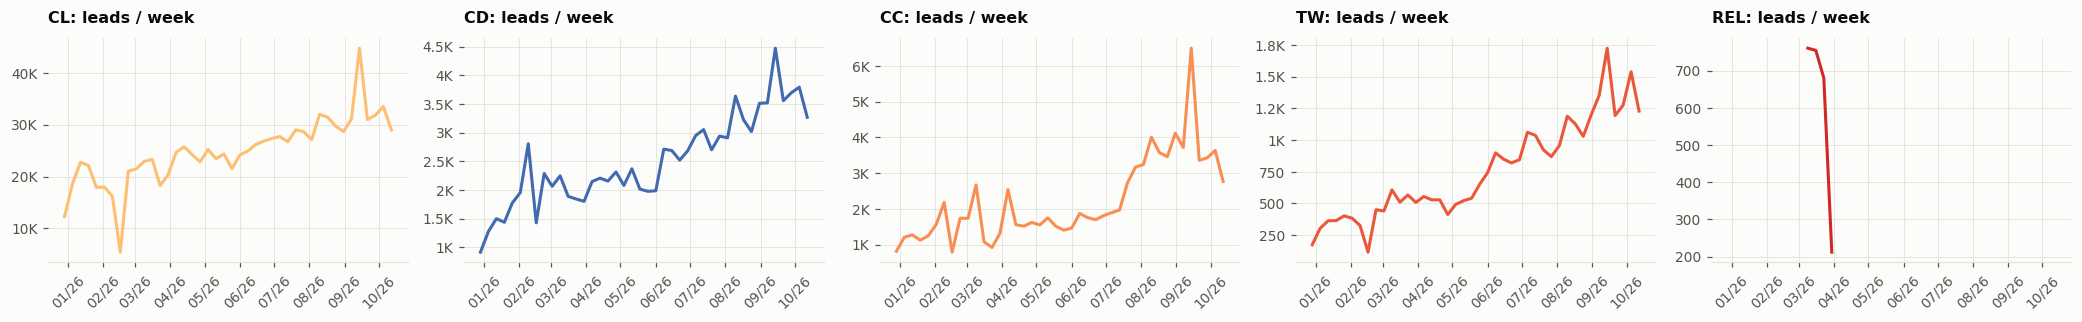

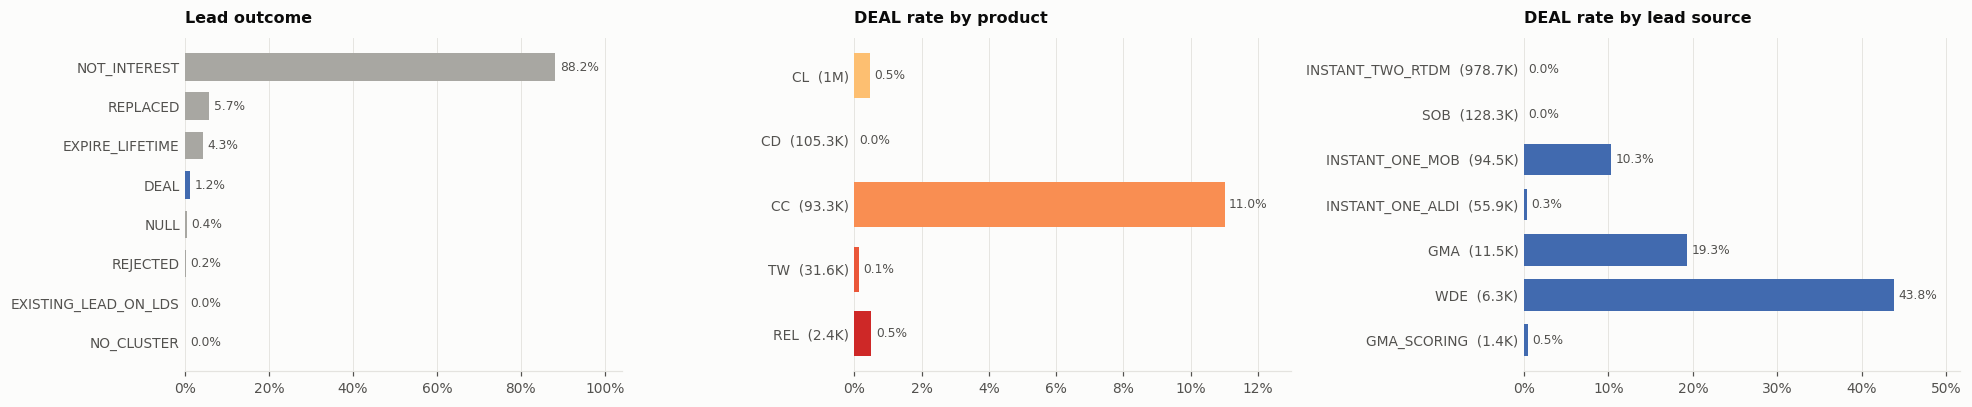

In [45]:
wk = q('''SELECT week_assigned, code_product_type p, sum(sample_weight) n FROM lds GROUP BY ALL''')
prods = q('SELECT code_product_type p FROM lds GROUP BY 1 ORDER BY sum(sample_weight) DESC').p.tolist()
fig, axes = plt.subplots(1, len(prods), figsize=(19, 3), sharex=True)
for ax, p in zip(axes, prods):
    d = wk[wk.p == p].sort_values('week_assigned')
    ax.plot(pd.to_datetime(d.week_assigned), d.n, color=PCOL.get(p, GREY))
    ax.set_title(f'{p}: leads / tuần'); ax.yaxis.set_major_formatter(mtick.FuncFormatter(human))
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%m/%y')); ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

kq = q('''SELECT ket_qua, 100 * sum(sample_weight) / sum(sum(sample_weight)) OVER () p FROM lds GROUP BY 1 ORDER BY 2 DESC''')
dp = q('''SELECT code_product_type p, 100 * coalesce(sum(sample_weight) FILTER (WHERE result = 7), 0) / sum(sample_weight) deal, sum(sample_weight) n
          FROM lds GROUP BY 1 ORDER BY n DESC''')
ds = q('''SELECT id_lead_source s, 100 * coalesce(sum(sample_weight) FILTER (WHERE result = 7), 0) / sum(sample_weight) deal, sum(sample_weight) n
          FROM lds GROUP BY 1 HAVING sum(sample_weight) >= 1000 ORDER BY n DESC''')
fig, ax = plt.subplots(1, 3, figsize=(18, 3.8))
barh(ax[0], kq.ket_qua, kq.p, 'Kết quả xử lý lead', pct=True, color=[BLUE if v == 'DEAL' else GREY for v in kq.ket_qua])
barh(ax[1], dp.p + '  (' + dp.n.map(human) + ')', dp.deal, 'Tỷ lệ DEAL theo sản phẩm', pct=True, color=[PCOL.get(x, GREY) for x in dp.p])
barh(ax[2], ds.s + '  (' + ds.n.map(human) + ')', ds.deal, 'Tỷ lệ DEAL theo nguồn lead', pct=True)
plt.tight_layout(); plt.show()

,lead_flow,p,n,c_apply,c_sign
0,ORIGINATION,CL,"811,681.34",0.32,0.30
1,ORIGINATION,CD,"80,076.00",50.68,49.81
2,ORIGINATION,CC,"64,938.00",14.68,13.01
3,ORIGINATION,TW,"17,154.00",39.23,35.04
4,ORIGINATION,REL,"2,406.00",2.29,1.66
5,FOLLOW_UP,CL,"6,387.00",10.07,63.38
6,FOLLOW_UP,TW,"5,093.00",4.69,4.14
7,FOLLOW_UP,CC,"1,466.00",2.93,31.17


,s,lead_flow,n,c_apply,c_sign
0,INSTANT_TWO_RTDM,ORIGINATION,"773,131.34",0.19,0.12
1,SOB,ORIGINATION,"95,836.00",49.30,47.82
2,INSTANT_ONE_MOB,ORIGINATION,"67,343.00",14.73,14.03
3,INSTANT_ONE_ALDI,ORIGINATION,"38,551.00",2.07,1.39
4,GMA,FOLLOW_UP,"7,555.00",8.71,25.67
5,WDE,FOLLOW_UP,"5,166.00",4.32,50.12
6,GMA_SCORING,ORIGINATION,"1,394.00",5.09,4.88


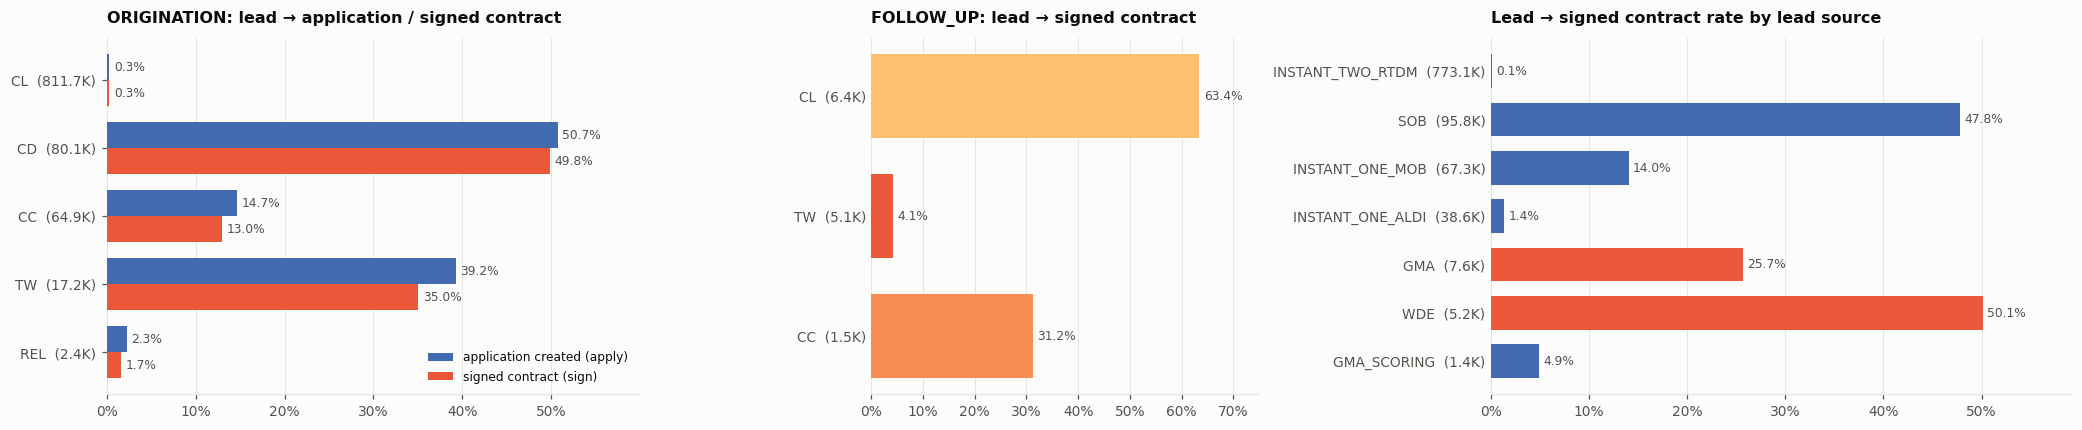

In [46]:
# chuyển đổi lead -> hợp đồng theo 2 hướng (có trọng số, lead giao trước 09/2026)
MAT = "date_assigned < DATE '2026-09-01'"
cv = q(f'''SELECT lead_flow, code_product_type p, sum(sample_weight) n,
  100 * coalesce(sum(sample_weight) FILTER (WHERE converted_apply), 0) / sum(sample_weight) c_apply,
  100 * coalesce(sum(sample_weight) FILTER (WHERE converted_sign), 0) / sum(sample_weight) c_sign
FROM lds WHERE {MAT} GROUP BY ALL ORDER BY lead_flow DESC, n DESC''')
cs = q(f'''SELECT id_lead_source s, lead_flow, sum(sample_weight) n,
  100 * coalesce(sum(sample_weight) FILTER (WHERE converted_apply), 0) / sum(sample_weight) c_apply,
  100 * coalesce(sum(sample_weight) FILTER (WHERE converted_sign), 0) / sum(sample_weight) c_sign
FROM lds WHERE {MAT} GROUP BY ALL HAVING sum(sample_weight) >= 500 ORDER BY n DESC''')
display(cv, cs)

fig, ax = plt.subplots(1, 3, figsize=(19, 4), gridspec_kw={'width_ratios': [1.1, .8, 1.2]})
o = cv[cv.lead_flow == 'ORIGINATION'].reset_index(drop=True)
y = np.arange(len(o)); h = .38
ax[0].barh(y - h / 2, o.c_apply, h, color=BLUE, label='tạo hồ sơ (apply)')
ax[0].barh(y + h / 2, o.c_sign, h, color=ORANGE, label='ra HĐ ký (sign)')
for yi, a, b in zip(y, o.c_apply, o.c_sign):
    ax[0].annotate(f'{a:.1f}%', (a, yi - h / 2), xytext=(3, 0), textcoords='offset points', va='center', fontsize=8, color=INK2)
    ax[0].annotate(f'{b:.1f}%', (b, yi + h / 2), xytext=(3, 0), textcoords='offset points', va='center', fontsize=8, color=INK2)
ax[0].set_yticks(y, o.p + '  (' + o.n.map(human) + ')'); ax[0].invert_yaxis(); ax[0].margins(x=.18)
ax[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:.0f}%')); ax[0].grid(axis='y', visible=False)
ax[0].legend(loc='lower right'); ax[0].set_title('ORIGINATION: lead → hồ sơ / HĐ ký')
f = cv[cv.lead_flow == 'FOLLOW_UP']
barh(ax[1], f.p + '  (' + f.n.map(human) + ')', f.c_sign, 'FOLLOW_UP: lead → HĐ ký', pct=True, color=[PCOL.get(x, GREY) for x in f.p])
barh(ax[2], cs.s + '  (' + cs.n.map(human) + ')', cs.c_sign, 'Tỷ lệ ra HĐ ký theo nguồn lead', pct=True,
     color=[ORANGE if fl == 'FOLLOW_UP' else BLUE for fl in cs.lead_flow])
plt.tight_layout(); plt.show()

### 8.1 Lead theo phân khúc lớn
**Bỏ lead `INSTANT_TWO_RTDM`** khi đo nhu cầu: đây là lead do hệ thống tự sinh (down-sample, trọng số khoảng 19,7), không phản ánh nhu cầu tại shop.
Lead còn lại chia 3 loại, vì ý nghĩa khác nhau:
- **Instant** (`INSTANT_ONE_*`): sinh ngay trong phiên bán tại quầy, nên là **hệ quả** của bán hàng, không phải nhu cầu độc lập.
- **Chiến dịch** (`SOB`, `GMA_SCORING`): gần với nhu cầu tạo thêm từ bên ngoài.
- **Follow-up**: chăm sóc khách đã nộp hồ sơ.

Lead / shop / tháng = lead (có trọng số) giao trong Q3/2026 ÷ số shop đang mở cuối 09/2026. Lead → HĐ ký tính trên lead giao trước 09/2026.

% lead (có trọng số) tại shop là RTDM, đã bỏ: {'CD · Non-Aldi': 0.784, 'NS · Aldi': 0.0, 'TW · Non-Aldi': 0.863, 'CD · Aldi': 0.005}


Lead / shop / tháng (Q3/2026)                                                  Lead → HĐ ký (%)                                        
loai              Instant (trong phiên bán) Chiến dịch (SOB, GMA_SCORING) Follow-up Instant (trong phiên bán) Chiến dịch (SOB, GMA_SCORING) Follow-up
seg                                                                                                                                                  
CD · Non-Aldi                          1.84                          2.00      0.17                     13.29                         50.24     57.50
NS · Aldi                              1.79                          0.57      0.00                      1.71                         47.22       NaN
TW · Non-Aldi                          1.37                          1.55      0.68                     16.55                         35.04     21.61
CD · Aldi                             45.70                          0.00      0.00                      0.52                           NaN       NaN

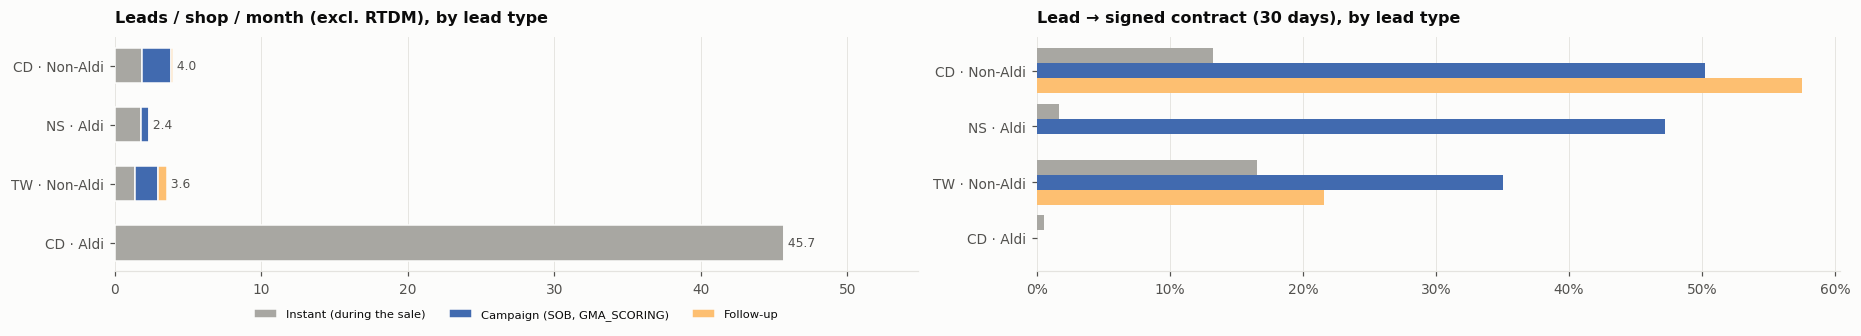

In [47]:
LT = '''CASE WHEN id_lead_source LIKE 'INSTANT_ONE%' THEN 'Instant (trong phiên bán)' WHEN lead_flow = 'FOLLOW_UP' THEN 'Follow-up'
             ELSE 'Chiến dịch (SOB, GMA_SCORING)' END'''
LTS = ['Instant (trong phiên bán)', 'Chiến dịch (SOB, GMA_SCORING)', 'Follow-up']
lseg = q(f'''SELECT s.seg, {LT} loai,
                    sum(l.w) FILTER (WHERE l.m >= DATE '2026-07-01' AND l.m <= DATE '2026-09-01') / 3 lead_thang,
                    100 * sum(l.w) FILTER (WHERE converted_sign AND {MAT}) / nullif(sum(l.w) FILTER (WHERE {MAT}), 0) c_sign
             FROM lds l JOIN shop s USING (skp_salesroom)
             WHERE s.seg IN {tuple(SEG)} AND id_lead_source <> 'INSTANT_TWO_RTDM' GROUP BY ALL''')
rt_ = q(f'''SELECT s.seg, sum(l.w) FILTER (WHERE id_lead_source = 'INSTANT_TWO_RTDM') / sum(l.w) rtdm FROM lds l JOIN shop s USING (skp_salesroom)
            WHERE s.seg IN {tuple(SEG)} GROUP BY 1''').set_index('seg').rtdm
shop_mo = q("SELECT seg, count(*) n FROM shop WHERE m_close IS NULL OR m_close > DATE '2026-09-01' GROUP BY 1").set_index('seg').n
lps = lseg.pivot(index='seg', columns='loai', values='lead_thang').reindex(index=SEG, columns=LTS).fillna(0).div(shop_mo.reindex(SEG), axis=0)
lcv = lseg.pivot(index='seg', columns='loai', values='c_sign').reindex(index=SEG, columns=LTS)
print('% lead (có trọng số) tại shop là RTDM, đã bỏ:', rt_.reindex(SEG).fillna(0).round(3).to_dict())
display(pd.concat({'Lead / shop / tháng (Q3/2026)': lps, 'Lead → HĐ ký (%)': lcv}, axis=1).round(2))
fig, ax = plt.subplots(1, 2, figsize=(17, 3.2))
LCOL_ = dict(zip(LTS, [GREY, BLUE, YELLOW])); left = np.zeros(len(lps)); y = np.arange(len(lps))
for c_ in LTS:
    ax[0].barh(y, lps[c_], left=left, color=LCOL_[c_], label=c_, height=.6, edgecolor=SURF); left += lps[c_].values
for yi, v_ in zip(y, left): ax[0].text(v_, yi, f' {v_:.1f}', va='center', fontsize=8, color=INK2)
ax[0].set_yticks(y, lps.index); ax[0].invert_yaxis(); ax[0].grid(axis='y', visible=False); ax[0].legend(ncol=3, loc='upper center', bbox_to_anchor=(.5, -.12), fontsize=7.5)
ax[0].set_xlim(0, left.max() * 1.2); ax[0].set_title('Lead / shop / tháng (bỏ RTDM), theo loại lead')
h_ = .27
for k_, c_ in enumerate(LTS):
    ax[1].barh(y + (k_ - 1) * h_, lcv[c_].fillna(0), h_, color=LCOL_[c_], label=c_)
ax[1].set_yticks(y, lcv.index); ax[1].invert_yaxis(); ax[1].grid(axis='y', visible=False)
ax[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:.0f}%')); ax[1].set_title('Lead → HĐ ký (30 ngày), theo loại lead')
plt.tight_layout(); plt.show()

### 8.2 Sản phẩm của lead và sản phẩm của hợp đồng có khớp nhau không?
Lead của shop vật lý, **bỏ RTDM**, có trọng số. Hai câu hỏi:
1. **Cơ cấu:** lead đang dồn vào sản phẩm nào, so với cơ cấu HĐ ký thực tế tại shop (01–09/2026)?
2. **Khách có lead ký gì?** Với mỗi lead (giao trước 09/2026), lấy **HĐ ký đầu tiên của cùng khách trong 30 ngày sau khi giao lead, ở bất kỳ kênh nào**, rồi so sản phẩm.

> Luật nối của đề yêu cầu **cùng sản phẩm**, nên HĐ khác sản phẩm **không** được tính là kết quả của lead. Bảng dưới cho thấy luật này bỏ sót bao nhiêu. Đây là mối liên hệ (khách có lead rồi ký), chưa chứng minh HĐ do lead tạo ra.

,% lead,% HĐ ký tại shop
p,,
CD,35.6%,69.6%
CC,31.3%,3.5%
CL,21.8%,4.4%
TW,10.4%,15.5%
REL,0.9%,0.0%
BNPL,0.0%,6.5%
CW,0.0%,0.4%


,lead (có trọng số),% có HĐ trong 30 ngày,% cùng sản phẩm (trong số có HĐ),tỷ lệ theo luật của đề (cùng sản phẩm),sản phẩm khác hay gặp nhất
lp,,,,,
CD,"78,282",46.5%,92%,42.7%,–
CC,"66,404",16.7%,77%,13.0%,BNPL 15%
CL,"44,937",11.7%,26%,3.0%,"CC 44%, BNPL 22%"
TW,"20,530",36.0%,87%,31.3%,CL 8%
REL,"2,406",2.7%,0%,0.0%,"CC 61%, CD 26%"


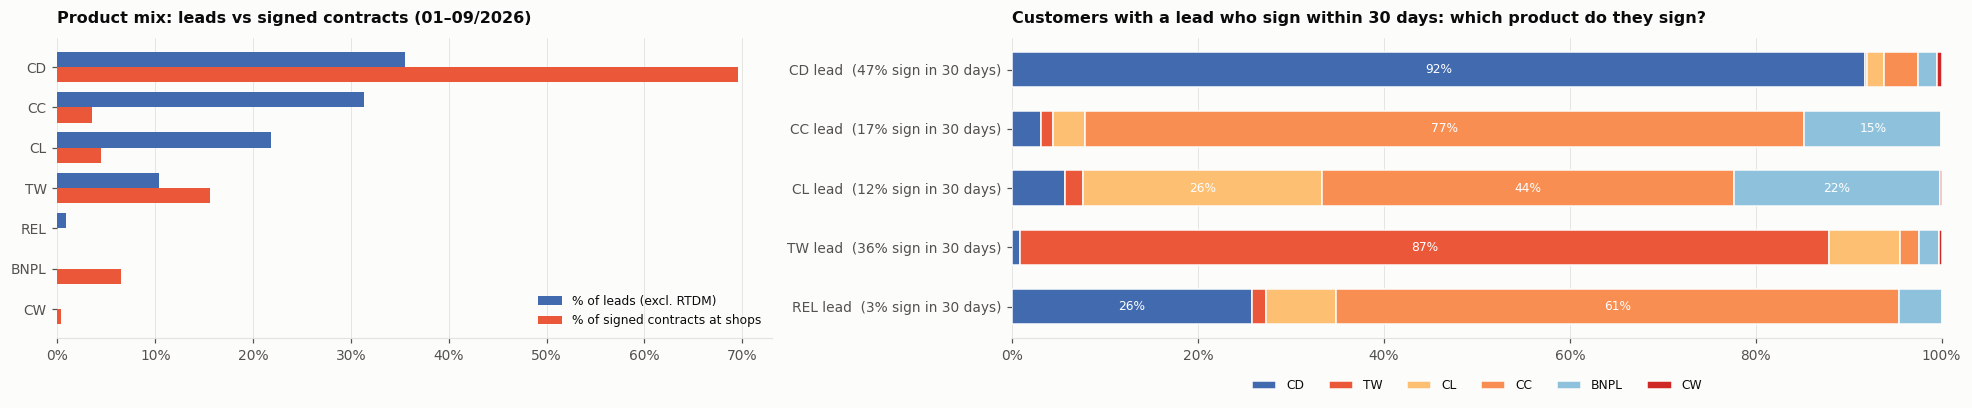

Lead lệch sản phẩm nhiều nhất: CL – chỉ 26% khách ký đúng sản phẩm của lead (CC 44%, BNPL 22%). Lead chuyển đổi cao nhất: CD (47%) nhưng chỉ chiếm 36% lead. Theo luật của đề, 17% HĐ ký sau lead không được tính cho lead vì khác sản phẩm.


In [48]:
x82 = q(f'''WITH ld AS (SELECT row_number() OVER () id, skp_client, p lp, date_assigned t, w FROM lds
                        WHERE id_lead_source <> 'INSTANT_TWO_RTDM' AND date_assigned < DATE '2026-09-01' AND skp_client > 0),
              k AS (SELECT skp_client, product, date_apply FROM {rd('contract')}
                    WHERE is_signed AND name_status <> 'Cancelled' AND skp_client > 0 AND product IS NOT NULL),
              m AS (SELECT ld.id, arg_min(k.product, k.date_apply) cp FROM ld JOIN k ON k.skp_client = ld.skp_client
                    AND k.date_apply >= ld.t AND k.date_apply <= ld.t + INTERVAL 30 DAY GROUP BY 1)
         SELECT ld.lp, coalesce(m.cp, '—') cp, sum(ld.w) w FROM ld LEFT JOIN m USING (id) GROUP BY ALL''')
mixl = q('''SELECT p, sum(w) w FROM lds WHERE id_lead_source <> 'INSTANT_TWO_RTDM' AND date_assigned < DATE '2026-10-01' GROUP BY 1''').set_index('p').w
mixc = q('''SELECT coalesce(product, 'UNKNOWN') p, count(*) n FROM ctr WHERE is_signed AND name_status <> 'Cancelled'
            AND date_apply >= DATE '2026-01-01' AND date_apply < DATE '2026-10-01' GROUP BY 1''').set_index('p').n
mix82 = pd.DataFrame({'% lead': mixl / mixl.sum(), '% HĐ ký tại shop': mixc / mixc.sum()}).fillna(0).sort_values('% lead', ascending=False)
pv82 = x82.pivot_table(index='lp', columns='cp', values='w', aggfunc='sum').fillna(0)
has = pv82.drop(columns='—', errors='ignore')
tb82 = pd.DataFrame({'lead (có trọng số)': pv82.sum(axis=1), '% có HĐ trong 30 ngày': has.sum(axis=1) / pv82.sum(axis=1)})
tb82['% cùng sản phẩm (trong số có HĐ)'] = pd.Series({p: has.loc[p, p] if p in has.columns else 0.0 for p in has.index}) / has.sum(axis=1)
tb82['tỷ lệ theo luật của đề (cùng sản phẩm)'] = tb82['% có HĐ trong 30 ngày'] * tb82['% cùng sản phẩm (trong số có HĐ)']
other = has.div(has.sum(axis=1), axis=0)
tb82['sản phẩm khác hay gặp nhất'] = [', '.join(f'{c} {v:.0%}' for c, v in other.loc[p].drop(p, errors='ignore').nlargest(2).items() if v >= .05) or '–'
                                     for p in other.index]
tb82 = tb82.sort_values('lead (có trọng số)', ascending=False)
display(mix82.style.format('{:.1%}'))
display(tb82.style.format({'lead (có trọng số)': '{:,.0f}', '% có HĐ trong 30 ngày': '{:.1%}', '% cùng sản phẩm (trong số có HĐ)': '{:.0%}',
                           'tỷ lệ theo luật của đề (cùng sản phẩm)': '{:.1%}'}))
PC82 = {**PCOL, 'CW': RED, 'UNKNOWN': GREY}
fig, ax = plt.subplots(1, 2, figsize=(18, 3.8), gridspec_kw={'width_ratios': [1, 1.3]})
y = np.arange(len(mix82)); h_ = .38
ax[0].barh(y - h_ / 2, mix82['% lead'], h_, color=BLUE, label='% of leads (excl. RTDM)')
ax[0].barh(y + h_ / 2, mix82['% HĐ ký tại shop'], h_, color=ORANGE, label='% of signed contracts at shops')
ax[0].set_yticks(y, mix82.index); ax[0].invert_yaxis(); ax[0].xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax[0].grid(axis='y', visible=False)
ax[0].legend(loc='lower right'); ax[0].set_title('Product mix: leads vs signed contracts (01–09/2026)')
o_ = other.reindex(tb82.index); left = np.zeros(len(o_)); y = np.arange(len(o_))
for c_ in [c for c in ['CD', 'TW', 'CL', 'CC', 'BNPL', 'CW'] if c in o_.columns]:
    ax[1].barh(y, o_[c_], left=left, color=PC82.get(c_, GREY), label=c_, height=.6, edgecolor=SURF)
    for yi, l_, v_ in zip(y, left, o_[c_]):
        if v_ >= .08: ax[1].text(l_ + v_ / 2, yi, f'{v_:.0%}', ha='center', va='center', fontsize=8, color='white')
    left += o_[c_].values
ax[1].set_yticks(y, [f'{p} lead  ({v:.0%} sign in 30 days)' for p, v in tb82['% có HĐ trong 30 ngày'].items()]); ax[1].invert_yaxis()
ax[1].set_xlim(0, 1); ax[1].xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax[1].grid(axis='y', visible=False)
ax[1].legend(ncol=6, loc='upper center', bbox_to_anchor=(.5, -.1)); ax[1].set_title('Customers with a lead who sign within 30 days: which product do they sign?')
plt.tight_layout(); plt.show()
big_ = mix82.index[mix82['% lead'] >= .05].intersection(tb82.index)          # chỉ xét sản phẩm chiếm ≥ 5% lead
lo_ = tb82.loc[big_, '% cùng sản phẩm (trong số có HĐ)'].idxmin(); hi_ = tb82['% có HĐ trong 30 ngày'].idxmax()
print(f"Lead lệch sản phẩm nhiều nhất: {lo_} – chỉ {tb82.loc[lo_, '% cùng sản phẩm (trong số có HĐ)']:.0%} khách ký đúng sản phẩm của lead "
      f"({tb82.loc[lo_, 'sản phẩm khác hay gặp nhất']}). Lead chuyển đổi cao nhất: {hi_} ({tb82.loc[hi_, '% có HĐ trong 30 ngày']:.0%}) "
      f"nhưng chỉ chiếm {mix82.loc[hi_, '% lead']:.0%} lead. Theo luật của đề, {1 - (tb82['tỷ lệ theo luật của đề (cùng sản phẩm)'] * tb82['lead (có trọng số)']).sum() / (tb82['% có HĐ trong 30 ngày'] * tb82['lead (có trọng số)']).sum():.0%} "
      f"HĐ ký sau lead không được tính cho lead vì khác sản phẩm.")

### 8.2 Hai cơ chế kinh doanh của shop vật lý: bán trực tiếp và bán chéo sang online
Đề nêu shop vật lý tạo ra kết quả theo **2 cơ chế**: (1) khách ký HĐ **ngay tại shop**; (2) shop **tạo lead / giới thiệu khách**, còn HĐ cuối cùng được ký ở **kênh online** → shop được ghi nhận HĐ không phải lúc nào cũng là shop tạo ra cơ hội.

**Phễu theo shop gốc** (mỗi lead do shop vật lý tạo ra): lead → tạo hồ sơ → ra HĐ ký → **HĐ ký ở đâu** (cùng shop / shop vật lý khác / online hub / POS ngoài danh sách / shop ảo).
- Nối lead → HĐ theo quy tắc của đề (`lead_contract_link`, `match_sign`); nơi ký = `skp_salesroom` của HĐ; online hub = POS có ≥ 50K HĐ (cùng định nghĩa mục 5.2).
- Bỏ RTDM; lead giao 01–08/2026 (đủ 30 ngày quan sát).

**Tách HĐ của shop theo 2 cơ chế (Q3/2026, theo tháng nộp hồ sơ):** HĐ **trực tiếp** = HĐ ký tại chính shop; HĐ **bán chéo** = HĐ ký ngoài shop vật lý có lead (không RTDM) từ shop đó, được **chuyển** về shop gốc (không tính 2 lần) – cùng quy tắc với `05` Bước 3. Tập shop như mục 7 (shop vật lý mở trước 04/2026, còn mở hết 09/2026).

,lead_flow,lead,ho_so,hd_ky,Cùng shop,Shop vật lý khác,Online hub,POS ngoài danh sách shop,Shop ảo (Virtual)
nguon,,,,,,,,,
Toàn bộ,,"216,070",27.3%,28.0%,81.6%,1.6%,12.6%,4.2%,0.0%
SOB,ORIGINATION,"95,836",49.3%,47.8%,98.1%,1.6%,0.0%,0.3%,0.0%
INSTANT_ONE_MOB,ORIGINATION,"67,343",14.7%,14.0%,46.1%,1.4%,31.2%,21.4%,0.0%
INSTANT_ONE_ALDI,ORIGINATION,"38,551",2.1%,1.4%,0.0%,5.2%,60.0%,34.8%,0.0%
GMA,FOLLOW_UP,"7,555",8.7%,25.7%,6.3%,2.6%,84.7%,6.3%,0.1%
WDE,FOLLOW_UP,"5,166",4.3%,50.1%,0.0%,0.2%,97.9%,1.9%,0.0%
GMA_SCORING,ORIGINATION,"1,394",5.1%,4.9%,50.0%,26.5%,0.0%,22.1%,1.5%


,Shop,HĐ trực tiếp / tháng,HĐ bán chéo online / tháng,% HĐ từ bán chéo,HĐ trực tiếp / shop,HĐ bán chéo / shop,% shop có bán chéo
seg,,,,,,,
CD · Non-Aldi,"4,098","13,009","1,139",8.1%,3.17,0.28,38.2%
NS · Aldi,"1,921","6,033",54,0.9%,3.14,0.03,4.4%
TW · Non-Aldi,"1,443","5,314",482,8.3%,3.68,0.33,43.1%
CD · Aldi,29,"1,325",6,0.4%,45.70,0.20,31.0%
Toàn bộ,"7,491","25,682","1,680",6.1%,3.43,0.22,30.5%


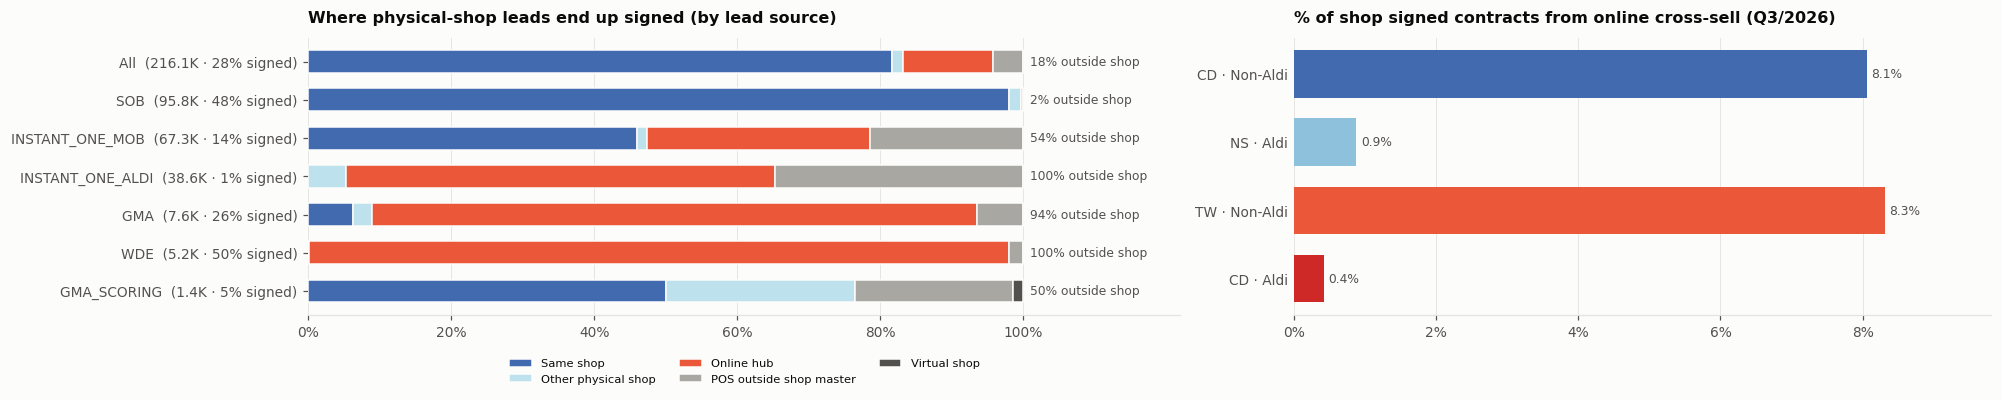

Lead (không RTDM) của shop vật lý giao 01–08/2026: 216,070; 28.0% ra HĐ ký trong 30 ngày, trong đó 18% ký ngoài shop tạo lead (online hub 13%). Q3/2026: 6.1% HĐ của shop đến từ bán chéo online (1,680 HĐ/tháng); 30% shop có ít nhất 1 HĐ bán chéo.


In [49]:
# 8.2a phễu lead theo shop gốc: lead của shop vật lý (bỏ RTDM, giao 01–08/2026) → hồ sơ → HĐ ký → nơi ký
con.sql(f"""CREATE OR REPLACE TABLE ctr_all AS
SELECT skp_credit_case, skp_salesroom, product, is_signed, name_status, date_apply FROM {rd('contract')}""")
con.sql("""CREATE OR REPLACE TABLE hub AS SELECT skp_salesroom FROM ctr_all WHERE is_signed AND name_status <> 'Cancelled'
           GROUP BY 1 HAVING count(*) >= 50000""")
con.sql(f"CREATE OR REPLACE TABLE lnk AS SELECT * FROM {rd('lead_contract_link')} WHERE match_apply OR match_sign")
NOI_KY = ['Cùng shop', 'Shop vật lý khác', 'Online hub', 'POS ngoài danh sách shop', 'Shop ảo (Virtual)']
con.sql(f"""CREATE OR REPLACE TABLE fl AS
SELECT l.lead_id, l.id_lead_source, l.lead_flow, l.p, l.w, s.seg, l.converted_apply, l.converted_sign,
       CASE WHEN NOT l.converted_sign THEN NULL
            WHEN c.skp_salesroom = l.skp_salesroom THEN 'Cùng shop'
            WHEN s2.category IN ('Big','Medium','Small') THEN 'Shop vật lý khác'
            WHEN s2.skp_salesroom IS NOT NULL THEN 'Shop ảo (Virtual)'
            WHEN h.skp_salesroom IS NOT NULL THEN 'Online hub' ELSE 'POS ngoài danh sách shop' END noi_ky
FROM lds l JOIN shop s USING (skp_salesroom)
LEFT JOIN (SELECT lead_id, skp_credit_case FROM lnk WHERE match_sign) k USING (lead_id) LEFT JOIN ctr_all c ON c.skp_credit_case = k.skp_credit_case
LEFT JOIN shop s2 ON s2.skp_salesroom = c.skp_salesroom LEFT JOIN hub h ON h.skp_salesroom = c.skp_salesroom
WHERE s.category IN ('Big','Medium','Small') AND l.id_lead_source <> 'INSTANT_TWO_RTDM' AND {MAT}""")
NK_ = ', '.join(f"coalesce(sum(w) FILTER (WHERE noi_ky = '{n_}'), 0) / nullif(sum(w) FILTER (WHERE converted_sign), 0) \"{n_}\"" for n_ in NOI_KY)
fun = q(f'''SELECT id_lead_source nguon, lead_flow, sum(w) lead,
              sum(w) FILTER (WHERE converted_apply) / sum(w) ho_so, sum(w) FILTER (WHERE converted_sign) / sum(w) hd_ky, {NK_}
            FROM fl GROUP BY ALL HAVING sum(w) >= 500 ORDER BY lead DESC''').set_index('nguon')
tot_ = q(f'''SELECT '' lead_flow, sum(w) lead, sum(w) FILTER (WHERE converted_apply) / sum(w) ho_so,
               sum(w) FILTER (WHERE converted_sign) / sum(w) hd_ky, {NK_} FROM fl''').assign(nguon='Toàn bộ').set_index('nguon')
fun = pd.concat([tot_, fun])
display(fun.style.format('{:.1%}', subset=['ho_so', 'hd_ky'] + NOI_KY, na_rep='–').format('{:,.0f}', subset=['lead']))

# 8.2b HĐ của shop theo 2 cơ chế (Q3/2026, theo tháng nộp): trực tiếp tại shop vs bán chéo online qua lead của shop
con.sql("""CREATE OR REPLACE TABLE xs AS
SELECT k.skp_credit_case, l.skp_salesroom lead_shop
FROM lnk k JOIN lds l USING (lead_id)
WHERE l.id_lead_source <> 'INSTANT_TWO_RTDM' AND l.skp_salesroom IN (SELECT skp_salesroom FROM shop WHERE category <> 'Virtual')
  AND k.skp_credit_case NOT IN (SELECT skp_credit_case FROM ctr_all JOIN shop USING (skp_salesroom) WHERE category <> 'Virtual')
QUALIFY row_number() OVER (PARTITION BY k.skp_credit_case ORDER BY k.is_system_link DESC, k.date_assigned DESC) = 1""")
mech = q(f'''WITH ok AS (SELECT * FROM ctr_all WHERE is_signed AND name_status <> 'Cancelled'
                         AND date_apply >= {Q3[0]} AND date_apply < DATE '2026-10-01'),
              d AS (SELECT skp_salesroom, count(*) / 3 truc_tiep FROM ok GROUP BY 1),
              x AS (SELECT lead_shop skp_salesroom, count(*) / 3 ban_cheo FROM ok JOIN xs USING (skp_credit_case) GROUP BY 1)
         SELECT cur.seg, cur.skp_salesroom, coalesce(truc_tiep, 0) truc_tiep, coalesce(ban_cheo, 0) ban_cheo
         FROM cur LEFT JOIN d USING (skp_salesroom) LEFT JOIN x USING (skp_salesroom)''')
mg = mech.assign(co_bc=mech.ban_cheo > 0).groupby('seg').agg(shop=('skp_salesroom', 'size'), truc_tiep=('truc_tiep', 'sum'),
                                                            ban_cheo=('ban_cheo', 'sum'), co_bc=('co_bc', 'mean')).reindex(SEG)
mg.loc['Toàn bộ'] = [len(mech), mech.truc_tiep.sum(), mech.ban_cheo.sum(), mech.ban_cheo.gt(0).mean()]
mt = pd.DataFrame({'Shop': mg.shop, 'HĐ trực tiếp / tháng': mg.truc_tiep, 'HĐ bán chéo online / tháng': mg.ban_cheo,
                   '% HĐ từ bán chéo': mg.ban_cheo / (mg.truc_tiep + mg.ban_cheo),
                   'HĐ trực tiếp / shop': mg.truc_tiep / mg.shop, 'HĐ bán chéo / shop': mg.ban_cheo / mg.shop, '% shop có bán chéo': mg.co_bc})
display(mt.style.format('{:,.0f}', subset=['Shop', 'HĐ trực tiếp / tháng', 'HĐ bán chéo online / tháng'])
          .format('{:.1%}', subset=['% HĐ từ bán chéo', '% shop có bán chéo']).format('{:.2f}', subset=['HĐ trực tiếp / shop', 'HĐ bán chéo / shop']))

fig, ax = plt.subplots(1, 2, figsize=(18, 3.8), gridspec_kw={'width_ratios': [1.25, 1]})
fs = fun.fillna(0)
y = np.arange(len(fs)); left = np.zeros(len(fs))
for n_ in NOI_KY:
    ax[0].barh(y, fs[n_], left=left, color=NCOL[n_], label=n_, height=.6, edgecolor=SURF); left += fs[n_].values
for yi, v_, s_ in zip(y, fs['Cùng shop'], left):
    if s_: ax[0].text(1.01, yi, f'{1 - v_:.0%} ngoài shop', va='center', fontsize=8, color=INK2)
ax[0].set_yticks(y, [f'{i}  ({human(r.lead)} · ký {r.hd_ky:.0%})' for i, r in fs.iterrows()]); ax[0].invert_yaxis()
ax[0].xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax[0].set_xlim(0, 1.22); ax[0].set_xticks(np.arange(0, 1.01, .2)); ax[0].grid(axis='y', visible=False)
ax[0].legend(ncol=3, loc='upper center', bbox_to_anchor=(.5, -.12), fontsize=7.5); ax[0].set_title('Lead của shop vật lý ra HĐ ký ở đâu (theo nguồn lead)')
mp = mt.loc[SEG]
barh(ax[1], mp.index, mp['% HĐ từ bán chéo'],
     '% HĐ ký của shop đến từ bán chéo online (Q3/2026)', color=[SEGCOL[x] for x in mp.index], fmt=lambda v: f'{v:.1%}')
ax[1].xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
plt.tight_layout(); plt.show()

t_ = fun.loc['Toàn bộ']; tm_ = mt.loc['Toàn bộ']
print(f"Lead (không RTDM) của shop vật lý giao 01–08/2026: {t_.lead:,.0f}; {t_.hd_ky:.1%} ra HĐ ký trong 30 ngày, "
      f"trong đó {1 - t_['Cùng shop']:.0%} ký ngoài shop tạo lead (online hub {t_['Online hub']:.0%}). "
      f"Q3/2026: {tm_['% HĐ từ bán chéo']:.1%} HĐ của shop đến từ bán chéo online ({tm_['HĐ bán chéo online / tháng']:,.0f} HĐ/tháng); "
      f"{tm_['% shop có bán chéo']:.0%} shop có ít nhất 1 HĐ bán chéo.")

## 9. Chất lượng danh mục – tỷ lệ trễ hạn
`flag_any_dpd` = trễ ít nhất một trong kỳ 1–4. HĐ ký từ **06/2026** chưa đủ thời gian để trễ (vùng xám).

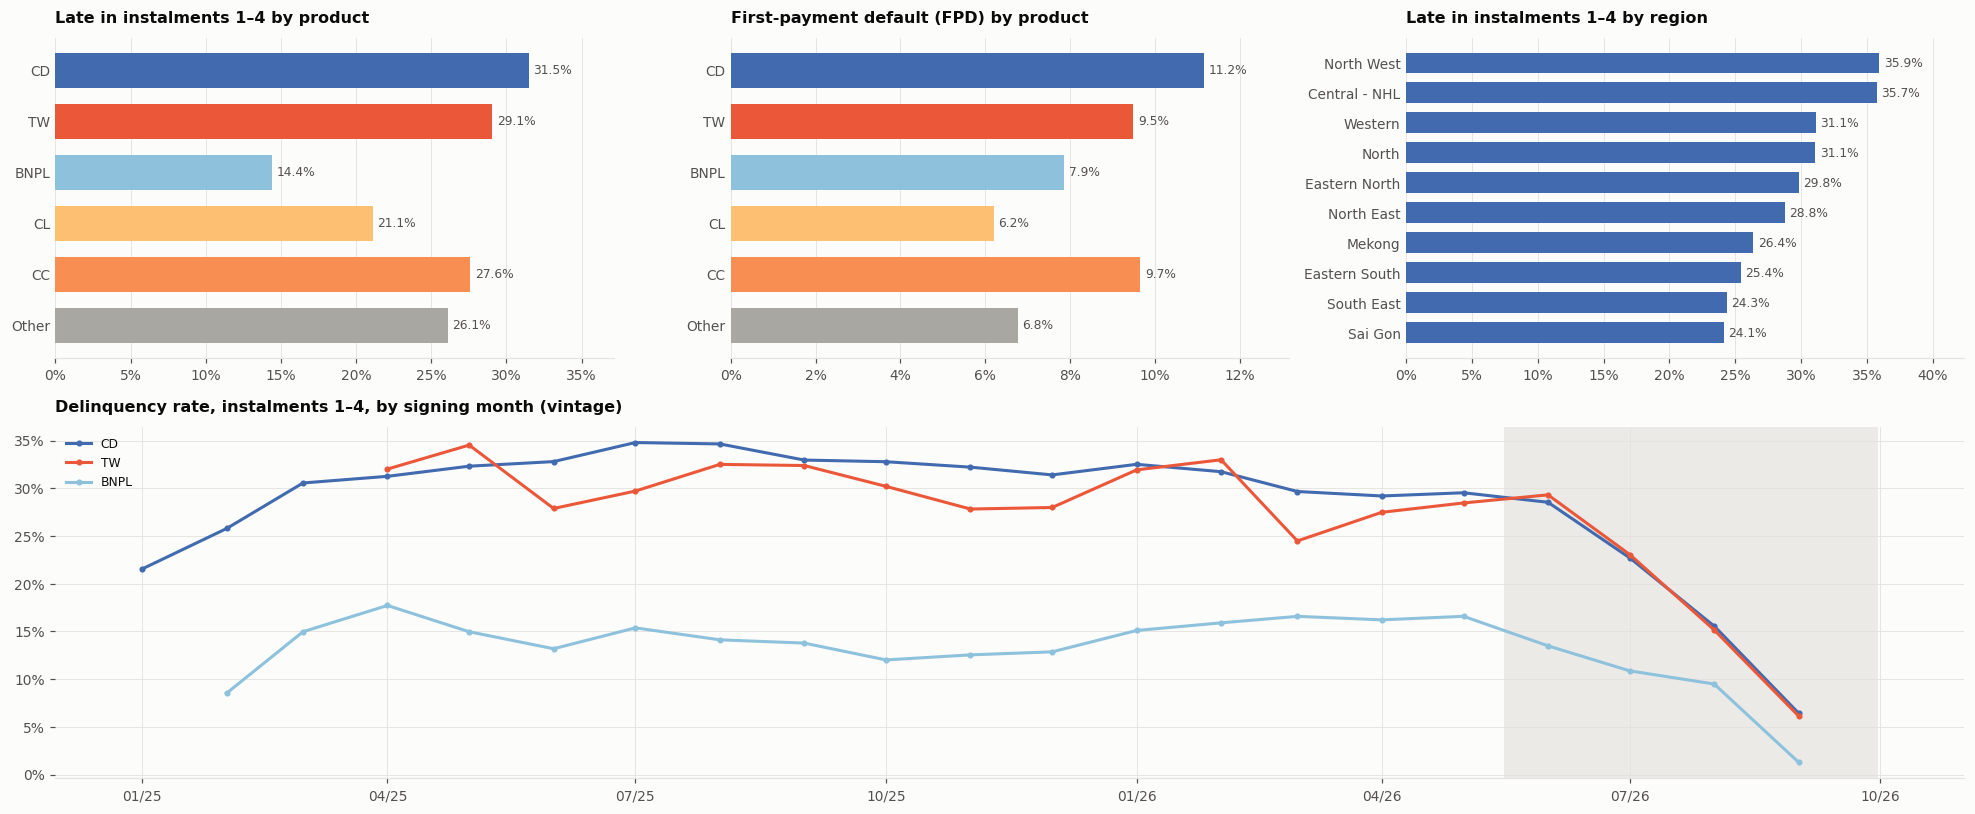

In [50]:
dv = q('''SELECT date_trunc('month', date_sign)::DATE thang, prod, 100 * avg(flag_any_dpd) dpd, count(*) n
          FROM ctr WHERE is_signed AND prod IN ('CD','TW','BNPL') GROUP BY ALL ORDER BY 1''')
dpd_p = q('''SELECT prod, 100 * avg(flag_any_dpd) dpd, 100 * avg(flag_dpd_1pd) fpd FROM ctr
             WHERE is_signed AND date_sign < DATE '2026-06-01' GROUP BY 1''').set_index('prod').reindex(PORDER).dropna(how='all').reset_index()
dpd_a = q('''SELECT area, 100 * avg(flag_any_dpd) dpd FROM ctr WHERE is_signed AND date_sign < DATE '2026-06-01' GROUP BY 1 ORDER BY 2 DESC''')
fig = plt.figure(figsize=(18, 7.5)); gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.1])
ax0 = fig.add_subplot(gs[0, 0]); ax1 = fig.add_subplot(gs[0, 1]); ax2 = fig.add_subplot(gs[0, 2])
barh(ax0, dpd_p['prod'], dpd_p.dpd, 'Trễ hạn kỳ 1–4 theo sản phẩm', pct=True, color=[PCOL.get(x, GREY) for x in dpd_p['prod']])
barh(ax1, dpd_p['prod'], dpd_p.fpd, 'Trễ ngay kỳ đầu (FPD) theo sản phẩm', pct=True, color=[PCOL.get(x, GREY) for x in dpd_p['prod']])
barh(ax2, dpd_a.area, dpd_a.dpd, 'Trễ hạn kỳ 1–4 theo vùng', pct=True)
ax3 = fig.add_subplot(gs[1, :])
for p in ['CD', 'TW', 'BNPL']:
    d = dv[(dv['prod'] == p) & (dv.n >= 200)]
    x = pd.to_datetime(d.thang)
    ax3.plot(x, d.dpd, color=PCOL[p], marker='o', markersize=3, label=p)
ax3.axvspan(pd.Timestamp('2026-05-16'), pd.Timestamp('2026-09-30'), color=GRID, alpha=.7, lw=0)
ax3.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax3.legend(loc='upper left')
ax3.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%m/%y'))
ax3.set_title('Tỷ lệ trễ hạn kỳ 1–4 theo tháng ký (vintage)')
plt.tight_layout(); plt.show()

#### Trễ hạn tách riêng từng kỳ 1–4 theo tháng ký (chỉ HĐ đã đủ tuổi quan sát)
Mỗi đường là tỷ lệ HĐ bị trễ ở **kỳ đó**. Chỉ tính HĐ ký đến 05/2026, vì HĐ ký sau đó chưa đến hạn đủ 4 kỳ.

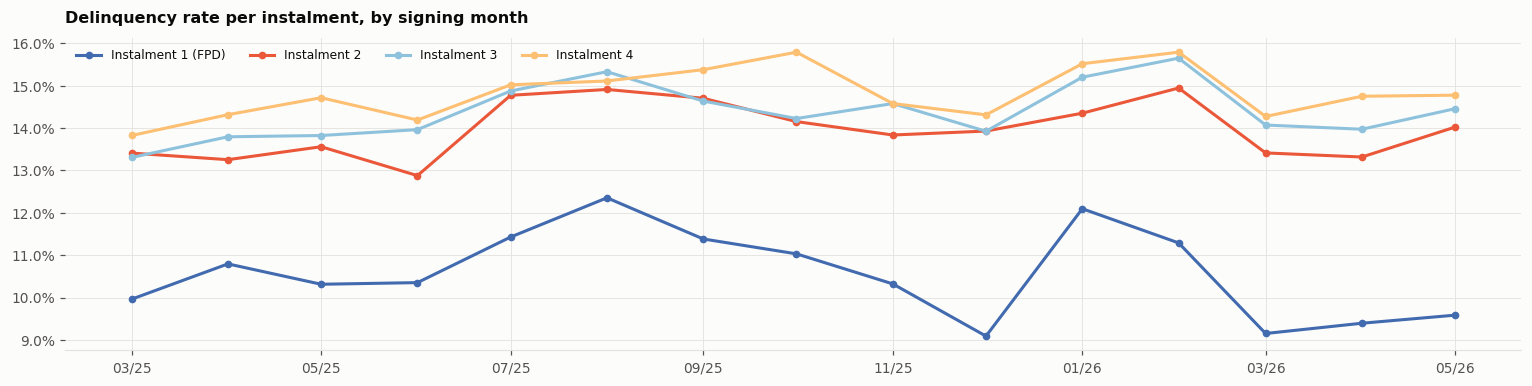

Gộp HĐ ký 03/2025–05/2026: {'k1': '10.5%', 'k2': '14.0%', 'k3': '14.5%', 'k4': '14.9%', 'bat_ky': '29.1%'}


In [51]:
vk = q('''SELECT m_sign thang, count(*) n, avg(flag_dpd_1pd) k1, avg(flag_dpd_2pd) k2, avg(flag_dpd_3pd) k3, avg(flag_dpd_4pd) k4, avg(flag_any_dpd) bat_ky
          FROM ctr WHERE is_signed AND name_status <> 'Cancelled' AND m_sign BETWEEN DATE '2025-03-01' AND DATE '2026-05-01'
          GROUP BY 1 ORDER BY 1''')
fig, ax = plt.subplots(figsize=(14, 3.6))
for col_, lab_, c_ in [('k1', 'Kỳ 1 (FPD)', BLUE), ('k2', 'Kỳ 2', ORANGE), ('k3', 'Kỳ 3', AQUA), ('k4', 'Kỳ 4', YELLOW)]:
    ax.plot(pd.to_datetime(vk.thang), vk[col_], marker='o', ms=4, color=c_, label=lab_)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.legend(ncol=4, loc='upper left')
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%m/%y')); ax.set_title('Tỷ lệ trễ hạn theo từng kỳ, theo tháng ký')
plt.tight_layout(); plt.show()
tot_ = (vk[['k1', 'k2', 'k3', 'k4', 'bat_ky']].mul(vk.n, axis=0).sum() / vk.n.sum())
print('Gộp HĐ ký 03/2025–05/2026:', {k_: f'{v_:.1%}' for k_, v_ in tot_.items()})

### 9.1 Năng suất có đi kèm rủi ro?

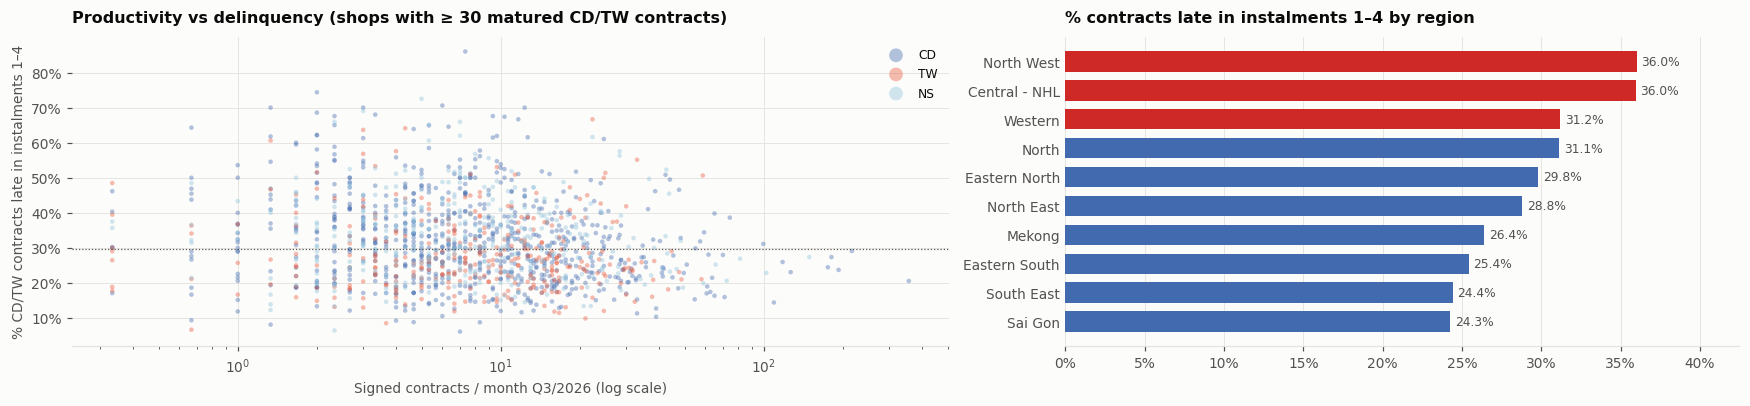

Tương quan Spearman năng suất – trễ hạn: -0.153
Shop năng suất top 25% có DPD > P75: 58 shop


In [52]:
rk = q('''WITH r AS (SELECT skp_salesroom, count(*) n, 100 * avg(flag_any_dpd) dpd FROM ctr
                    WHERE is_signed AND m_sign BETWEEN DATE '2025-03-01' AND DATE '2026-05-01' AND product IN ('CD','TW') GROUP BY 1 HAVING count(*) >= 30)
          SELECT r.*, c.sign_m, c.line, c.area FROM r JOIN cur c USING (skp_salesroom)''')
ra = q('''SELECT s.area, 100 * avg(flag_any_dpd) dpd, count(*) n FROM ctr JOIN shop s USING (skp_salesroom)
          WHERE is_signed AND m_sign BETWEEN DATE '2025-03-01' AND DATE '2026-05-01' GROUP BY 1 ORDER BY 2 DESC''')
fig, ax = plt.subplots(1, 2, figsize=(16, 3.8), gridspec_kw={'width_ratios': [1.3, 1]})
for ln in ['CD', 'TW', 'NS']:
    d = rk[rk.line == ln]
    ax[0].scatter(d.sign_m, d.dpd, s=9, alpha=.4, color=LCOL[ln], label=ln, edgecolor='none')
ax[0].axhline(rk.dpd.median(), color=INK2, lw=.8, ls=':')
ax[0].set_xscale('log'); ax[0].set_xlabel('HĐ ký / tháng Q3/2026 (thang log)'); ax[0].set_ylabel('% HĐ CD/TW trễ kỳ 1–4')
ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:.0f}%')); ax[0].legend(loc='upper right', markerscale=3)
ax[0].set_title('Năng suất vs tỷ lệ trễ hạn (shop ≥ 30 HĐ CD/TW đủ tuổi)')
barh(ax[1], ra.area, ra.dpd, '% HĐ trễ kỳ 1–4 theo vùng', pct=True, color=[RED if v >= ra.dpd.quantile(.7) else BLUE for v in ra.dpd])
plt.tight_layout(); plt.show()
print('Tương quan Spearman năng suất – trễ hạn:', round(rk[['sign_m', 'dpd']].corr(method='spearman').iloc[0, 1], 3))
print('Shop năng suất top 25% có DPD > P75:', f"{((rk.sign_m >= rk.sign_m.quantile(.75)) & (rk.dpd > rk.dpd.quantile(.75))).sum():,}", 'shop')

### 9.2 Rủi ro theo phân khúc lớn (vintage theo tháng ký)
Chỉ HĐ ký 03/2025–05/2026 (đủ tuổi quan sát 4 kỳ). Tháng có < 200 HĐ của phân khúc bị bỏ.

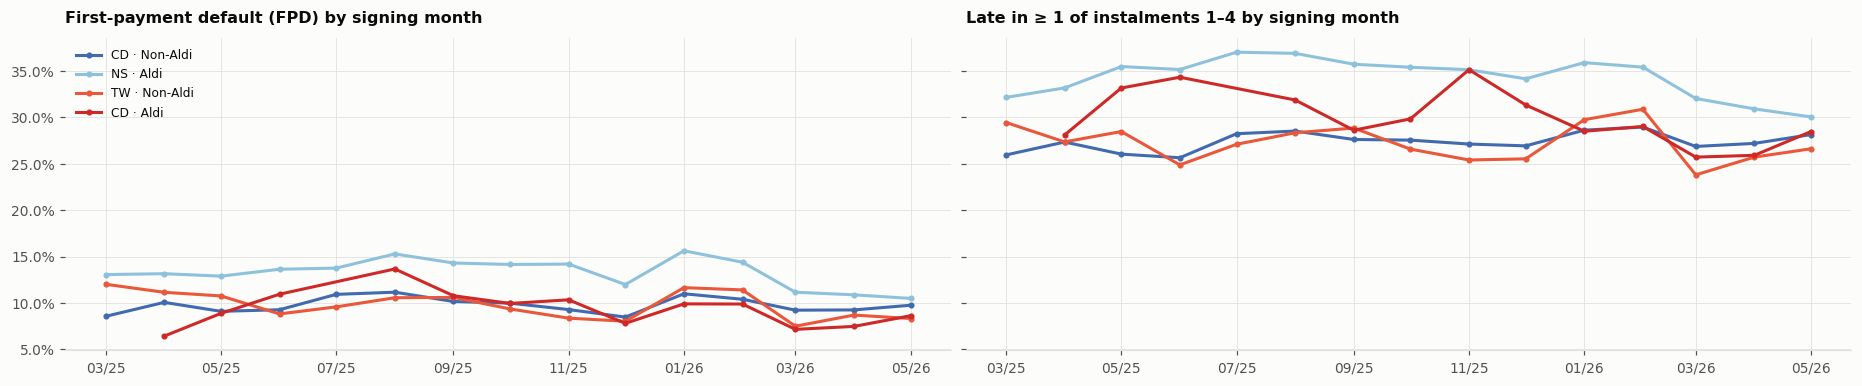

,HĐ đủ tuổi,FPD,Trễ kỳ 1–4
seg,,,
CD · Non-Aldi,"145,625",9.8%,27.6%
NS · Aldi,"65,576",13.1%,34.1%
TW · Non-Aldi,"53,645",9.3%,26.8%
CD · Aldi,"10,666",9.0%,28.8%


In [53]:
rv = q(f'''SELECT m_sign, seg, count(*) n, avg(flag_dpd_1pd) fpd, avg(flag_any_dpd) dpd FROM ctr
           WHERE is_signed AND name_status <> 'Cancelled' AND seg IN {tuple(SEG)} AND m_sign BETWEEN DATE '2025-03-01' AND DATE '2026-05-01'
           GROUP BY ALL HAVING count(*) >= 200 ORDER BY 1''')
fig, ax = plt.subplots(1, 2, figsize=(17, 3.6), sharey=True)
for a, col, t in [(ax[0], 'fpd', 'Trễ kỳ đầu (FPD) theo tháng ký'), (ax[1], 'dpd', 'Trễ ≥ 1 kỳ trong kỳ 1–4 theo tháng ký')]:
    for sg in SEG:
        d = rv[rv.seg == sg]; a.plot(pd.to_datetime(d.m_sign), d[col], color=SEGCOL[sg], marker='o', ms=3, label=sg)
    a.set_title(t); a.yaxis.set_major_formatter(mtick.PercentFormatter(1)); a.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%m/%y'))
ax[0].legend(loc='upper left')
plt.tight_layout(); plt.show()
rp = rv.assign(f_=rv.fpd * rv.n, d_=rv.dpd * rv.n).groupby('seg')[['n', 'f_', 'd_']].sum().reindex(SEG)
display(pd.DataFrame({'HĐ đủ tuổi': rp.n, 'FPD': rp.f_ / rp.n, 'Trễ kỳ 1–4': rp.d_ / rp.n}).style.format({'HĐ đủ tuổi': '{:,.0f}', 'FPD': '{:.1%}', 'Trễ kỳ 1–4': '{:.1%}'}))

## 10. Trả lời: Current Actual – các cửa hàng đang đạt được gì?

In [54]:
# số liệu tổng hợp tính lại trực tiếp; riêng kênh, năng suất theo giá trị, khách hàng và bán chéo lấy từ mục 1.0, 3.7, 5.2 và 8.2
net = con.sql('''SELECT count(*) FILTER (WHERE salesroom_category <> 'Virtual' AND (salesroom_end IS NULL OR salesroom_end >= DATE '2026-10-01')
                                         AND salesroom_start < DATE '2026-10-01') shop_mo FROM salesroom''').df().iloc[0]
k3 = con.sql('''SELECT count(*) / 3 ho_so, count(*) FILTER (WHERE is_signed AND name_status <> 'Cancelled') / 3 hd,
                       sum(loan_amount_eff) FILTER (WHERE is_signed AND name_status <> 'Cancelled') / 3 val,
                       avg((name_status = 'Rejected')::INT) tu_choi, avg((name_status = 'Cancelled')::INT) huy,
                       count(*) FILTER (WHERE is_signed AND name_status <> 'Cancelled') * 1.0 / count(*) ky,
                       count(*) FILTER (WHERE is_signed AND name_status <> 'Cancelled') * 1.0
                         / count(*) FILTER (WHERE (is_signed AND name_status <> 'Cancelled') OR name_status = 'Rejected') duyet_tren,
                       median(date_diff('minute', date_apply, date_sign)) FILTER (WHERE is_signed AND name_status <> 'Cancelled') phut
                FROM ctr WHERE date_apply >= DATE '2026-07-01' AND date_apply < DATE '2026-10-01'
                  AND skp_salesroom IN (SELECT skp_salesroom FROM salesroom WHERE salesroom_category <> 'Virtual'
                                        AND (salesroom_end IS NULL OR salesroom_end >= DATE '2026-10-01')) ''').df().iloc[0]
sh = cons.sql('''SELECT s.skp_salesroom, s.line || ' · ' || s.model seg,
                        count(c.skp_salesroom) FILTER (WHERE c.ok AND c.date_apply >= '2026-07-01' AND c.date_apply < '2026-10-01') / 3 hd,
                        sum(c.loan_amount_eff) FILTER (WHERE c.ok AND c.date_apply >= '2026-07-01' AND c.date_apply < '2026-10-01') / 3 val
                 FROM shop s LEFT JOIN c USING (skp_salesroom) GROUP BY ALL''').df().fillna(0)
top = sh.hd.sort_values(ascending=False); t20 = top.head(int(len(top) * .2)).sum() / top.sum()
seg_ = sh.groupby('seg').agg(shop=('hd', 'size'), hd=('hd', 'sum'), val=('val', 'sum'))
seg_['%shop'] = seg_.shop / seg_.shop.sum(); seg_['%hd'] = seg_.hd / seg_.hd.sum(); seg_['%val'] = seg_.val / seg_.val.sum()
rk_ = cons.sql('''SELECT avg(flag_dpd_1pd) fpd, avg(flag_any_dpd) dpd FROM c WHERE ok AND date_sign >= '2025-10-01' AND date_sign < '2026-06-01' ''').df().iloc[0]
qq_ = con.sql('''WITH sc AS (SELECT skp_salesroom FROM salesroom WHERE salesroom_start < DATE '2026-04-01'
                             AND (salesroom_end IS NULL OR salesroom_end >= DATE '2026-10-01'))
                 SELECT count(*) FILTER (WHERE is_signed AND name_status <> 'Cancelled' AND date_apply >= DATE '2026-07-01') * 1.0
                      / count(*) FILTER (WHERE is_signed AND name_status <> 'Cancelled' AND date_apply < DATE '2026-07-01') - 1 g
                 FROM ctr WHERE skp_salesroom IN (SELECT skp_salesroom FROM sc) AND date_apply >= DATE '2026-04-01' AND date_apply < DATE '2026-10-01' ''').df().iloc[0]
gs_ = con.sql(f'''SELECT seg, sum(n_sign) FILTER (WHERE m >= DATE '2026-07-01') / 3 q3,
                         sum(n_sign) FILTER (WHERE m >= DATE '2026-04-01' AND m < DATE '2026-07-01') / 3 q2,
                         sum(n_sign) FILTER (WHERE m >= DATE '2025-07-01' AND m < DATE '2025-10-01') / 3 q3p
                  FROM sm_perf WHERE seg IN {tuple(SEG)} GROUP BY 1''').df().set_index('seg').reindex(SEG)
st_ = con.sql("SELECT stage, sum(n_sign) n FROM sm_perf WHERE m >= DATE '2026-07-01' GROUP BY 1").df().set_index('stage').n
pct_ = lambda a, b: f'{a / b - 1:+.0%}' if b else 'mới'
lines = [
 ('Toàn mạng lưới', f"{net.shop_mo:,.0f} shop vật lý đang mở ký {k3.hd:,.0f} HĐ/tháng, giá trị khoản vay đã ký {k3.val / 1e9:,.0f} tỷ đ/tháng "
                    f"(Q3/2026); cùng tập shop đủ 2 quý: HĐ ký {qq_.g:+.1%} so với Q2."),
 ('Shop điển hình', f"Shop trưởng thành trung vị ký {sh.hd.median():.2f} HĐ/tháng; {(sh.hd == 0).mean():.0%} shop không có HĐ nào trong quý; "
                    f"20% shop tạo {t20:.0%} HĐ → kết quả rất tập trung."),
 ('Theo phân khúc', '; '.join(f"{i}: {r['%shop']:.0%} shop · {r['%hd']:.0%} HĐ · {r['%val']:.0%} giá trị" for i, r in seg_.sort_values('shop', ascending=False).iterrows())),
 ('Tăng trưởng theo phân khúc', '; '.join(f"{i}: {r.q3:,.0f} HĐ ký/tháng, QoQ {pct_(r.q3, r.q2)}, YoY {pct_(r.q3, r.q3p)}" for i, r in gs_.iterrows())
                                 + ' (tách mạng lưới / năng suất: mục 3.5).'),
 ('Vị trí trong công ty', f"Shop vật lý chiếm {tb_ch.loc['Shop vật lý', '% HĐ']:.0%} HĐ thành công và {tb_ch.loc['Shop vật lý', '% giá trị']:.0%} "
                          f"giá trị khoản vay đã ký toàn công ty (Q3/2026); phần còn lại ở online hub và POS ngoài danh sách (mục 1.0)."),
 ('Năng suất theo giá trị', f"Shop ≥ 3 tháng tuổi, Q3/2026 so với Q3/2025: HĐ/shop {tt[('Thay đổi', 'HĐ / shop / tháng')]:+.0%}, "
                            f"khoản vay BQ {tt[('Thay đổi', 'Khoản vay BQ (tr)')]:+.0%}, giá trị/shop {tt[('Thay đổi', 'Giá trị / shop / tháng (tr)')]:+.0%}: "
                            f"shop không bán nhiều HĐ hơn, nhưng mỗi HĐ lớn hơn (mục 3.7)."),
 ('Khách hàng', f"{1 - (nr.khach * nr.ty_le_khach_cu).sum() / nr.khach.sum():.0%} khách có HĐ tại shop Q3/2026 là khách mới; "
                f"{xs_tot['% vay thêm trong 12 tháng']:.1%} khách CD/TW lần đầu tại shop vay thêm CL/CC/CW trong 12 tháng, "
                f"{1 - xs_tot['nơi vay: Cùng shop']:.0%} trong số đó vay ở nơi khác (mục 5.2)."),
 ('Bán chéo sang online', f"{tm_['% HĐ từ bán chéo']:.1%} HĐ của shop (Q3/2026) là HĐ ký online từ lead của shop; "
                           f"{1 - t_['Cùng shop']:.0%} lead ra HĐ của shop vật lý được ký ngoài shop tạo lead (mục 8.2)."),
 ('Theo vòng đời', f"Q3/2026: shop < 6 tháng tuổi tạo {st_.reindex(STAGES[:2]).sum() / st_.sum():.0%} HĐ ký, shop ổn định (≥ 6 tháng) {st_.get(STAGES[2], 0) / st_.sum():.0%} (mục 3.6)."),
 ('Phễu', f"{k3.ho_so:,.0f} hồ sơ/tháng tại các shop này; tỷ lệ ký {k3.ky:.1%}, bị từ chối {k3.tu_choi:.1%}, huỷ {k3.huy:.1%}; tỷ lệ duyệt trong khoảng "
          f"{k3.ky:.1%}–{k3.duyet_tren:.1%}; nộp → ký trung vị {k3.phut:.0f} phút."),
 ('Chất lượng', f"HĐ ký 10/2025–05/2026: trễ kỳ đầu {rk_.fpd:.1%}, trễ ≥ 1 kỳ trong 4 kỳ đầu {rk_.dpd:.1%}."),
 ('Shop tốt vs kém (cùng phân khúc)', "Khác nhau chủ yếu ở số hồ sơ (nhóm cao gấp ~8 lần nhóm thấp); tỷ lệ không bị từ chối, tỷ lệ hoàn tất, "
                                       "thời gian xử lý, SA quy đổi và FPD gần như bằng nhau (mục 7.8)."),
]
ans = pd.DataFrame(lines, columns=['Khía cạnh', 'Current Actual'])
with pd.option_context('display.max_colwidth', None):
    display(ans.style.set_properties(**{'text-align': 'left', 'white-space': 'pre-wrap'}).hide(axis='index'))

Khía cạnh,Current Actual
Toàn mạng lưới,"11,795 shop vật lý đang mở ký 38,041 HĐ/tháng, giá trị khoản vay đã ký 529 tỷ đ/tháng (Q3/2026); cùng tập shop đủ 2 quý: HĐ ký +2.8% so với Q2."
Shop điển hình,Shop trưởng thành trung vị ký 0.67 HĐ/tháng; 34% shop không có HĐ nào trong quý; 20% shop tạo 79% HĐ → kết quả rất tập trung.
Theo phân khúc,CD · Non-Aldi: 55% shop · 51% HĐ · 42% giá trị; NS · Aldi: 26% shop · 23% HĐ · 22% giá trị; TW · Non-Aldi: 19% shop · 21% HĐ · 32% giá trị; CD · Aldi: 0% shop · 5% HĐ · 4% giá trị
Tăng trưởng theo phân khúc,"CD · Non-Aldi: 18,921 HĐ ký/tháng, QoQ +19%, YoY +124%; NS · Aldi: 9,548 HĐ ký/tháng, QoQ +32%, YoY +112%; TW · Non-Aldi: 7,520 HĐ ký/tháng, QoQ +29%, YoY +182%; CD · Aldi: 2,914 HĐ ký/tháng, QoQ +45%, YoY +617% (tách mạng lưới / năng suất: mục 3.5)."
Vị trí trong công ty,Shop vật lý chiếm 28% HĐ thành công và 19% giá trị khoản vay đã ký toàn công ty (Q3/2026); phần còn lại ở online hub và POS ngoài danh sách (mục 1.0).
Năng suất theo giá trị,"Shop ≥ 3 tháng tuổi, Q3/2026 so với Q3/2025: HĐ/shop -3%, khoản vay BQ +24%, giá trị/shop +20%: shop không bán nhiều HĐ hơn, nhưng mỗi HĐ lớn hơn (mục 3.7)."
Khách hàng,"83% khách có HĐ tại shop Q3/2026 là khách mới; 9.1% khách CD/TW lần đầu tại shop vay thêm CL/CC/CW trong 12 tháng, 95% trong số đó vay ở nơi khác (mục 5.2)."
Bán chéo sang online,6.1% HĐ của shop (Q3/2026) là HĐ ký online từ lead của shop; 18% lead ra HĐ của shop vật lý được ký ngoài shop tạo lead (mục 8.2).
Theo vòng đời,"Q3/2026: shop < 6 tháng tuổi tạo 38% HĐ ký, shop ổn định (≥ 6 tháng) 62% (mục 3.6)."
Phễu,"53,033 hồ sơ/tháng tại các shop này; tỷ lệ ký 71.7%, bị từ chối 20.5%, huỷ 7.8%; tỷ lệ duyệt trong khoảng 71.7%–77.8%; nộp → ký trung vị 12 phút."


**Dùng kết quả này thế nào ở các bước sau:**
- Current Actual của **từng shop** (HĐ ký và giá trị khoản vay đã ký mỗi tháng, phễu, rủi ro) là điểm xuất phát cho **BAU** (quý tới nếu giữ nguyên) và **Attainable** (nếu can thiệp).
- Vì shop cùng phân khúc khác nhau chủ yếu ở **lượng hồ sơ**, câu hỏi cần trả lời ở bước sau là: thiếu hồ sơ do **cầu tại chỗ** (thị trường, đối tác) hay do **thực thi** (hiện diện, sản phẩm, lead)?

> **Phạm vi kết luận:** đây là đánh giá **hoạt động bán hàng của mạng lưới shop mới** trong dữ liệu. Chưa có dữ liệu dư nợ, thu nhập lãi/phí, chi phí và nguồn vốn, nên **chưa kết luận được về sức khoẻ kinh doanh toàn công ty**.

## Phụ lục A – Địa lý & loại hình shop
Thông tin nền về mạng lưới; vùng chỉ dùng làm chiều phụ, không dùng làm trục phân tích chính (nhóm peer không chia theo vùng).

### A.1 Địa lý – vùng và tỉnh (34 tỉnh sau sáp nhập, cột `province_std`)

Số tỉnh (chuẩn hoá): 34


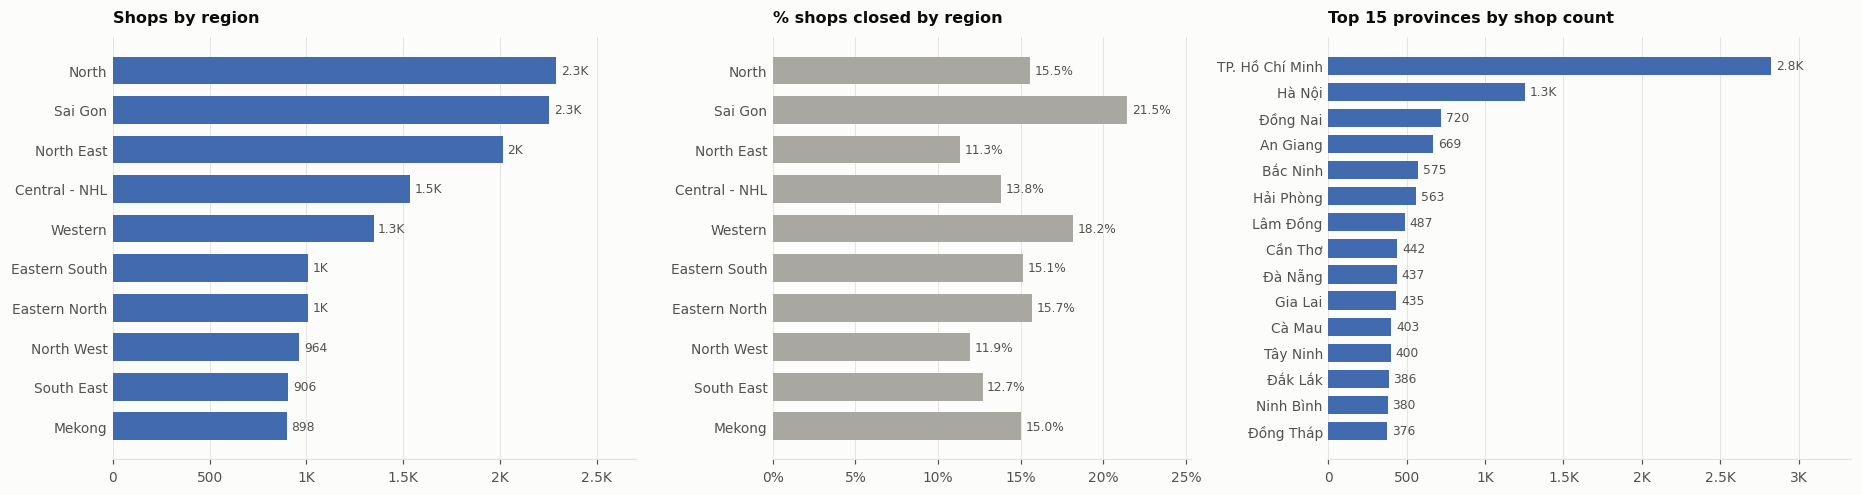

In [55]:
ar = q('''SELECT salesroom_area area, count(*) n, 100 * avg(is_closed::INT) closed FROM salesroom GROUP BY 1 ORDER BY 2 DESC''')
pv = q('''SELECT province_std, count(*) n FROM salesroom GROUP BY 1 ORDER BY 2 DESC LIMIT 15''')
print('Số tỉnh (chuẩn hoá):', q('SELECT count(DISTINCT province_std) FROM salesroom').iloc[0, 0])
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={'width_ratios': [1, .8, 1]})
barh(ax[0], ar.area, ar.n, 'Số shop theo vùng')
barh(ax[1], ar.area, ar.closed, '% shop đã đóng cửa theo vùng', pct=True, color=GREY)
barh(ax[2], pv.province_std, pv.n, 'Top 15 tỉnh theo số shop')
plt.tight_layout(); plt.show()

### A.2 Loại hình shop & đại lý

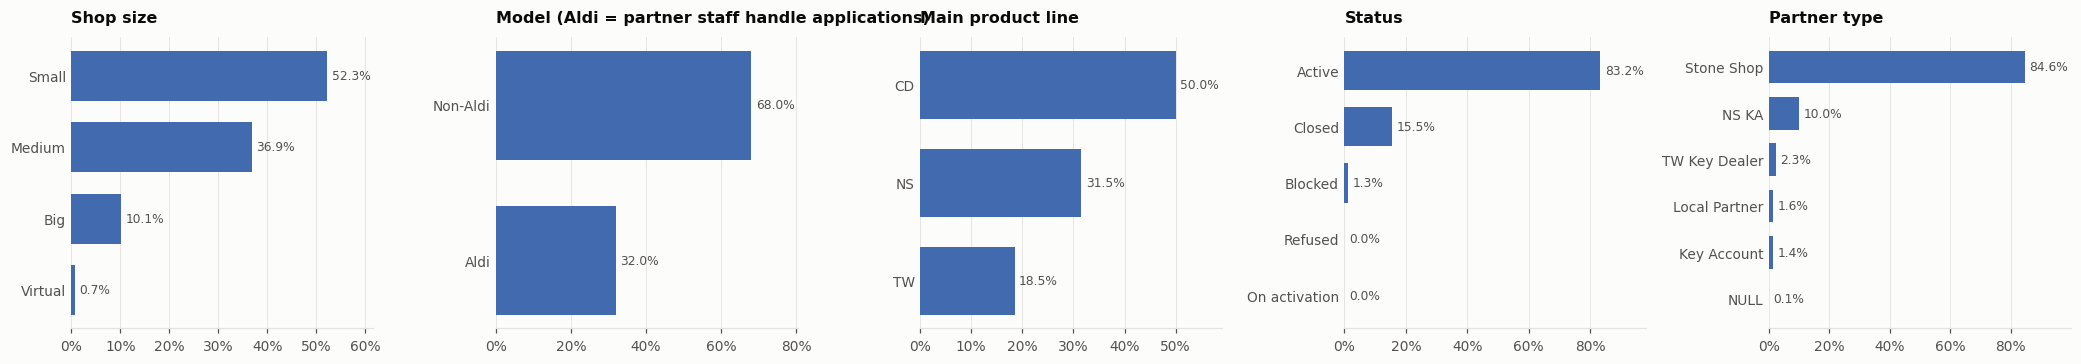

,salesroom_model,salesroom_product,salesroom_category,n_shop
0,Non-Aldi,CD,Small,4477
1,Aldi,NS,Medium,2137
2,Non-Aldi,CD,Medium,2097
3,Aldi,NS,Small,1824
4,Non-Aldi,TW,Small,1115
5,Non-Aldi,TW,Medium,991
6,Aldi,NS,Big,519
7,Non-Aldi,CD,Big,474
8,Non-Aldi,TW,Big,425
9,Non-Aldi,TW,Virtual,100


In [56]:
dims = [('salesroom_category', 'Quy mô shop'), ('salesroom_model', 'Mô hình (Aldi = NV shop tự làm HĐ)'),
        ('salesroom_product', 'Dòng hàng chính'), ('salesroom_status', 'Trạng thái'), ('seller_type', 'Loại đại lý')]
fig, axes = plt.subplots(1, 5, figsize=(19, 3.4))
for ax, (c, t) in zip(axes, dims):
    d = q(f'''SELECT coalesce({c}::VARCHAR, 'NULL') v, 100 * count(*) / sum(count(*)) OVER () p FROM salesroom GROUP BY 1 ORDER BY 2 DESC LIMIT 8''')
    barh(ax, d.v, d.p, t, pct=True, maxlen=18)
plt.tight_layout(); plt.show()
display(q('''SELECT salesroom_model, salesroom_product, salesroom_category, count(*) n_shop
             FROM salesroom GROUP BY ALL ORDER BY n_shop DESC LIMIT 12'''))

### A.3 Kết quả theo vùng

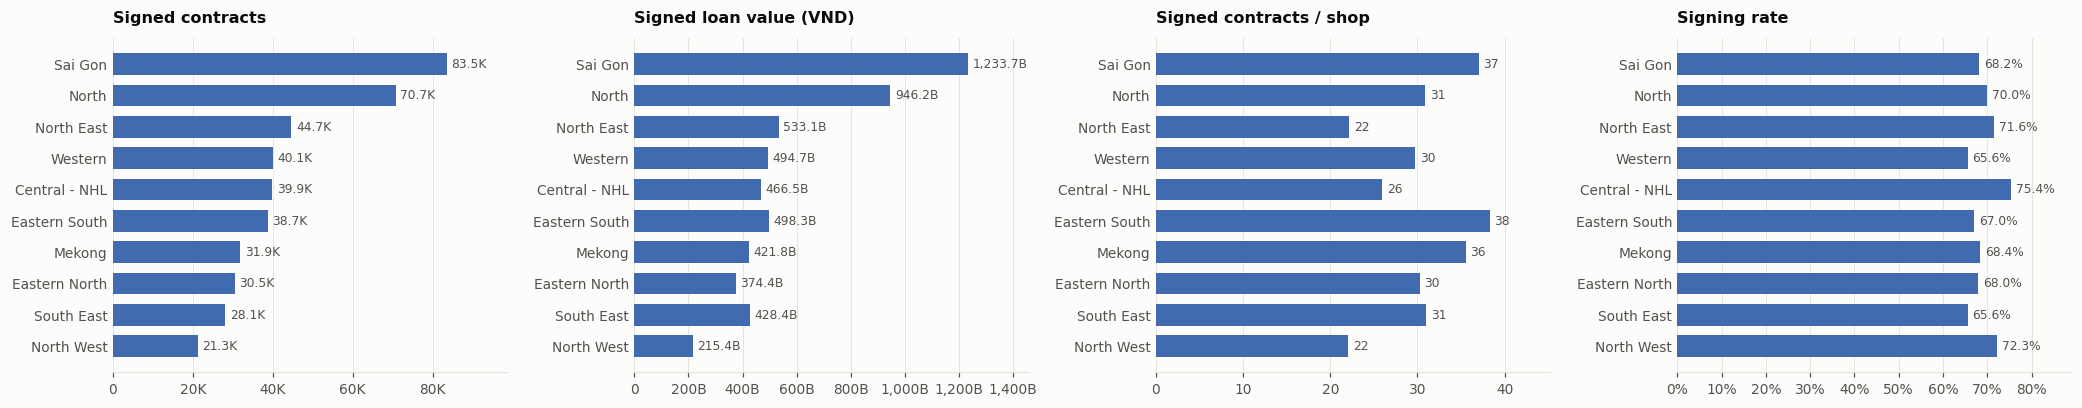

In [57]:
ra = q('''WITH s AS (SELECT salesroom_area area, count(*) n_shop FROM salesroom GROUP BY 1)
          SELECT area, n_shop, count(*) FILTER (WHERE is_signed) n_sign,
                 100 * avg(is_signed::INT) sign_rate,
                 sum(loan_amount_eff) FILTER (WHERE is_signed) amt
          FROM ctr JOIN s USING (area) GROUP BY ALL ORDER BY n_sign DESC''')
ra['sign_per_shop'] = ra.n_sign / ra.n_shop
fig, ax = plt.subplots(1, 4, figsize=(19, 3.8))
barh(ax[0], ra.area, ra.n_sign, 'HĐ đã ký')
barh(ax[1], ra.area, ra.amt, 'Giá trị khoản vay đã ký (VND)')
barh(ax[2], ra.area, ra.sign_per_shop, 'HĐ đã ký / shop', fmt=lambda v: f'{v:.0f}')
barh(ax[3], ra.area, ra.sign_rate, 'Tỷ lệ ký', pct=True)
plt.tight_layout(); plt.show()